# 03b · Tratamiento por tienda (experimental)

**Propósito:** probar si tratar los quiebres de stock e intermitencias a nivel **tienda × artículo**, antes de sumar al artículo, reduce los bloques atípicos que el nb 04 no logra corregir a nivel artículo, y seguir con el flujo del nb 04 sobre esa serie.

**Contexto:** cuando el artículo se cae en casi todas las tiendas y una sigue vendiendo poco, la suma del artículo nunca llega a cero. El quiebre queda escondido y aparece como un ratio extremo o un falso cambio de nivel (ejemplos: FOODS_3_388, bloques 15–26; FOODS_2_198, bloques 28–39).

**Alcance:** notebook **independiente y solo de experimentación**. No persiste resultados (D1), salvo dos excepciones: las entradas de los nb 03c y 03d (13.3) y los puntos de control de la búsqueda SARIMAX, para retomarla si se corta, el nb 04 no carga nada de aquí y no modifica lo congelado del nb 03 (`targets`, segmentos, `long_run`, `min_days`), que solo se lee. Si el enfoque se adopta, se hará con una enmienda de la constitución (definición de bloque no válido y flujo de notebooks).

**Etapas** (el estado de cada una vive en `specs/001-abc-xyz-share-forecast/nb03b-etapas.md`):

| # | Etapa | Nivel |
|---|---|---|
| 0 | Decisiones y reglas | — |
| 1 | Carga de lo congelado del nb 03, series por tienda y línea base (nb 04, Etapas 1–4) | — |
| 2 | Ciclo de vida por tienda (primera venta, días sin precio) | tienda × día |
| 3 | `long_run` por tienda y artículo (Bernoulli con train) | tienda × día |
| 4 | Quiebre frente a intermitencia (rachas y exceso de ceros), sin futuro en ventana y test | tienda × día |
| 5 | Imputación del bloque de tienda, ejemplos y 5.2 prueba de participación (Friedman, descartada) | tienda × bloque |
| 6 | Suma por artículo | artículo × día |
| 7 | Bloques de 28 días, 4.2, 4.2a, 4.2b, 4.3, 4.4 (nb 04, Etapa 4) y 7.5 comparación con la línea base | artículo × bloque |
| 8 | Variables de calendario (nb 04, Etapa 5) | artículo × bloque |
| 9 | Feature engineering: 6a, 6b, 6c, 6e (nb 04, Etapa 6) | artículo × bloque |
| 10 | Split temporal (nb 04, Etapa 7) | artículo × bloque |
| 11 | Datasets por modelo, sin exportar (nb 04, Etapa 9) | artículo × bloque |
| 12 | Folds de backtesting (nb 04, Etapa 10) | artículo × bloque |
| 13 | Línea base: seasonal naive, gráficos de series (nb 04, Etapa 11) y exportación para los nb 03c y 03d (13.3) | artículo × bloque |


## Etapa 0 · Decisiones y reglas

**Objetivo:** fijar qué se trata en cada nivel y con qué reglas, antes de escribir código.

**Decisiones (usuario, 2026-11-04):**

| # | Decisión | Justificación |
|---|---|---|
| D1 | Notebook independiente, solo experimentación; no persiste resultados ni alimenta al nb 04. Excepciones (usuario, 2026-11-06): los datasets, el seasonal naive y la escala del RMSSE que cargan los nb 03c y 03d (13.3, `data/interim/nb03b_datasets/`) y los puntos de control de la búsqueda SARIMAX (14.3, `data/interim/nb03b_sarimax/`). | Probar el enfoque sin contradecir la constitución vigente ni tocar el nb 04, que queda como línea base. La búsqueda dura horas: sin puntos de control, un corte la pierde entera. Exportar los datasets evita repetir el tratamiento en el 03c y deja correr las dos búsquedas a la vez. |
| D2 | La **detección** de quiebres es por **tienda × día**. | Las rachas y el umbral Bernoulli se miden en días (igual que el nb 03). Por tienda el quiebre no queda escondido por las ventas de otras tiendas. |
| D3 | La **validez e imputación** del bloque es por **tienda × bloque**, y después se suma al artículo. | Un bloque de tienda casi todo en quiebre no representa su venta; se completa con la venta reciente de esa tienda antes de sumar. |
| D4 | Las reglas de **bloque atípico** (4.2b, 4.4) y del ratio (6a) se aplican **solo a nivel artículo**, sobre la suma ya corregida. | Por tienda la señal es débil: en AZ el 24 % de los bloques de tienda tiene menos de 10 unidades y el 18 % está en cero (sin ratio). Ahí esas reglas imputarían ruido. |
| D5 | Código en un módulo nuevo, `src/store_treatment.py` (aprobado), con sus tests en `src/tests/`. | Separa el tratamiento por tienda del pipeline por artículo de `src/features.py`. |

**Reglas que se mantienen:**
- **R5 (sin fuga):** los umbrales por tienda se estiman solo con días de train. En la historia (bloques antes de la ventana de cada artículo) se usa solo lo observado antes de la ventana. En ventana y test, una racha cuenta como quiebre al cierre del bloque en que alcanza el umbral, sin saber si la tienda vuelve. La imputación usa solo días anteriores.
- **Lo congelado del nb 03 se carga, no se recalcula:** `targets`, segmento AX/AY/AZ, `long_run` y `min_days` por artículo. `long_run` por tienda es un parámetro **nuevo** de este experimento, no reemplaza al congelado.
- **R1–R8 de `CLAUDE.md`:** una etapa a la vez, celdas md → import → run → check, todo número justificado, piloto antes de procesos largos.

**Medida de éxito (Etapa 6), siempre por segmento como "teníamos / quedan":**
1. Bloques atípicos que quedan frente al nb 04 (143: AX 6, AY 41, AZ 96).
2. Cambios estructurales genuinos alterados (en el piloto, 12) frente a interrupciones corregidas (99).
3. Unidades agregadas por la imputación, por tramo (historia, ventana, test).

**Dudas abiertas, se resuelven en su etapa:**
- Etapa 2: cómo tratar una tienda que deja el artículo y no vuelve. En el piloto se rellenaba sin fin con su venta anterior; la ventana subió 9,2 % de unidades.
- Etapa 5: regla de validez del bloque de tienda (mínimo de días válidos) y su número.
- Etapa 6: medir contra lo observado o contra lo corregido en ventana y test (la misma duda de la Etapa 14 del nb 04).


## Configuración

**Qué hace:** fija la raíz del proyecto (rutas relativas), activa `%autoreload` para tomar los cambios de `src/` sin reiniciar el kernel, carga la configuración validada e imprime las versiones de Python y de las librerías (R6).
**Decisión:** este notebook no usa azar hasta la comparación con el boosting; la semilla se fija en esa etapa con el valor de `params.toml`.


In [1]:
%load_ext autoreload
%autoreload 2

import os
import platform
import sys
from importlib.metadata import version
from pathlib import Path

# Raíz del código: el notebook corre desde notebooks/.
CODE_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(CODE_ROOT))
os.chdir(os.environ.get("PROJECT_ROOT", CODE_ROOT))

import numpy as np
import pandas as pd
from IPython.display import display

from src.config import all_years, load_validated_config, train_end

pd.set_option("display.max_columns", 30)

cfg = load_validated_config()
years = all_years(cfg)
START_D, END_D = years["Y1"][0], years["Y5"][1]
TRAIN_END = train_end(cfg)
TEST_START = TRAIN_END + 1

LIBS = ["numpy", "pandas", "scipy", "scikit-learn", "statsmodels", "joblib", "matplotlib", "pyarrow", "tqdm", "ipywidgets"]
display(pd.Series({"python": platform.python_version(), **{lib: version(lib) for lib in LIBS}}, name="versión").to_frame())
display(pd.Series({"START_D": START_D, "TRAIN_END": TRAIN_END, "TEST_START": TEST_START, "END_D": END_D}, name="día").to_frame())


,versión
python,3.12.3
numpy,2.5.4
pandas,3.1.0
scipy,1.18.1
scikit-learn,1.9.1
statsmodels,0.15.0
joblib,1.6.0
matplotlib,3.11.2
pyarrow,26.0.0
tqdm,4.70.1


,día
START_D,122
TRAIN_END,1577
TEST_START,1578
END_D,1941


## Candado

**Qué hace:** detiene el notebook aquí si sus salidas ya están guardadas, para que un "Run All" accidental no repita el cálculo ni reemplace lo que usan los notebooks siguientes (datasets del 03c y el 03d; la búsqueda SARIMAX ya retoma sola por lotes).
**Para volver a ejecutar:** `RERUN = True`. Aun así, lo guardado solo se reemplaza si su contenido cambia **y** `OVERWRITE = True`; con `OVERWRITE = False` el guardado se detiene si el contenido es distinto y no escribe si es igual.

In [ ]:
from src.data import guard_rerun

RERUN = False       # True para volver a ejecutar aunque existan las salidas
OVERWRITE = False   # True solo para reemplazar lo guardado con contenido distinto
guard_rerun([Path("data/interim/nb03b_datasets/manifest.json"), Path("data/interim/nb03b_sarimax")], RERUN)

## Etapa 1 · Carga de lo congelado del nb 03, series por tienda y línea base

**Objetivo:** tener en memoria, sin leer nada del nb 04, (a) lo congelado del nb 03, (b) las series diarias por artículo y por tienda de los 592 artículos de `targets`, y (c) la línea base: el pipeline por artículo del nb 04 (tratamiento diario y Etapas 4.1–4.4) recalculado aquí con las mismas funciones y parámetros.
**Entradas:** `targets` congelado (nb 03), calendario, intermedios por artículo y por tienda (`load_interim`).
**Salidas:** `targets`, `item_cell`, `units_treated` (artículo × día, como el nb 04), `units_s` (tienda × artículo × día), `base` (Etapas 4.1–4.4 sin tratamiento por tienda), `ext_base` (bloques con ratio extremo) y `window_start` / `test_start` por artículo.
**Decisión:** la línea base se recalcula en este notebook, no se carga del nb 04 (D1: independientes). Debe reproducir los números del nb 04: 579 artículos modelados y 143 bloques atípicos (AX 6, AY 41, AZ 96). La partición por artículo (test = últimos 13 bloques, ventana = 13 anteriores, mínimo 39 bloques; constitución 4.0.0, Principio VI) se toma de la línea base: depende de la última venta del artículo, que el tratamiento por tienda no cambia.


### 1.1 · Lo congelado del nb 03 y los intermedios

**Revisar:** 592 artículos (AX 207, AY 251, AZ 134), igual que el nb 03.


In [2]:
from src.data import load_calendar, load_interim, to_daily_frame
from src.freeze import load_frozen

In [3]:
targets = load_frozen("targets")
calendar = load_calendar(cfg)
calendar["d_num"] = calendar["d"].str.removeprefix("d_").astype(int)   # como el nb 04 (Etapa 1.2)
agg = load_interim(cfg, END_D, series_level=True)

In [4]:
item_cell = targets.set_index("item_id")["cell"]
display(item_cell.value_counts().reindex(["AX", "AY", "AZ"]).to_frame("artículos"))
assert len(targets) == 592 and targets["item_id"].is_unique
assert item_cell.value_counts().to_dict() == {"AY": 251, "AX": 207, "AZ": 134}
assert agg["units"].shape[1] == END_D and len(agg["series_index"]) == 30_490

,artículos
cell,
AX,207
AY,251
AZ,134


### 1.2 · Tratamiento diario por artículo (igual que la Etapa 3 del nb 04)

**Qué hace:** ciclo de vida de la primera a la última venta del artículo y quiebres totales enmascarados con el `long_run` congelado del artículo. Es la entrada de la línea base y también de la Etapa 6 (el tratamiento por tienda se suma encima).
**Revisar:** 592 × 1,820 días; 235,607 rachas en el modo del nb 03 no se recalculan aquí, solo el balance de días.


In [5]:
from src.segmentation import classify_runs, find_zero_runs, lifecycle_bounds, mask_breaks, trim_lifecycle

In [6]:
units_t = to_daily_frame(agg["item_units"], agg["item_ids"], START_D, END_D).loc[targets["item_id"]]
bounds = lifecycle_bounds(units_t)
units_lc = trim_lifecycle(units_t, bounds)
runs_kind = classify_runs(find_zero_runs(units_lc), targets.set_index("item_id")["long_run"])
units_treated = mask_breaks(units_lc, runs_kind)
units_base = units_treated   # serie del nb 04, sin tratamiento por tienda (línea base)

In [7]:
balance = pd.Series({
    "días (592 × 1,820)": units_t.size,
    "NaN de origen": int(units_t.isna().sum().sum()),
    "fuera del ciclo de vida": int((units_t.notna() & units_lc.isna()).sum().sum()),
    "quiebres totales enmascarados (long_run del artículo)": int((units_lc.notna() & units_treated.isna()).sum().sum()),
    "observados": int(units_treated.notna().sum().sum()),
})
display(balance.to_frame("días"))
assert units_treated.shape == (592, END_D - START_D + 1)
assert balance.iloc[1:].sum() == balance.iloc[0]
assert balance["quiebres totales enmascarados (long_run del artículo)"] == 57_607   # igual que el nb 04

,días
"días (592 × 1,820)",1077440
NaN de origen,56036
fuera del ciclo de vida,3067
quiebres totales enmascarados (long_run del artículo),57607
observados,960730


### 1.3 · Series por tienda

**Qué hace:** toma las 10 tiendas de cada artículo de `targets` (5,920 series) en los mismos días.
**Revisar:** la suma de las tiendas reproduce la serie del artículo antes de enmascarar (`units_t`) en todos los días.


In [8]:
from src.store_treatment import store_units

In [9]:
units_s = store_units(agg, targets["item_id"], START_D, END_D)

In [10]:
sum_s = units_s.groupby(level="item_id").sum(min_count=1).reindex(units_t.index)
same = np.isclose(np.nan_to_num(sum_s.to_numpy(), nan=-1), np.nan_to_num(units_t.to_numpy(), nan=-1))
print(f"series tienda × artículo: {len(units_s):,} · días: {units_s.shape[1]:,} · la suma reproduce al artículo: {same.mean():.4%}")
print(f"días-tienda sin dato (prelanzamiento, rechazo o sin precio): {units_s.isna().mean().mean():.2%}")
assert units_s.shape == (5_920, END_D - START_D + 1) and same.all()
display(units_s.loc["FOODS_3_388"].iloc[:, 336:344])

series tienda × artículo: 5,920 · días: 1,820 · la suma reproduce al artículo: 100.0000%
días-tienda sin dato (prelanzamiento, rechazo o sin precio): 7.43%


,d_458,d_459,d_460,d_461,d_462,d_463,d_464,d_465
store_id,,,,,,,,
CA_1,5.0,3.0,1.0,5.0,5.0,4.0,4.0,9.0
CA_2,4.0,3.0,2.0,0.0,10.0,1.0,0.0,1.0
CA_3,3.0,4.0,5.0,3.0,6.0,14.0,8.0,8.0
CA_4,3.0,3.0,4.0,2.0,3.0,7.0,3.0,3.0
TX_1,0.0,2.0,0.0,0.0,0.0,2.0,3.0,3.0
TX_2,2.0,4.0,2.0,2.0,10.0,1.0,0.0,0.0
TX_3,3.0,3.0,1.0,3.0,0.0,4.0,3.0,1.0
WI_1,2.0,1.0,1.0,2.0,2.0,1.0,2.0,1.0
WI_2,2.0,2.0,1.0,1.0,0.0,1.0,0.0,0.0


### 1.4 · Línea base: Etapas 4.1–4.4 del nb 04 a nivel artículo

**Qué hace:** `item_block_pipeline` corre, en el orden del nb 04, `aggregate_blocks` (4.1), `fill_invalid_blocks` (4.2), `drop_partial_first_block` (4.2a), `fill_atypical_blocks` (4.2b), `assign_windows` (4.3) y la 4.4 (B+: casos en la historia y regla causal en ventana y test). Se empaqueta en `src/store_treatment.py` porque este notebook la corre dos veces: aquí y en la Etapa 6.
**Números:** `MIN_BLOCKS = 39`, `TEST_BLOCKS = VAL_BLOCKS = 13` (constitución 4.0.0, Principio VI); el resto sale de `params.toml [features]`, igual que el nb 04.
**Revisar:** 579 artículos modelados y 143 bloques atípicos (AX 6, AY 41, AZ 96), los del nb 04.


In [11]:
from src.store_treatment import extreme_blocks, item_block_pipeline

In [12]:
MIN_BLOCKS, TEST_BLOCKS, VAL_BLOCKS = 39, 13, 13   # constitución 4.0.0, Principio VI
FE = cfg["features"]
day_dates = pd.Series(pd.to_datetime(calendar["date"]).to_numpy(), index=calendar["d"].str.removeprefix("d_").astype(int))
chain_total = np.asarray(agg["chain_total"], dtype=float)
base = item_block_pipeline(units_base, chain_total, bounds, day_dates, targets, FE, MIN_BLOCKS, TEST_BLOCKS, VAL_BLOCKS)
ext_base = extreme_blocks(base["blocks_model"], base["cases"], item_cell)

In [13]:
bm = base["blocks_model"]
# Inicio de la ventana y del test de cada artículo. Los excluidos (< 39 bloques) no tienen ventana:
# se usa el inicio global del test, para no tomar información del test.
window_start = bm[bm["backtest"]].groupby("item_id")["start_d"].min().reindex(targets["item_id"]).fillna(TEST_START).astype(int)
test_start = bm[bm["split"] == "test"].groupby("item_id")["start_d"].min().reindex(targets["item_id"]).fillna(TEST_START).astype(int)
SEG = ["AX", "AY", "AZ"]
atyp_base = ext_base[ext_base["kind"] == "atipico"]
display(pd.crosstab(ext_base["cell"], ext_base["kind"], margins=True, margins_name="total"))
print(f"artículos modelados: {bm['item_id'].nunique()} · excluidos: {len(base['excluded'])}")
assert bm["item_id"].nunique() == 579
assert atyp_base["cell"].value_counts().reindex(SEG).tolist() == [6, 41, 96]
assert (window_start < test_start).sum() == 579

kind,arranque,atipico,estructural,total
cell,,,,
AX,11,6,9,26
AY,38,41,55,134
AZ,29,96,113,238
total,78,143,177,398


artículos modelados: 579 · excluidos: 13


## Etapa 2 · Ciclo de vida por tienda

**Objetivo:** definir desde y hasta cuándo una tienda tiene el artículo, para que solo cuenten como posible quiebre los ceros con el artículo en surtido.
**Entradas:** `units_s`, precios diarios por tienda (`prices_daily`).
**Salidas:** `store_bounds` (primera y última venta por tienda).
**Decisión:**
- **Inicio:** la primera venta de la tienda. Los ceros anteriores no son quiebre (el artículo aún no estaba en surtido), igual que las rachas de arranque del nb 03. Saberlo no usa el futuro.
- **Fin:** no se recorta por la última venta de la tienda: saber que es la última usa el futuro. La tienda que deja el artículo se reconoce por el precio: en los intermedios, una semana sin precio en la tienda ya es NaN (`apply_masks`, caso `price_gap_no_sales`), así que nunca se completa. Mientras la tienda tiene precio, el artículo está en surtido y una racha larga de ceros se trata como quiebre (Etapa 4). Esto resuelve la duda de la Etapa 0 sobre la tienda que no vuelve: se completa solo mientras sigue con precio; la Etapa 5 mide cuánto suma ese caso.
**Revisar:** días sin dato = días sin precio, uno a uno.


In [14]:
store_bounds = lifecycle_bounds(units_s)

In [15]:
prices_s = store_units({**agg, "units": agg["prices_daily"]}, targets["item_id"], START_D, END_D)
assert prices_s.index.equals(units_s.index)
no_price, no_data = prices_s.isna().to_numpy(), units_s.isna().to_numpy()
print(f"días sin precio: {no_price.mean():.2%} · días sin dato: {no_data.mean():.2%} · coinciden uno a uno: {(no_price == no_data).all()}")
assert (no_price == no_data).all()
days_arr = np.arange(START_D, END_D + 1)
before_first = days_arr[None, :] < store_bounds["first_sale_d"].to_numpy()[:, None]
sb = store_bounds.assign(cell=store_bounds.index.get_level_values("item_id").map(item_cell))
display(pd.DataFrame({
    "tiendas sin ninguna venta": sb.groupby("cell")["first_sale_d"].apply(lambda s: int(s.isna().sum())),
    "primera venta después del inicio": sb.groupby("cell")["first_sale_d"].apply(lambda s: int((s > START_D).sum())),
    "días-tienda en 0 antes de la primera venta":
        pd.Series(((units_s.to_numpy() == 0) & before_first).sum(axis=1), index=sb.index).groupby(sb["cell"]).sum(),
}).reindex(SEG))

días sin precio: 7.43% · días sin dato: 7.43% · coinciden uno a uno: True


,tiendas sin ninguna venta,primera venta después del inicio,días-tienda en 0 antes de la primera venta
cell,,,
AX,0,1146,10100
AY,0,1489,27334
AZ,0,830,32088


## Etapa 3 · `long_run` por tienda y artículo

**Objetivo:** el largo de racha de ceros a partir del cual, en cada tienda, un cero deja de ser intermitencia de la demanda y pasa a ser quiebre de stock.
**Entradas:** `units_s`; `zero_alpha` y `long_run` de respaldo de `params.toml [segmentation]`.
**Salidas:** `thresholds` (n, p₀, umbral y fuente por tienda × artículo).
**Decisión:** el mismo método que el nb 03 (`zero_run_thresholds`), por tienda. p₀ = proporción de ceros en los días observados de **train** entre la primera y la última venta de train de la tienda; el umbral es el menor k con P(racha más larga ≥ k) ≤ α en n días Bernoulli(p₀). Una tienda que vende poco tiene p₀ alto y un umbral largo (sus ceros suelen ser demanda); una que vende todos los días tiene un umbral corto. **Números:** α = 0,01 y respaldo de 7 días, los congelados del nb 03 (no se recalculan). Solo train (R5). Es un parámetro **nuevo** de este experimento: no reemplaza al `long_run` congelado del artículo, que se sigue usando en la Etapa 1.2.


In [16]:
from src.store_treatment import store_zero_thresholds

In [17]:
ALPHA, FALLBACK = cfg["segmentation"]["zero_alpha"], cfg["segmentation"]["long_run"]   # 0,01 y 7 (nb 03)
thresholds = store_zero_thresholds(units_s, TRAIN_END, ALPHA, FALLBACK)

In [18]:
th = thresholds.assign(cell=thresholds.index.get_level_values("item_id").map(item_cell))
summary_th = th.groupby("cell").agg(
    series=("threshold", "size"),
    estimadas=("source", lambda s: f"{(s == 'estimated').mean():.1%}"),
    p0_mediana=("p0", "median"),
    umbral_p25=("threshold", lambda s: s.quantile(0.25)),
    umbral_mediana=("threshold", "median"),
    umbral_p75=("threshold", lambda s: s.quantile(0.75)),
).reindex(SEG)
summary_th["long_run del artículo (mediana, nb 03)"] = targets.groupby("cell")["long_run"].median().reindex(SEG)
display(summary_th)
display(th["reason"].replace("", "estimado").value_counts().to_frame("series"))
display(thresholds.loc["FOODS_3_388"])
assert thresholds.index.equals(units_s.index) and (thresholds["threshold"] >= 1).all()
assert set(thresholds["source"]) <= {"estimated", "fallback"}

,series,estimadas,p0_mediana,umbral_p25,umbral_mediana,umbral_p75,"long_run del artículo (mediana, nb 03)"
cell,,,,,,,
AX,2070,99.5%,0.299072,6.0,10.0,17.0,3.0
AY,2510,99.0%,0.326236,7.0,11.0,16.0,4.0
AZ,1340,99.0%,0.390349,9.0,12.0,19.0,6.0


,series
reason,
estimado,5871
few_sales,45
no_threshold,3
no_zeros,1


,n,p0,threshold,source,reason
store_id,,,,,
CA_1,1453,0.445286,14,estimated,
CA_2,1452,0.582645,21,estimated,
CA_3,1454,0.436726,14,estimated,
CA_4,1450,0.493103,16,estimated,
TX_1,1453,0.576050,20,estimated,
TX_2,1456,0.472527,15,estimated,
TX_3,1454,0.557084,19,estimated,
WI_1,1456,0.572802,20,estimated,
WI_2,1455,0.474227,16,estimated,


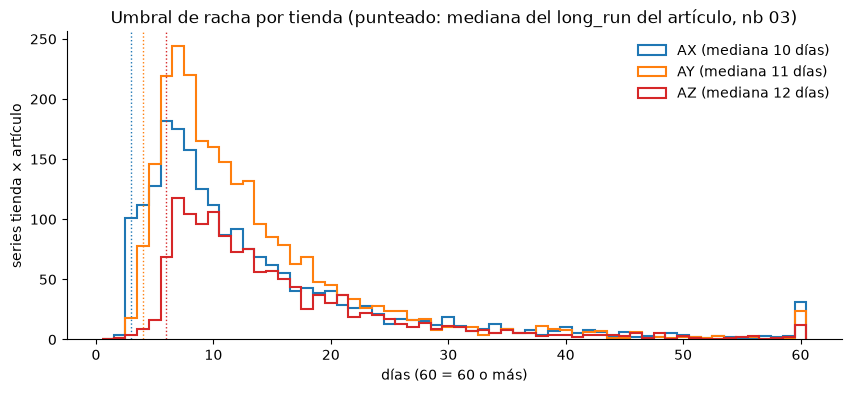

In [19]:
import matplotlib.pyplot as plt

SEG_COLORS = {"AX": "#1f77b4", "AY": "#ff7f0e", "AZ": "#d62728"}   # los del nb 04
fig, ax = plt.subplots(figsize=(10, 4))
bins = np.arange(0.5, 61.5, 1)
for c in SEG:
    v = th.loc[th["cell"] == c, "threshold"].clip(upper=60)
    ax.hist(v, bins=bins, histtype="step", linewidth=1.5, color=SEG_COLORS[c], label=f"{c} (mediana {v.median():.0f} días)")
    ax.axvline(targets.loc[targets["cell"] == c, "long_run"].median(), color=SEG_COLORS[c], linestyle=":", linewidth=1)
ax.set(title="Umbral de racha por tienda (punteado: mediana del long_run del artículo, nb 03)",
       xlabel="días (60 = 60 o más)", ylabel="series tienda × artículo")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

## Etapa 4 · Quiebre de stock frente a intermitencia de la demanda

**Objetivo:** marcar los días-tienda en quiebre sin usar el futuro en ventana y test.
**Entradas:** `units_s`, `thresholds`, `window_start`.
**Salidas:** `breaks` (tienda × artículo × día; 0 = sin quiebre, 1 = racha en la historia, 2 = racha causal, 3 = exceso de ceros).
**Decisión:**
- **E1 · racha:** una racha de ceros ≥ umbral de la tienda es quiebre; una más corta es intermitencia.
  - **En la historia** (antes de la ventana del artículo), si la tienda volvió a vender antes de la ventana, se marca la racha entera: saber que terminó solo usa datos anteriores a la ventana.
  - **En ventana y test** (o si la racha no terminó antes de la ventana), un día se marca solo cuando, **al cierre de su bloque**, la racha ya alcanzó el umbral: con h = 1, el bloque t se conoce completo antes de pronosticar t + 1, pero no se sabe si la tienda vuelve.
- **E2 · exceso de ceros:** un bloque de la tienda con más ceros de lo esperable para su p₀ de train (binomial, P ≤ α = 0,01) marca sus ceros. Capta quiebres partidos por ventas sueltas, que no forman una racha larga. Solo usa los días del propio bloque.
- Una racha cortada por días sin precio termina ahí (la tienda sacó el artículo); no se une con la siguiente.
**Revisar:** días-tienda marcados por tipo, tramo y segmento; cuántos caen en días que el artículo tiene observados (los quiebres escondidos que la máscara del artículo no ve).


In [20]:
from src.store_treatment import BREAK_KINDS, flag_store_breaks

In [21]:
breaks = flag_store_breaks(units_s, thresholds, window_start, ALPHA)

In [22]:
B = breaks.to_numpy()
item_of = units_s.index.get_level_values("item_id")
ws_row = window_start.reindex(item_of).to_numpy()[:, None]
ts_row = test_start.reindex(item_of).to_numpy()[:, None]
section = np.where(days_arr[None, :] < ws_row, "historia", np.where(days_arr[None, :] < ts_row, "ventana", "test"))
item_obs = units_base.reindex(item_of).notna().to_numpy()
flag = B > 0
by_kind = pd.Series(B[flag]).map(BREAK_KINDS).value_counts()
display(by_kind.to_frame("días-tienda"))
display(pd.crosstab(np.repeat(item_of.map(item_cell).to_numpy(), flag.sum(axis=1)), section[flag],
                    rownames=["segmento"], colnames=["tramo"], margins=True, margins_name="total"))
hidden = flag & item_obs
print(f"días-tienda en quiebre: {flag.sum():,} ({flag.sum() / (~np.isnan(units_s.to_numpy())).sum():.1%} de los observados)"
      f" · en días con el artículo observado (quiebres escondidos): {hidden.sum():,}")
assert (units_s.to_numpy()[flag] == 0).all(), "solo se marcan ceros"
assert not (flag & before_first).any(), "nada antes de la primera venta de la tienda"
assert not ((B == 1) & (section != "historia")).any(), "la regla con regreso solo vale en la historia"
ex = breaks.loc["FOODS_3_388"].T.groupby((days_arr - START_D) // 28 + 1).apply(lambda g: (g > 0).sum()).T
display(ex.loc[:, 13:29])

,días-tienda
run_causal,625605
run_history,574447
excess_zeros,166429


tramo,historia,test,ventana,total
segmento,,,,
AX,131983,77410,54609,264002
AY,302541,113946,130316,546803
AZ,297111,118881,139684,555676
total,731635,310237,324609,1366481


días-tienda en quiebre: 1,366,481 (13.7% de los observados) · en días con el artículo observado (quiebres escondidos): 851,907


,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29
store_id,,,,,,,,,,,,,,,,,
CA_1,0,4,28,28,28,28,28,28,28,28,28,28,28,28,27,0,0
CA_2,0,4,28,28,28,28,28,28,28,28,28,28,28,28,25,0,0
CA_3,0,0,26,25,25,22,22,15,24,20,15,21,24,24,15,0,0
CA_4,0,1,28,28,28,28,28,28,28,28,28,28,28,28,24,0,0
TX_1,0,4,28,28,28,28,28,28,28,28,28,28,28,28,24,0,0
TX_2,0,6,28,28,28,28,28,28,28,28,28,28,28,28,25,0,0
TX_3,0,0,20,28,28,28,28,28,28,28,28,28,28,28,26,0,0
WI_1,0,4,28,28,28,28,28,28,28,28,28,28,28,28,25,0,0
WI_2,18,4,28,28,28,28,28,28,28,28,28,28,28,28,28,0,0


## Etapa 5 · Validez e imputación del bloque de tienda

**Objetivo:** completar el bloque de cada tienda con lo que habría vendido en sus días en quiebre, antes de sumar al artículo.
**Entradas:** `units_s`, `breaks`.
**Salidas:** `filled_s` (unidades completadas), `added_s` (unidades agregadas por día) y `store_blocks` (resumen por tienda × bloque).
**Decisión:**
- Cada día en quiebre toma la **venta diaria media de los últimos 28 días válidos** (observados y sin quiebre) **anteriores** de la propia tienda: solo usa el pasado (R5). Los días con venta se conservan tal cual.
- **Número:** 28 días = un bloque de pronóstico y 4 semanas completas (no lo sesga el día de la semana); con menos días la tasa sigue ruido de pocos días, con más tarda en seguir un cambio de nivel reciente.
- **Sin `min_days` por tienda:** completar día a día ya es la validez del bloque de tienda: un bloque casi todo en quiebre queda con su venta observada más la tasa en los días en quiebre. Un mínimo de días por tienda obligaría a descartar la venta observada. La validez del bloque se sigue juzgando a nivel artículo con el `min_days` congelado (4.2, Etapa 6).
- Un día en quiebre sin 28 días válidos previos (inicio de la tienda) no se completa.
**Revisar:** unidades agregadas por tramo y segmento; días sin completar; tiendas que no vuelven a vender mientras siguen con precio (diagnóstico con el futuro, solo para medir el caso de la Etapa 2).


In [23]:
from src.store_treatment import add_store_fill, fill_store_breaks, store_block_summary

In [24]:
RATE_DAYS = 28   # un bloque y 4 semanas completas
filled_s, added_s = fill_store_breaks(units_s, breaks, RATE_DAYS)
store_blocks = store_block_summary(units_s, breaks, added_s)

In [25]:
A = np.nan_to_num(added_s.to_numpy())
U = np.nan_to_num(units_s.to_numpy())
cell_row = item_of.map(item_cell).to_numpy()
rows = []
for c in SEG:
    m = cell_row == c
    row = {"segmento": c}
    for s in ["historia", "ventana", "test"]:
        sm = section[m] == s
        row[f"agregado {s}"] = f"{A[m][sm].sum() / U[m][sm].sum():.2%}"
    rows.append(row)
display(pd.DataFrame(rows).set_index("segmento"))
unfilled = int(store_blocks["unfilled_days"].sum())
print(f"días en quiebre sin completar (sin 28 días válidos previos): {unfilled:,} de {flag.sum():,}")
# Diagnóstico con el futuro: días causales de tiendas que ya no vuelven a vender hasta el final.
X = units_s.to_numpy()
last_sale_pos = (store_bounds["last_sale_d"].fillna(START_D - 1) - START_D).to_numpy()[:, None]
never_back = (B == 2) & (np.arange(X.shape[1])[None, :] > last_sale_pos)
print(f"unidades agregadas a tiendas que no vuelven a vender (con precio): {A[never_back].sum() / A.sum():.1%} de lo agregado")
assert np.allclose(filled_s.to_numpy()[~flag], X[~flag], equal_nan=True), "fuera de los quiebres no cambia nada"
assert (A >= 0).all()
ex_before = units_s.loc["FOODS_3_388"].T.groupby((days_arr - START_D) // 28 + 1).sum().T.loc[:, 13:29]
ex_after = filled_s.loc["FOODS_3_388"].T.groupby((days_arr - START_D) // 28 + 1).sum().T.loc[:, 13:29]
display(ex_before.round(0)); display(ex_after.round(0))

,agregado historia,agregado ventana,agregado test
segmento,,,
AX,3.53%,4.92%,6.55%
AY,9.14%,14.38%,11.82%
AZ,17.64%,32.99%,28.53%


días en quiebre sin completar (sin 28 días válidos previos): 56,981 de 1,366,481
unidades agregadas a tiendas que no vuelven a vender (con precio): 1.5% de lo agregado


,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29
store_id,,,,,,,,,,,,,,,,,
CA_1,106.0,62.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,67.0,55.0
CA_2,71.0,49.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.0,44.0,41.0
CA_3,112.0,65.0,3.0,3.0,5.0,8.0,7.0,8.0,7.0,6.0,5.0,8.0,6.0,5.0,13.0,37.0,65.0
CA_4,97.0,88.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0,47.0,34.0
TX_1,30.0,28.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,62.0,34.0
TX_2,36.0,36.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,109.0,49.0
TX_3,32.0,36.0,14.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,62.0,45.0
WI_1,26.0,27.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,60.0,25.0
WI_2,11.0,58.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,106.0,49.0


,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29
store_id,,,,,,,,,,,,,,,,,
CA_1,106.0,72.0,71.0,71.0,71.0,71.0,71.0,71.0,71.0,71.0,71.0,71.0,71.0,71.0,70.0,67.0,55.0
CA_2,71.0,57.0,59.0,59.0,59.0,59.0,59.0,59.0,59.0,59.0,59.0,59.0,59.0,59.0,62.0,44.0,41.0
CA_3,112.0,65.0,63.0,56.0,50.0,42.0,38.0,22.0,32.0,25.0,18.0,23.0,24.0,25.0,27.0,37.0,65.0
CA_4,97.0,91.0,90.0,90.0,90.0,90.0,90.0,90.0,90.0,90.0,90.0,90.0,90.0,90.0,83.0,47.0,34.0
TX_1,30.0,33.0,32.0,32.0,32.0,32.0,32.0,32.0,32.0,32.0,32.0,32.0,32.0,32.0,29.0,62.0,34.0
TX_2,36.0,44.0,36.0,36.0,36.0,36.0,36.0,36.0,36.0,36.0,36.0,36.0,36.0,36.0,37.0,109.0,49.0
TX_3,32.0,36.0,41.0,38.0,38.0,38.0,38.0,38.0,38.0,38.0,38.0,38.0,38.0,38.0,37.0,62.0,45.0
WI_1,26.0,31.0,31.0,31.0,31.0,31.0,31.0,31.0,31.0,31.0,31.0,31.0,31.0,31.0,30.0,60.0,25.0
WI_2,42.0,67.0,62.0,62.0,62.0,62.0,62.0,62.0,62.0,62.0,62.0,62.0,62.0,62.0,62.0,106.0,49.0


### 5.1 · Ejemplos: el artículo antes y después del tratamiento por tienda

**Qué muestra:** unidades por bloque del artículo con tres series: la suma observada (sin completar nada), la línea base del nb 04 (reglas a nivel artículo) y la suma con los quiebres por tienda completados (Etapa 5, sin las reglas de bloque). Las barras muestran cuántas de las 10 tiendas tienen la mitad o más del bloque en quiebre. FOODS_3_388 y FOODS_2_198 son los dos casos que motivaron este notebook.


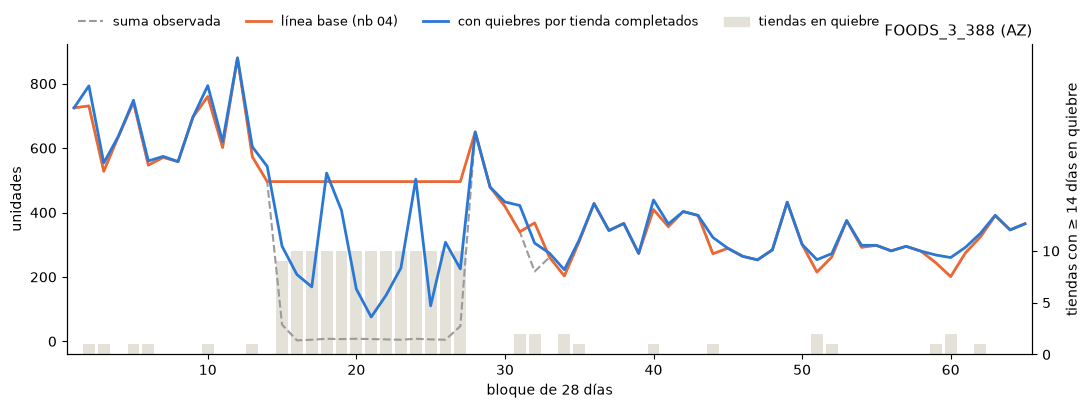

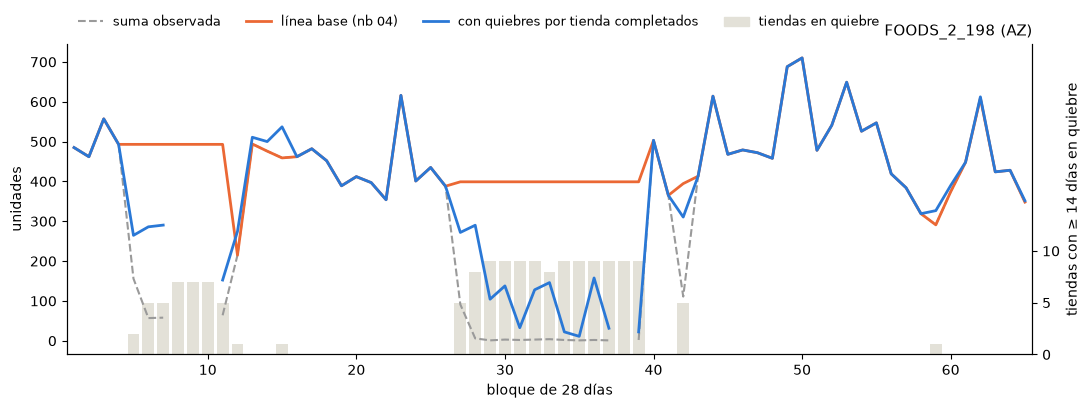

In [26]:
from matplotlib.lines import Line2D

OBS_COLOR, BASE_COLOR, STORE_COLOR, BAR_COLOR = "#9a9a9a", "#eb6834", "#2a78d6", "#e3e1d8"
blk_of_day = (days_arr - START_D) // 28 + 1

def plot_store_example(item, lo=None, hi=None):
    obs = units_base.loc[item].groupby(blk_of_day).sum(min_count=1)
    filled_item = add_store_fill(units_base.loc[[item]], added_s.loc[[item]]).iloc[0].groupby(blk_of_day).sum(min_count=1)
    b = base["blocks_model"].query("item_id == @item").set_index("block")["units"]
    broken = (breaks.loc[item].T.groupby(blk_of_day).apply(lambda g: (g > 0).sum()) >= 14).sum(axis=1)
    lo, hi = lo or obs.index.min(), hi or obs.index.max()
    fig, ax = plt.subplots(figsize=(11, 4.2))
    ax2 = ax.twinx()
    ax2.bar(broken.index, broken.values, color=BAR_COLOR, width=0.8, zorder=0)
    ax2.set(ylim=(0, 30), ylabel="tiendas con ≥ 14 días en quiebre"); ax2.set_yticks([0, 5, 10])
    ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
    ax.plot(obs.index, obs.values, color=OBS_COLOR, linewidth=1.5, linestyle="--")
    ax.plot(b.index, b.values, color=BASE_COLOR, linewidth=2)
    ax.plot(filled_item.index, filled_item.values, color=STORE_COLOR, linewidth=2)
    ax.set(xlim=(lo - 0.5, hi + 0.5), xlabel="bloque de 28 días", ylabel="unidades")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.spines[["top"]].set_visible(False); ax2.spines[["top"]].set_visible(False)
    handles = [Line2D([], [], color=OBS_COLOR, linestyle="--", label="suma observada"),
               Line2D([], [], color=BASE_COLOR, linewidth=2, label="línea base (nb 04)"),
               Line2D([], [], color=STORE_COLOR, linewidth=2, label="con quiebres por tienda completados"),
               plt.Rectangle((0, 0), 1, 1, color=BAR_COLOR, label="tiendas en quiebre")]
    ax.legend(handles=handles, loc="upper left", ncol=4, frameon=False, fontsize=9, bbox_to_anchor=(0, 1.13))
    ax.set_title(f"{item} ({item_cell[item]})", loc="right", fontsize=11)
    plt.tight_layout(); plt.show()

plot_store_example("FOODS_3_388")
plot_store_example("FOODS_2_198")

### 5.2 · Prueba de participación por tienda (basada en Friedman) · probada y descartada

**Resultado (decisión del usuario):** se deja documentada, pero **no alimenta a la Etapa 6**. Con el punto 1 (Etapa 6) los atípicos ya bajan a 31 (AX 0, AY 3, AZ 28). Sumando esta prueba siguen en 31 (AY 5, AZ 26) y los cambios genuinos borrados pasan de 19 a 17, a cambio de completar unas 6.800 tiendas-bloque (+2,7 % de unidades) y con esperados absurdos cuando las tiendas marcadas reúnen casi toda la participación (el total que implican las demás se infla; por ejemplo, 61.505 unidades para una tienda que vendió 234). Lo que queda son sobre todo cambios estacionales, que debe aprender el modelo.

**Objetivo:** detectar, en cada bloque, las tiendas que venden menos de lo esperado frente a las demás tiendas del mismo artículo (quiebres parciales con ventas sueltas que no forman racha ni exceso de ceros) y completarlas.
**Entradas:** `filled_s` (Etapa 5) sumado por tienda × bloque y los días con dato de cada tienda.
**Salidas:** `share_table` (tiendas-bloque que completaría) y `added_total` = `added_s` + lo que agregaría, repartido por igual entre los días del bloque. Solo para documentar: no se usa después.
**Decisión (usuario):**
- **Idea de Friedman:** las tiendas son los jueces y la venta del bloque su calificación. Friedman tal cual dice qué *bloques* difieren y trabaja con rangos (sin magnitud), así que se usa una prueba que da el veredicto por *tienda* y en unidades: la **participación**. El esperado de cada tienda es su participación en las ventas del artículo en los 6 bloques anteriores (`low_block_window`; mínimo 3, `atypical_min_ref`) × el total del bloque. Solo usa el pasado y el propio bloque, como la E2.
- **Prueba:** chi-cuadrado de bondad de ajuste por artículo y bloque (¿cambió el reparto entre tiendas?), y residuo estandarizado ajustado por tienda: por debajo si < −2,58 (α = 0,01, el mismo de las rachas).
- **Imputación:** una tienda por debajo **y** que vende menos de la mitad de su esperado (0,5, el mismo umbral del ratio extremo) toma su esperado, calculado con el total que implican las demás tiendas (si no, su propia caída rebajaría el total). El umbral de 0,5 evita completar variaciones normales: con miles de unidades el chi-cuadrado detecta diferencias pequeñas.
- Si todas las tiendas bajan juntas, el reparto no cambia y no se toca nada: protege los cambios de demanda de toda la cadena y la estacionalidad.
- Solo entran tiendas con el bloque completo (28 días con dato, con precio) y participación previa > 0. La participación se mide con lo observado, no con lo ya completado: si no, cada corrección agranda la participación de la tienda y se retroalimenta.


In [27]:
from src.store_treatment import share_deficit_test, spread_block_extra

In [28]:
SHARE_WINDOW, SHARE_MIN_REF, SHARE_MAX_LEVEL = FE["low_block_window"], FE["atypical_min_ref"], 0.5   # 6, 3 y 0,5
units_sb = filled_s.T.groupby(blk_of_day).sum(min_count=1).T
days_sb = units_s.notna().T.groupby(blk_of_day).sum().T
fixed_sb, share_table = share_deficit_test(units_sb, days_sb, SHARE_WINDOW, SHARE_MIN_REF, ALPHA, SHARE_MAX_LEVEL)
extra_s = spread_block_extra(units_s, (fixed_sb - units_sb).fillna(0.0))
added_total = added_s.fillna(0.0) + extra_s

In [29]:
assert ((fixed_sb - units_sb).fillna(0) >= -1e-9).all().all(), "la prueba solo sube unidades"
assert np.isclose(extra_s.to_numpy().sum(), (fixed_sb - units_sb).fillna(0).to_numpy().sum())
st_tab = share_table.assign(cell=share_table["item_id"].map(item_cell),
                            tramo=np.select([share_table["block"].to_numpy() >= ((test_start.reindex(share_table["item_id"]).to_numpy() - START_D) // 28 + 1),
                                             share_table["block"].to_numpy() >= ((window_start.reindex(share_table["item_id"]).to_numpy() - START_D) // 28 + 1)],
                                            ["test", "ventana"], "historia"))
print(f"tiendas-bloque completadas: {len(share_table):,} en {share_table['item_id'].nunique()} artículos "
      f"· unidades agregadas: {extra_s.to_numpy().sum():,.0f} ({extra_s.to_numpy().sum() / np.nansum(units_s.to_numpy()):.2%} de lo observado)")
display(pd.crosstab(st_tab["cell"], st_tab["tramo"], margins=True, margins_name="total").reindex(columns=["historia", "ventana", "test", "total"]))
display(st_tab.assign(nivel=st_tab["observed"] / st_tab["expected"])[["observed", "expected", "nivel", "residual"]].describe().round(2))
display(st_tab.sort_values("expected", ascending=False).head(8))

tiendas-bloque completadas: 6,830 en 551 artículos · unidades agregadas: 933,338 (2.66% de lo observado)


tramo,historia,ventana,test,total
cell,,,,
AX,615,183,182,980
AY,1892,606,544,3042
AZ,1711,593,504,2808
total,4218,1382,1230,6830


,observed,expected,nivel,residual
count,6830.00,6830.00,6830.00,6830.00
mean,48.39,185.04,0.35,-6.47
std,64.58,1205.34,0.10,4.70
min,0.00,6.80,0.00,-176.32
25%,14.00,39.36,0.30,-7.99
50%,27.50,78.23,0.37,-5.23
75%,58.00,172.10,0.42,-3.72
max,1503.57,61505.45,0.49,-2.58


,item_id,store_id,block,observed,expected,residual,p_value,cell,tramo
4581,FOODS_3_755,CA_4,6,234.178571,61505.453202,-176.316961,0.0,AZ,historia
25,FOODS_1_012,TX_2,14,273.000000,45091.348571,-18.155547,0.0,AY,historia
26,FOODS_1_012,TX_3,14,178.000000,36372.640000,-17.566738,0.0,AY,historia
620,FOODS_1_170,TX_3,14,153.857143,26899.462733,-22.076008,0.0,AY,historia
4488,FOODS_3_741,CA_4,4,139.000000,22211.893617,-143.326749,0.0,AZ,historia
24,FOODS_1_012,TX_1,14,123.285714,20289.720000,-10.148855,0.0,AY,historia
619,FOODS_1_170,TX_2,14,118.000000,18709.826087,-15.499307,0.0,AY,historia
5092,HOBBIES_1_158,WI_2,49,109.857143,15071.081967,-16.425010,0.0,AZ,historia


### 5.3 · Rachas largas: recorte por caída generalizada y exclusión de rachas aisladas

**Objetivo:** dejar de completar rachas de quiebre de meses con la tasa congelada (en FOODS_3_655, CA_1 queda ~300 días en cero con precio y cada día toma 6,96 unidades). Las rachas de más de 6 bloques son el 5,6 % de las rachas, pero aportan el 48 % de las unidades completadas (60 % en AZ).
**Entradas:** `units_s`, `breaks` (Etapa 4), `window_start` (1.4), `bounds` (1.2), `units_base` y `units_lc` (1.2), `added_s` (Etapa 5).
**Salidas:** `long_runs` (rachas largas y su tipo), `item_cuts` (artículos con caída generalizada), `bounds_x` (ciclo de vida recortado, **entra a la Etapa 6**) y, solo para comparar, `added_x` y las cuatro variantes.
**Decisión (usuario, 2026-11-06):**
- **Racha larga:** más de 6 bloques (168 días) de quiebre seguido en una tienda.
- **Caída generalizada:** ≥ 9 de 10 tiendas en racha larga a la vez durante 6 bloques o más (k = 9, el mismo criterio de "quiebre casi total" del diagnóstico de causas; con k = 7 saldrían 22 artículos más, con caídas en que 3 tiendas siguen vendiendo). La historia del artículo empieza en el **primer bloque completo tras la vuelta a stock**; si después quedan menos de 39 bloques, el artículo sale (la 4.3 ya lo hace). Es un **filtro de alcance** (historia suficiente para pronosticar, igual que el mínimo de 39 bloques), no una regla de pronóstico: por eso mira la serie completa.
- **Racha aislada** (no cae en su mayoría dentro de una caída generalizada): **se sigue completando como hasta ahora** (decisión final del usuario, 2026-11-06). Se probó excluir la tienda en ese periodo (NaN, sin completar; si la racha termina antes de la ventana, entera; si no, desde el bloque en cuyo cierre ya superó 6 bloques): en los mismos artículos subía los atípicos de 28 a 49 (71 % de los nuevos junto a la salida o vuelta de la tienda) y los extremos que llegan al modelo de 27 a 46. La prueba queda documentada abajo y no entra a la Etapa 6.
- **NaN de tienda (solo en la prueba de exclusión):** en la suma del artículo la tienda aporta lo que vendió (0); las medidas del artículo (mediana de 6 bloques, `min_days`, bloque deprimido) ven el total, que baja mientras dura la exclusión.
- **Lo que entra a la Etapa 6:** `added_s` (sin cambios) y `bounds_x`: salen los 2 artículos sin vuelta a stock y, en los que tienen una caída generalizada, los días anteriores a la vuelta quedan fuera del ciclo de vida. La 4.3 saca a los que quedan con menos de 39 bloques.
**Revisar:** artículos que salen por segmento; atípicos, unidades completadas, cambios genuinos y extremos que llegan al modelo en los **mismos artículos**, separando el efecto del recorte y el de las exclusiones.


In [30]:
from src.features import add_ratio, treat_ratio
from src.store_treatment import classify_level_changes, cut_item_bounds, exclude_long_runs, long_break_runs

In [31]:
LONG_RUN_DAYS = 6 * 28   # racha larga: más de 6 bloques (usuario)
CHAIN_STORES = 9          # caída generalizada: ≥ 9 de 10 tiendas a la vez (usuario, k = 9)
long_runs, item_cuts = long_break_runs(breaks, window_start, LONG_RUN_DAYS, CHAIN_STORES)
units_x, breaks_x = exclude_long_runs(units_s, breaks, long_runs)
_, added_x = fill_store_breaks(units_x, breaks_x, RATE_DAYS)   # solo para la comparación (exclusión descartada)
bounds_x = cut_item_bounds(bounds, item_cuts)                     # entra a la Etapa 6

In [32]:
lr = long_runs.assign(cell=long_runs["item_id"].map(item_cell))
assert (lr["days"] > LONG_RUN_DAYS).all() and lr["kind"].isin(["generalizada", "aislada"]).all()
assert lr.loc[lr["kind"] == "generalizada", "excl_start_d"].isna().all()
iso = lr[lr["kind"] == "aislada"]
assert ((iso["excl_start_d"] >= iso["start_d"]) & (iso["excl_start_d"] <= iso["end_d"])).all()
excl = units_x.isna() & units_s.notna()
assert (units_s.to_numpy()[excl.to_numpy()] == 0).all(), "solo se excluyen días en cero"
assert not (breaks_x.to_numpy()[excl.to_numpy()] > 0).any()
print("Rachas largas por tipo:")
display(pd.crosstab(lr["cell"], lr["kind"], margins=True, margins_name="total"))
print(f"días-tienda excluidos: {int(excl.to_numpy().sum()):,} · tienda-bloques (equivalentes): {excl.to_numpy().sum() / 28:,.0f}")
ic = item_cuts.assign(cell=item_cuts["item_id"].map(item_cell),
                      bloque_vuelta=lambda d: (d["cut_d"] - START_D) // 28 + 1)
print(f"Artículos con caída generalizada (de los {len(bounds)}):")
display(ic["cell"].value_counts().reindex(SEG).rename("artículos").to_frame().assign(sin_vuelta=ic.groupby("cell")["no_return"].sum()))
display(ic.sort_values(["cell", "cut_d"]).head(10))
assert (bounds_x["first_sale_d"] >= bounds.loc[bounds_x.index, "first_sale_d"]).all()

Rachas largas por tipo:


kind,aislada,generalizada,total
cell,,,
AX,122,122,244
AY,257,209,466
AZ,345,402,747
total,724,733,1457


días-tienda excluidos: 180,857 · tienda-bloques (equivalentes): 6,459
Artículos con caída generalizada (de los 592):


,artículos,sin_vuelta
cell,,
AX,13,0
AY,23,0
AZ,37,2


,item_id,episode_start_d,episode_end_d,cut_d,no_return,cell,bloque_vuelta
42,HOBBIES_1_100,546,725,738.0,False,AX,23.0
30,FOODS_3_516,1032,1291,1298.0,False,AX,43.0
4,FOODS_2_104,1130,1462,1466.0,False,AX,49.0
2,FOODS_1_150,1522,1692,1718.0,False,AX,58.0
16,FOODS_3_151,1449,1795,1802.0,False,AX,61.0
19,FOODS_3_263,1449,1795,1802.0,False,AX,61.0
31,FOODS_3_572,1449,1795,1802.0,False,AX,61.0
17,FOODS_3_238,1494,1846,1858.0,False,AX,63.0
45,HOBBIES_1_166,1606,1832,1858.0,False,AX,63.0
50,HOBBIES_1_308,1606,1832,1858.0,False,AX,63.0


In [33]:
# Flujo del artículo en cuatro variantes, para separar el efecto del recorte y el de las exclusiones.
item_masked_x = units_lc.notna() & units_base.isna()   # mismo criterio que la Etapa 6
kept = bounds_x.index
pipe = lambda units, bnds: item_block_pipeline(units.loc[bnds.index], chain_total, bnds, day_dates,
                                               targets[targets["item_id"].isin(bnds.index)], FE, MIN_BLOCKS, TEST_BLOCKS, VAL_BLOCKS)
variants_53 = {
    "actual (con tienda)": pipe(add_store_fill(units_base, added_s, item_masked_x), bounds),
    "solo recorte": pipe(add_store_fill(units_base, added_s, item_masked_x), bounds_x),
    "solo exclusión de aisladas": pipe(add_store_fill(units_base, added_x, item_masked_x), bounds),
    "recorte + exclusión": pipe(add_store_fill(units_base, added_x, item_masked_x), bounds_x),
}

In [34]:
modeled_53 = {k: set(v["blocks_model"]["item_id"]) for k, v in variants_53.items()}
common_53 = modeled_53["recorte + exclusión"]
gone_53 = sorted(modeled_53["actual (con tienda)"] - common_53)
print(f"artículos modelados: actual {len(modeled_53['actual (con tienda)'])} → con recorte {len(common_53)}")
display(pd.Series([item_cell[i] for i in gone_53]).value_counts().reindex(SEG).rename("salen").to_frame())
assert modeled_53["solo recorte"] == common_53

stc_53 = ext_base[ext_base["kind"] == "estructural"].copy()
stc_53["clase"] = classify_level_changes(base["blocks_model"], ext_base, FE["case_low_level"], FE["low_block_window"], 3)
stc_53 = stc_53[stc_53["item_id"].isin(common_53) & (stc_53["clase"] == "genuino")]
rows_53 = units_s.index[units_s.index.get_level_values("item_id").isin(common_53)]
sold_53 = np.nansum(units_s.loc[rows_53].to_numpy())

def summary_53(v, added):
    e = extreme_blocks(v["blocks_model"], v["cases"], item_cell)
    e = e[e["item_id"].isin(common_53)]
    at = e[e["kind"] == "atipico"]["cell"].value_counts().reindex(SEG).fillna(0).astype(int)
    still = set(map(tuple, e[["item_id", "block"]].to_numpy()))
    f = treat_ratio(add_ratio(v["blocks_model"]), FE["max_ratio"], FE["min_ratio_start"], FE["case_start_blocks"])
    f = f[f["item_id"].isin(common_53)]
    return {**{f"atípicos {c}": at[c] for c in SEG}, "atípicos": at.sum(),
            "extremos al modelo": int((f["ratio"].notna() & ((f["ratio_raw"] < 0.5) | (f["ratio_raw"] > 2))).sum()),
            "genuinos suavizados": int((~stc_53[["item_id", "block"]].apply(tuple, axis=1).isin(still)).sum()),
            "completado ÷ vendido": f"{np.nansum(added.loc[rows_53].to_numpy()) / sold_53:.2%}"}

added_of = {"actual (con tienda)": added_s, "solo recorte": added_s, "solo exclusión de aisladas": added_x, "recorte + exclusión": added_x}
print(f"En los mismos {len(common_53)} artículos:")
display(pd.DataFrame({k: summary_53(v, added_of[k]) for k, v in variants_53.items()}).T)

# Atípicos que aparecen con la exclusión: ¿caen junto a la salida o la vuelta de una tienda excluida (±2 bloques)?
at_cut = extreme_blocks(variants_53["solo recorte"]["blocks_model"], variants_53["solo recorte"]["cases"], item_cell)
at_all = extreme_blocks(variants_53["recorte + exclusión"]["blocks_model"], variants_53["recorte + exclusión"]["cases"], item_cell)
new_53 = at_all[at_all["kind"] == "atipico"].merge(at_cut.loc[at_cut["kind"] == "atipico", ["item_id", "block"]], how="left", indicator=True)
new_53 = new_53[new_53["_merge"] == "left_only"].drop(columns="_merge")
near = [((iso["item_id"] == r.item_id) & (((iso["excl_start_d"] - (START_D + (r.block - 1) * 28)).abs() <= 56)
         | ((iso["end_d"] - (START_D + (r.block - 1) * 28)).abs() <= 56))).any() for r in new_53.itertuples()]
print(f"atípicos nuevos con la exclusión: {len(new_53)} · junto a una salida o vuelta de tienda: {np.mean(near):.0%}")
display(pd.crosstab(new_53["cell"], new_53["section"], margins=True, margins_name="total"))

artículos modelados: actual 579 → con recorte 517


,salen
AX,12
AY,19
AZ,31


En los mismos 517 artículos:


,atípicos AX,atípicos AY,atípicos AZ,atípicos,extremos al modelo,genuinos suavizados,completado ÷ vendido
actual (con tienda),0,3,25,28,28,14,9.46%
solo recorte,0,3,25,28,27,14,9.46%
solo exclusión de aisladas,5,4,40,49,46,13,8.17%
recorte + exclusión,5,4,40,49,45,13,8.17%


atípicos nuevos con la exclusión: 21 · junto a una salida o vuelta de tienda: 71%


section,historia,test,total
cell,,,
AX,0,5,5
AY,0,1,1
AZ,11,4,15
total,11,10,21


## Etapa 6 · Suma por artículo

**Objetivo:** llevar al artículo las unidades completadas por tienda. Desde aquí todo es igual que en el nb 04, a nivel artículo.
**Entradas:** `units_base` (artículo × día, Etapa 1.2: la `units_treated` del nb 04), `added_s` (Etapa 5) y `bounds_x` (5.3). La prueba de la 5.2 y la exclusión de rachas aisladas de la 5.3 no entran: se descartaron.
**Salidas:** `units_full` = la misma serie del nb 04 más lo completado por tienda (los 592 artículos) y `units_treated` = `units_full` recortada con `bounds_x`. Se usa el mismo nombre para que las celdas del nb 04 que siguen corran sin cambios.
**Decisión:**
- **Días observados del artículo:** lo completado por tienda se suma a su venta. Son los quiebres parciales, que la suma escondía.
- **Días de quiebre total** (todas las tiendas en cero, que la máscara del artículo dejó en NaN con su `long_run` congelado): toman la suma de lo completado por tienda. Sin esto, el bloque queda con menos días, vende menos y el ratio se dispara: era la causa de 40 de los 69 atípicos que quedaban en AZ (34 en ventana y test). La tasa de cada tienda solo usa días anteriores, así que vale en ventana y test. Si ninguna tienda tiene tasa (o la racha no alcanza el umbral de la tienda), el día sigue en NaN, como en el nb 04.
- **Los demás NaN no cambian:** fuera del ciclo de vida del artículo o sin dato de origen.
- **Recorte de la 5.3:** salen los artículos sin vuelta a stock y, en los que tuvieron una caída generalizada, los días anteriores a la vuelta quedan en NaN (fuera del ciclo de vida, igual que antes de la primera venta). Así la suma por bloque de la 4.1 sigue cuadrando con el total diario.
**Revisar:** solo se llenan días de quiebre total del artículo; unidades agregadas y días completados por segmento; artículos y días que quita el recorte.


In [35]:
item_masked = units_lc.notna() & units_base.isna()   # quiebres totales que enmascaró el nb 04 (Etapa 1.2)
units_full = add_store_fill(units_base, added_s, item_masked)
# 5.3: sin los artículos sin vuelta a stock y con la historia desde la vuelta (los días anteriores, NaN).
day_num = units_full.columns.str.removeprefix("d_").astype(int).to_numpy()
units_treated = units_full.loc[bounds_x.index].where(day_num[None, :] >= bounds_x["first_sale_d"].to_numpy()[:, None])

In [36]:
assert units_full.shape == units_base.shape and units_full.index.equals(units_base.index)
new_days = units_full.notna() & units_base.isna()
assert not (units_full.isna() & units_base.notna()).any().any(), "ningún día observado queda vacío"
assert not (new_days & ~item_masked).any().any(), "solo se llenan días de quiebre total del artículo"
filled_total = pd.DataFrame({"días de quiebre total": item_masked.sum(axis=1).groupby(item_cell).sum(),
                             "completados por tienda": new_days.sum(axis=1).groupby(item_cell).sum()}).reindex(SEG)
filled_total["%"] = (filled_total["completados por tienda"] / filled_total["días de quiebre total"]).map("{:.1%}".format)
display(filled_total)
assert (units_full.fillna(0) >= units_base.fillna(0) - 1e-9).all().all()
tot_base = units_base.sum(axis=1).groupby(item_cell).sum()
tot_new = units_full.sum(axis=1).groupby(item_cell).sum()
display(pd.DataFrame({"unidades nb 04": tot_base, "unidades con tienda": tot_new,
                      "agregadas": (tot_new / tot_base - 1).map("{:.2%}".format)}).reindex(SEG))
print(f"unidades agregadas en total: {np.nansum(units_full.to_numpy()) / np.nansum(units_base.to_numpy()) - 1:.2%}")
# Recorte de la 5.3.
full_x = units_full.loc[bounds_x.index]
cut_days = full_x.notna() & units_treated.isna()
assert units_treated.index.equals(bounds_x.index) and not (units_treated.notna() & full_x.isna()).any().any()
assert np.allclose(units_treated.fillna(-1).to_numpy()[~cut_days.to_numpy()], full_x.fillna(-1).to_numpy()[~cut_days.to_numpy()])
cut_items = cut_days.any(axis=1)
print(f"5.3: siguen {len(units_treated)} de {len(units_full)} artículos (salen {len(units_full) - len(units_treated)} sin vuelta a stock) · "
      f"con historia recortada: {int(cut_items.sum())} · días con dato que quedan fuera: {int(cut_days.to_numpy().sum()):,} "
      f"({np.nansum(full_x.to_numpy()[cut_days.to_numpy()]) / np.nansum(units_full.to_numpy()):.1%} de las unidades)")


,días de quiebre total,completados por tienda,%
cell,,,
AX,8226,8088,98.3%
AY,23356,21663,92.8%
AZ,26025,24871,95.6%


,unidades nb 04,unidades con tienda,agregadas
cell,,,
AX,12106080.0,1.264198e+07,4.43%
AY,14542106.0,1.608893e+07,10.64%
AZ,8494916.0,1.037172e+07,22.09%


unidades agregadas en total: 11.27%
5.3: siguen 590 de 592 artículos (salen 2 sin vuelta a stock) · con historia recortada: 71 · días con dato que quedan fuera: 83,346 (6.4% de las unidades)


# Flujo del nb 04 sobre la serie sumada

Desde aquí las celdas son **las del nb 04, una por una**, sin cambios de método, a nivel artículo, con `units_treated` de la Etapa 6 como entrada: Etapas 4 (bloques, 4.2, 4.2a, 4.2b, 4.3 y 4.4), 5, 6, 7, 9, 10 y 11 del nb 04. La Etapa 8 del nb 04 está pendiente y no se replica.
- **Numeración:** cada etapa lleva su número en este notebook y, entre paréntesis, el del nb 04. Dentro del texto, las referencias a etapas (6a, 4.3, Etapa 11, …) son las del nb 04.
- **Números citados en los textos** (conteos de bloques, porcentajes, ejemplos): son los del nb 04 sin tratamiento por tienda. Las celdas de chequeo los recalculan para esta serie.
- Después de la 4.4 se agrega la sección **7.5**, que compara con la línea base (teníamos / quedan).
- **Sin persistencia (D1):** la Etapa 11 arma los datasets pero no los exporta.


## Etapa 7 (nb 04, Etapa 4) · Agregación en bloques de 28 días, variable objetivo y partición por artículo

**Objetivo:** pasar la serie diaria a bloques de 28 días, completar los bloques no válidos y asignar a cada artículo sus bloques de train y test. El objetivo (ratio entre bloques) se construye en la 6a.
**Entradas:** `units_treated` (Etapa 6) y `bounds_x` (5.3), `agg["chain_total"]` (unidades de toda la cadena por día, los 3,049 artículos, sin enmascarar) y `calendar` (para las fechas).
**Salidas:** `blocks` (4.1, todos los bloques de los 590 artículos que deja la 5.3), `blocks_valid` (4.2, bloques no válidos completados con el valor del bloque anterior, marca `imputed`) y `blocks_model` (4.3, los artículos que se modelan, con `pos`, `split` y `backtest`), más `excluded`.
**Decisión (D1, D5 y constituciones 4.0.0 y 6.0.0):**
- **Valor del bloque = suma de sus unidades.** Los días en NaN (quiebres enmascarados) no restan ni anulan el bloque, y no se exige un mínimo de días observados: `min_days` solo sirvió para el CV de la clasificación.
- **Bloque sin ningún día con dato** (los 28 días dentro de un quiebre): queda en NaN, no en 0. No es una venta de 0 unidades, sino un bloque no observado. Se trata en la 4.2 junto con los demás bloques no válidos (decisión del usuario).
- **La serie va del bloque de la primera venta al de la última venta**, aunque alguno de esos dos bloques tenga un solo día con venta. Fuera de ese intervalo el artículo no existe y no hay fila.
- Los bloques están alineados con el calendario: el bloque 1 empieza en d_122; d_122–d_1577 son los bloques 1–52 (Y1–Y4) y d_1578–d_1941 son los bloques 53–65 (Y5).
- **Partición por artículo (4.3):** test = últimos 13 bloques del ciclo de vida; todo lo anterior es train. Todos los artículos tienen así un test de igual longitud, aunque su ciclo termine antes del bloque 65.
- **Ventana de backtesting:** los últimos 13 bloques de train (`backtest = True`). Son train: en el fold k se entrena con todo lo anterior a la ventana más sus bloques 1 a k − 1 y se predice el bloque k; luego ese bloque pasa a ser dato de entrenamiento. Con sus errores se eligen hiperparámetros y modelo; el ganador se reentrena con todo el train. El test no se toca hasta el nb 05.
- **Mínimo 39 bloques** (3 años: ≥ 13 de train antes de la ventana para el primer fold, 13 de ventana y 13 de test); los demás se excluyen.

### 4.1 · Bloques


In [37]:
from src.features import aggregate_blocks, assign_windows, fill_invalid_blocks

In [38]:
day_dates = pd.Series(pd.to_datetime(calendar["date"]).to_numpy(), index=calendar["d"].str.removeprefix("d_").astype(int))
blocks = aggregate_blocks(units_treated, np.asarray(agg["chain_total"], dtype=float), bounds_x, day_dates)

In [39]:
n_blocks = blocks.groupby("item_id")["block"].agg(["min", "max", "size"])
display(pd.Series({
    "filas": len(blocks), "artículos": blocks["item_id"].nunique(),
    "bloques (máx.)": blocks["block"].max(), "artículos con los 65 bloques": int((n_blocks["size"] == 65).sum()),
    "artículos que terminan antes del bloque 65": int((n_blocks["max"] < 65).sum()),
    "bloques sin ningún día con dato (units = NaN)": int(blocks["units"].isna().sum()),
    "bloques con días observados y 0 unidades": int((blocks["units"] == 0).sum()),
}, name="blocks").to_frame())
display(n_blocks["size"].describe().to_frame("bloques por artículo").T)

assert blocks["item_id"].nunique() == len(bounds_x) and blocks["block"].between(1, 65).all()
assert (blocks["units"].isna() == (blocks["days_with_data"] == 0)).all(), "NaN solo en bloques sin ningún día con dato"
assert blocks["chain_units"].notna().all() and (blocks["units"].dropna() >= 0).all()
last_block = (bounds_x["last_sale_d"] - START_D) // 28 + 1
assert (n_blocks["max"] == last_block.reindex(n_blocks.index)).all(), "la serie termina en el bloque de la última venta"
assert (n_blocks["size"] == n_blocks["max"] - n_blocks["min"] + 1).all(), "sin huecos entre bloques"
# Las sumas por bloque reproducen el total diario de cada artículo y de la cadena.
assert np.allclose(blocks.groupby("item_id")["units"].sum().reindex(units_treated.index), np.nansum(units_treated.to_numpy(), axis=1))
chain = blocks.drop_duplicates("block").set_index("block")["chain_units"]
assert np.isclose(chain.sum(), np.asarray(agg["chain_total"], dtype=float)[START_D - 1 : END_D].sum())
display(blocks.drop_duplicates("block")[["block", "start_d", "end_d", "start_date", "end_date", "chain_units"]]
        .iloc[[0, 1, 51, 52, 64]].set_index("block"))

,blocks
filas,33365
artículos,590
bloques (máx.),65
artículos con los 65 bloques,370
artículos que terminan antes del bloque 65,2
bloques sin ningún día con dato (units = NaN),32
bloques con días observados y 0 unidades,0


,count,mean,std,min,25%,50%,75%,max
bloques por artículo,590.0,56.550847,15.731835,1.0,54.0,65.0,65.0,65.0


,start_d,end_d,start_date,end_date,chain_units
block,,,,,
1,122,149,2011-05-30,2011-06-26,711650.0
2,150,177,2011-06-27,2011-07-24,735634.0
52,1550,1577,2015-04-27,2015-05-24,1029093.0
53,1578,1605,2015-05-25,2015-06-21,1082808.0
65,1914,1941,2016-04-25,2016-05-22,1231764.0


In [40]:
# Primer bloque de cada artículo: cuántos días de ese bloque estaban dentro de su ciclo de vida.
first_rows = blocks.loc[blocks.groupby("item_id")["block"].idxmin()]
first_rows = first_rows.assign(days_in_lifecycle=first_rows["end_d"] - first_rows["item_id"].map(bounds_x["first_sale_d"]) + 1)
started_later = first_rows[first_rows["block"] > 1]
print(f"artículos que empiezan después del bloque 1: {len(started_later)} de {len(bounds_x)}")
display(started_later["days_in_lifecycle"].clip(upper=28).describe().to_frame("días del primer bloque dentro del ciclo de vida").T)
display(started_later.sort_values("days_in_lifecycle").head())

artículos que empiezan después del bloque 1: 220 de 590


,count,mean,std,min,25%,50%,75%,max
días del primer bloque dentro del ciclo de vida,220.0,19.168182,9.515855,1.0,10.0,24.0,28.0,28.0


,item_id,block,start_d,end_d,start_date,end_date,days_with_data,units,chain_units,days_in_lifecycle
6900,FOODS_3_288,22,710,737,2013-01-07,2013-02-03,1,12.0,926691.0,1.0
11571,FOODS_3_313,2,150,177,2011-06-27,2011-07-24,1,35.0,735634.0,1.0
13356,HOUSEHOLD_1_304,16,542,569,2012-07-23,2012-08-19,1,1.0,994957.0,1.0
2145,HOUSEHOLD_1_427,3,178,205,2011-07-25,2011-08-21,1,8.0,752978.0,1.0
3088,HOUSEHOLD_1_366,3,178,205,2011-07-25,2011-08-21,1,13.0,752978.0,1.0


,count,mean,std,min,5%,50%,95%,max
item_id,,,,,,,,
AX,11958.0,1017.3,1571.0,2.0,138.0,490.2,3726.3,17599.0
AY,14605.0,1043.8,1534.4,1.0,179.6,620.8,3092.8,45473.0
AZ,6770.0,1312.2,1476.3,1.0,169.0,798.8,4491.3,12758.4


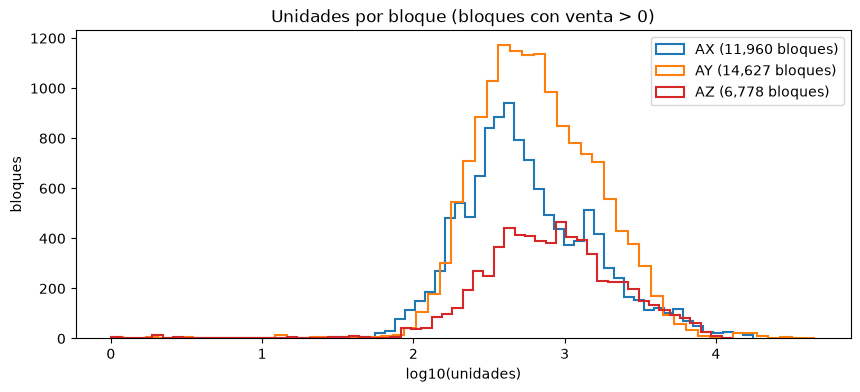

,item_id,block,start_d,end_d,start_date,end_date,days_with_data,units,chain_units
0,FOODS_3_586,1,122,149,2011-05-30,2011-06-26,28,14983.0,711650.0
1,FOODS_3_586,2,150,177,2011-06-27,2011-07-24,28,15156.0,735634.0
2,FOODS_3_586,3,178,205,2011-07-25,2011-08-21,28,17599.0,752978.0
3,FOODS_3_586,4,206,233,2011-08-22,2011-09-18,28,16698.0,749675.0
4,FOODS_3_586,5,234,261,2011-09-19,2011-10-16,28,16198.0,806458.0


In [41]:
import matplotlib.pyplot as plt

seg = blocks["item_id"].map(targets.set_index("item_id")["cell"])
display(blocks.groupby(seg)["units"].describe(percentiles=[0.05, 0.5, 0.95]).round(1))

fig, ax = plt.subplots(figsize=(10, 4))
for cell, color in zip(["AX", "AY", "AZ"], ["#1f77b4", "#ff7f0e", "#d62728"]):
    s = blocks.loc[(seg == cell) & (blocks["units"] > 0), "units"]
    ax.hist(np.log10(s), bins=60, histtype="step", linewidth=1.5, color=color, label=f"{cell} ({(seg == cell).sum():,} bloques)")
ax.set(title="Unidades por bloque (bloques con venta > 0)", xlabel="log10(unidades)", ylabel="bloques")
ax.legend()
plt.show()
display(blocks.head())

### 4.2 · Bloques no válidos: valor del bloque anterior

**Qué hace:** `fill_invalid_blocks` marca como no válido un bloque por dos motivos (`invalid_reason`):
- **`min_days`:** tiene menos días observados que el `min_days` congelado del artículo (nb 03), incluidos los bloques sin ningún día con dato. Casi todo el bloque cae en un quiebre.
- **`low_units`:** pasó `min_days`, pero sus unidades no llegan al 10 % de su referencia (`low_block_share = 0.1`). Es un quiebre que unas ventas sueltas de 1 a 3 unidades escondieron: cortan las rachas de ceros y el bloque queda con días "observados". Ejemplo: HOUSEHOLD_1_327, bloque 40, 10 días observados y 13 unidades frente a unas 2.000 normales. La referencia es la mediana de sus últimos 6 bloques válidos (`low_block_window = 6`, un semestre); en los primeros 6 bloques, la mediana de los bloques válidos de esos 6, que siempre están antes de la ventana de backtesting (sin fuga). El bloque 1 del artículo no se evalúa: un lanzamiento que arranca vendiendo poco no es un quiebre.

El bloque no válido toma el valor del bloque anterior del mismo artículo (forward fill) y queda marcado en `imputed`.

**Decisión (usuario, constitución 6.0.0):**
- Con el valor anterior, el ratio del bloque no válido vale 1 ("no cambió la tendencia") y el bloque siguiente se compara contra el último bloque válido, que es el punto de comparación real.
- La serie queda completa y continua; se miden todos los bloques de la ventana de backtesting y del test.
- `min_days` se usa como criterio de bloque válido porque ya está justificado y congelado en el nb 03 (R5).
- **10 % (decisión del usuario):** la idea es capturar los quiebres sin dañar la baja demanda real. Un bloque que vende menos de la décima parte de su nivel reciente es casi seguro un quiebre. Frente al 20 %, marca 242 bloques menos (la zona dudosa entre 10 % y 20 %, sobre todo en AZ) y deja 33 ratios > 10 en el train en vez de 17. Con 5 % quedarían 71, y con la mediana (100 %) se marcaría más de la mitad de los bloques.
- **6 bloques (decisión del usuario):** las series se parecen más a sus periodos recientes que al mismo periodo del año anterior (estabilidad, nb 02). Con 3, 6 o 13 bloques el resultado es casi igual; 6 no se mueve por un solo bloque raro y coincide con la ventana de 6 de la 6a.
- Si los primeros bloques de un artículo no son válidos (lanzamiento con pocos días), no hay valor que arrastrar: se eliminan y la serie empieza en el primer bloque válido. Por eso este paso va antes de la partición: el mínimo de 39 bloques y los 13 de test se cuentan sobre la serie ya recortada.

**Revisar:** cuántos bloques se completan, cuántos bloques iniciales se eliminan, que no quede ningún NaN, y un ejemplo.


In [42]:
blocks_valid = fill_invalid_blocks(blocks, targets.set_index("item_id")["min_days"],
                                   cfg["features"]["low_block_share"], cfg["features"]["low_block_window"])

In [43]:
b = blocks_valid
assert b["units"].notna().all() and (b["units"] > 0).all(), "sin NaN ni ceros"
assert b["item_id"].nunique() == blocks["item_id"].nunique()
assert (b.groupby("item_id")["block"].diff().dropna() == 1).all(), "bloques contiguos"
first = b.groupby("item_id").cumcount() == 0
assert not b.loc[first, "imputed"].any(), "cada serie empieza en un bloque válido"
prev = b.groupby("item_id")["units"].shift(1)
assert (b.loc[b["imputed"], "units"] == prev[b["imputed"]]).all(), "el bloque no válido toma el valor del anterior"
assert (b.groupby("item_id")["block"].max() == blocks.groupby("item_id")["block"].max()).all(), "el final de la serie no cambia"

dropped = blocks.groupby("item_id").size() - b.groupby("item_id").size()
print(f"bloques no válidos completados: {int(b['imputed'].sum())} en {b.loc[b['imputed'], 'item_id'].nunique()} artículos"
      f" · de ellos sin ningún día con dato: {int((b['imputed'] & (b['days_with_data'] == 0)).sum())}")
display(b.loc[b["imputed"], "invalid_reason"].value_counts().rename("bloques completados").to_frame())
assert set(b["invalid_reason"]) <= {"", "min_days", "low_units"} and (b["imputed"] == (b["invalid_reason"] != "")).all()
print(f"bloques iniciales no válidos eliminados: {int(dropped.sum())} en {int((dropped > 0).sum())} artículos")
display(dropped[dropped > 0].value_counts().sort_index().rename("artículos").rename_axis("bloques eliminados").to_frame().T)
display(b[(b["item_id"] == "FOODS_3_404") & b["block"].between(49, 55)][["item_id", "block", "days_with_data", "units", "imputed", "invalid_reason"]])
display(b[(b["item_id"] == "HOUSEHOLD_1_327") & b["block"].between(38, 43)][["item_id", "block", "days_with_data", "units", "imputed", "invalid_reason"]])

bloques no válidos completados: 23 en 9 artículos · de ellos sin ningún día con dato: 11


,bloques completados
invalid_reason,
min_days,20
low_units,3


bloques iniciales no válidos eliminados: 86 en 46 artículos


bloques eliminados,1,2,3,4,10
artículos,30,5,4,6,1


,item_id,block,days_with_data,units,imputed,invalid_reason
12768,FOODS_3_404,49,28,1550.750000,False,
12769,FOODS_3_404,50,28,2016.857143,False,
12770,FOODS_3_404,51,28,2168.750000,False,
12771,FOODS_3_404,52,28,2129.821429,False,
12772,FOODS_3_404,53,28,3629.964286,False,
12773,FOODS_3_404,54,28,4329.000000,False,
12774,FOODS_3_404,55,28,4243.000000,False,


,item_id,block,days_with_data,units,imputed,invalid_reason
28207,HOUSEHOLD_1_327,38,28,2118.428571,False,
28208,HOUSEHOLD_1_327,39,28,1596.535714,False,
28209,HOUSEHOLD_1_327,40,28,1635.285714,False,
28210,HOUSEHOLD_1_327,41,28,1751.607143,False,
28211,HOUSEHOLD_1_327,42,28,1815.142857,False,
28212,HOUSEHOLD_1_327,43,28,1967.000000,False,


### 4.2a · Primer bloque incompleto: la serie empieza en el bloque siguiente

**Problema (Etapa 11, ratios > 2 por segmento):** 72 de los 130 ratios > 2 de arranque están en el bloque 2 (25 de los 29 de AX). En esos artículos el primer bloque está incompleto: el artículo empezó a venderse a mitad de bloque o tuvo días enmascarados (mediana 14 días con datos de 28) y vende alrededor del 27 % de su nivel, mientras el bloque 2 ya está al 89 %. No es una rampa: es medio mes de venta. Pasa `min_days` (4 a 9 días) y la 4.2 no lo puede completar porque no tiene bloque anterior.
**Entradas:** `blocks_valid` (4.2) y `MIN_BLOCKS = 39` (constitución 4.0.0, Principio VI; lo usa la 4.3).
**Salidas:** `blocks_valid` sin los primeros bloques incompletos.

**Decisión (usuario):**
- Si el primer bloque de un artículo tiene menos de 28 días con datos (bloque completo), se quita y la serie empieza en el siguiente bloque válido. Si los bloques que siguen eran no válidos (4.2), copiaron el valor del bloque incompleto y también se quitan, igual que la 4.2 quita los bloques iniciales no válidos.
- **Por qué 28 y no 14 (R4):** el ratio del bloque 2 sale inflado en todos los tramos con menos de 28 días, aun con 22 a 27 días (mediana 1,21; 12 % > 2), frente a 1,03 y 1 % > 2 con el bloque completo. La celda de chequeo recalcula la tabla.
- **Excepción:** si al quitarlo el artículo quedaría con menos de 39 bloques, se conserva, para no sacarlo de la modelación. Son FOODS_3_499 y HOUSEHOLD_1_338 (AX): series estables, sin ratios > 2 en la ventana ni en test; el ratio del bloque 2 cae en train, antes de la ventana, y si pasa de 2 lo vacía la 6a.
- No se revisa si el nuevo primer bloque también está incompleto: el bloque 2 ya está prácticamente en su nivel.
- Va antes de la 4.2b, para que la mediana de referencia de los bloques atípicos no use el bloque incompleto, y antes de la partición (4.3), que cuenta los 39 bloques sobre la serie ya recortada.

**Revisar:** cuántos artículos pierden el primer bloque y cuántos se conservan por la excepción, por segmento; la tabla de los 28 días; los ratios > 2 del arranque antes y después.


In [44]:
from src.features import drop_partial_first_block

In [45]:
MIN_BLOCKS = 39   # constitución 4.0.0, Principio VI (también lo usa la 4.3)
blocks_42 = blocks_valid
blocks_42a = drop_partial_first_block(blocks_42, MIN_BLOCKS)   # entrada de la 4.2b y de la regla causal de la 4.4
blocks_valid = blocks_42a

In [46]:
cell_of = targets.set_index("item_id")["cell"]
before, after = blocks_42.sort_values(["item_id", "block"]), blocks_42a
lost = before.groupby("item_id").size() - after.groupby("item_id").size()
first_42 = before.groupby("item_id").head(1).set_index("item_id")
assert after["item_id"].nunique() == before["item_id"].nunique()
assert (first_42.loc[lost[lost > 0].index, "days_with_data"] < 28).all(), "solo se recortan series con el primer bloque incompleto"
removed = before.merge(after[["item_id", "block"]], how="left", indicator=True).query("_merge == 'left_only'")
assert (removed.groupby("item_id").cumcount().gt(0) <= removed["imputed"]).all(), "tras el primero, solo se quitan bloques no válidos"
assert not after.groupby("item_id").head(1)["imputed"].any(), "cada serie empieza en un bloque válido"
assert (after.groupby("item_id")["block"].diff().dropna() == 1).all(), "bloques contiguos"
assert (after.groupby("item_id")["block"].max() == before.groupby("item_id")["block"].max()).all(), "el final de la serie no cambia"
kept = first_42.index[(first_42["days_with_data"] < 28) & (lost == 0).reindex(first_42.index)]
n_before = before.groupby("item_id").size()
assert (n_before[kept] - 1 < MIN_BLOCKS).all(), "solo se conserva un incompleto si quitarlo deja menos de 39 bloques"

inc = first_42["days_with_data"] < 28
display(pd.DataFrame({"artículos": first_42.groupby(cell_of)["days_with_data"].size(),
                      "primer bloque incompleto": inc.groupby(cell_of).sum(),
                      "se recorta": (lost > 0).groupby(cell_of).sum(), "bloques quitados": lost.groupby(cell_of).sum(),
                      "se conserva (excepción de 39 bloques)": pd.Series(first_42.index.isin(kept), index=first_42.index).groupby(cell_of).sum()}))
display(first_42.loc[kept, ["block", "days_with_data", "units"]].assign(cell=cell_of[kept], bloques=n_before[kept]))

# Justificación de los 28 días: ratio del bloque 2 según los días con datos del primer bloque (antes del recorte).
# Con el recorte de la 5.3 hay series de un solo bloque (salen en la 4.3): su ratio del bloque 2 queda en NaN.
r2 = before.groupby("item_id")["units"].apply(lambda s: s.iloc[1] if len(s) > 1 else np.nan) / first_42["units"]
tramo = pd.cut(first_42["days_with_data"], [0, 7, 14, 21, 27, 28])
display(pd.DataFrame({"artículos": r2.groupby(tramo, observed=True).size(),
                      "ratio del bloque 2 (mediana)": r2.groupby(tramo, observed=True).median().round(2),
                      "% ratio > 2": (r2.gt(2).groupby(tramo, observed=True).mean() * 100).round(1)})
        .rename_axis("días con datos del primer bloque"))

# Ratios > 2 de arranque (posiciones 2 a 7) antes y después.
def start_hi(b):
    b = b.sort_values(["item_id", "block"]); g = b.groupby("item_id")
    r, pos = b["units"] / g["units"].shift(1), g.cumcount() + 1
    return int(((r > 2) & pos.between(2, 7)).sum()), int(((r > 2) & (pos == 2)).sum())
display(pd.DataFrame([start_hi(before), start_hi(after)], columns=["ratios > 2 en posiciones 2–7", "en la posición 2"],
                     index=["antes (4.2)", "después (4.2a)"]))

,artículos,primer bloque incompleto,se recorta,bloques quitados,se conserva (excepción de 39 bloques)
cell,,,,,
AX,207,47,41,41,6
AY,251,72,69,81,3
AZ,132,34,30,36,4


,block,days_with_data,units,cell,bloques
item_id,,,,,
FOODS_3_002,32,17,1069.0,AX,34
FOODS_3_282,28,5,110.0,AY,38
FOODS_3_370,36,25,119.0,AZ,30
FOODS_3_499,27,24,1739.0,AX,39
FOODS_3_636,28,7,37.0,AZ,38
HOBBIES_1_155,28,19,96.0,AX,38
HOBBIES_1_158,29,16,2.0,AZ,37
HOBBIES_1_241,34,4,12.0,AX,32
HOUSEHOLD_1_102,36,10,53.0,AY,30


,artículos,ratio del bloque 2 (mediana),% ratio > 2
días con datos del primer bloque,,,
"(0, 7]",21,6.65,95.2
"(7, 14]",34,3.19,58.8
"(14, 21]",45,1.59,40.0
"(21, 27]",53,1.24,13.2
"(27, 28]",437,1.04,1.4


,ratios > 2 en posiciones 2–7,en la posición 2
antes (4.2),112,71
después (4.2a),47,21


### 4.2b · Bloques atípicos: válidos, pero con una caída que el artículo no repite

**Problema (Etapa 11):** hay bloques que pasan `min_days` y `low_units` y aun así están deprimidos: un quiebre parcial o una caída puntual de la demanda. El bloque siguiente compara contra ese valor bajo y su ratio sale inflado; además, el seasonal naive repite la caída 13 bloques después. La causa está en las unidades, así que se corrige aquí, antes del ratio y del feature engineering.
**Entradas:** `blocks_valid` (4.2 y 4.2a) y `params.toml [features]`: `atypical_level = 0.5`, `atypical_min_ref = 3`, `atypical_years = 3` y `low_block_window = 6` (con historial).
**Salidas:** `blocks_valid` con las unidades corregidas, `units_observed` (las de antes de esta regla) e `invalid_reason` = `atypical` o `atypical_first_year` en los bloques completados (`imputed` = True).

**Decisión (usuario), para todos los artículos y bloques, por artículo y en orden:**
- **Nivel del bloque** = unidades ÷ mediana de sus últimos 6 bloques válidos (la ventana de `low_units`). Exige 3 bloques válidos: con 1 o 2, la mediana es prácticamente un solo bloque. El bloque 1 no se evalúa.
- **Deprimido:** nivel < 50 %. Se mira el mismo periodo en los 3 años anteriores (todo el train disponible):
  - **se repite** en algún año anterior → es un patrón del artículo y no se toca;
  - **no se repite → atípico:** toma la **mediana reciente × factor**, con factor = **mediana de los niveles de ese periodo en los años anteriores disponibles, con tope 1** (opción 1, decisión del usuario). La mediana reciente trae el nivel actual (la tendencia); copiar las unidades del año anterior ignoraría si el artículo creció o cayó. La mediana de los años evita que un solo año raro mande, y el tope impide que el valor completado supere el nivel actual y cree un salto: con solo el año más reciente y sin tope, 29 ratios > 2 los creaba la propia regla (FOODS_2_198, bloque 27: 91 unidades observadas completadas a 1.727, con un nivel normal de ~400). El tope elimina 30 de esos saltos y crea 3 (el bloque completado queda más bajo y sube el ratio del siguiente), que vacía la 6a;
  - **sin año anterior** (primer año del artículo) → toma el valor del bloque anterior, como la regla de la 4.2.
- La referencia sigue con las unidades **observadas**, también las del bloque atípico: un bloque aislado casi no la mueve y una caída que persiste la baja, así que la regla se detiene sola ante un cambio de nivel real.
- Los bloques no válidos de la 4.2 vuelven a tomar el valor del bloque anterior ya corregido.
- Solo usa bloques anteriores al evaluado: no hay fuga. Se aplica también al test, igual que la 4.2.
- **Por qué 50 % (R4):** por debajo del 50 % de su nivel, el ratio siguiente supera 2 en el 20–38 % de los casos; por encima, en el 6 % o menos. Solo el 3,2 % de los bloques queda por debajo. En train estricto (calculado aparte con la partición de la 4.3) da lo mismo en lo esencial: 18–35 % frente a 4 % o menos. La celda de chequeo recalcula la tabla con todas las series (la partición todavía no existe).
- Los ratios > 2 que todavía queden (sobre todo arranques y subidas reales) los deja vacíos el tratamiento de la 6a.

**Revisar:** cuántos bloques se completan y de qué tipo, por segmento; que el valor completado no sea desmedido; la tabla del 50 %; y ejemplos.


In [47]:
from src.features import fill_atypical_blocks

In [48]:
blocks_valid = fill_atypical_blocks(blocks_42a, cfg["features"]["atypical_level"], cfg["features"]["low_block_window"],
                                    cfg["features"]["atypical_min_ref"], cfg["features"]["atypical_years"])

In [49]:
b = blocks_valid.sort_values(["item_id", "block"])
NEW = {"atypical", "atypical_first_year"}
assert b["units"].notna().all() and (b["units"] > 0).all(), "sin NaN ni ceros"
assert (b.groupby("item_id")["block"].diff().dropna() == 1).all(), "bloques contiguos"
assert set(b["invalid_reason"]) <= {"", "min_days", "low_units"} | NEW and (b["imputed"] == (b["invalid_reason"] != "")).all()
valid = b["invalid_reason"] == ""
assert (b.loc[valid, "units"] == b.loc[valid, "units_observed"]).all(), "los bloques válidos no cambian"
prev = b.groupby("item_id")["units"].shift(1)
old = b["invalid_reason"].isin(["min_days", "low_units", "atypical_first_year"])
assert (b.loc[old, "units"] == prev[old]).all(), "no válidos de la 4.2 y del primer año: valor del bloque anterior ya corregido"

# Cuántos y dónde, por segmento.
cell_of = targets.set_index("item_id")["cell"]
new = b[b["invalid_reason"].isin(NEW)]
display(pd.crosstab(new["item_id"].map(cell_of), new["invalid_reason"], margins=True, margins_name="total")
        .join(b.groupby(b["item_id"].map(cell_of))["item_id"].nunique().rename("artículos")).join(
        new.groupby(new["item_id"].map(cell_of))["item_id"].nunique().rename("artículos con bloques completados")))
factor = new["units"] / new["units_observed"]
print(f"valor completado ÷ observado: mediana {factor.median():.2f} · p95 {factor.quantile(0.95):.2f} · máximo {factor.max():.2f}"
      f" · bloques completados por artículo: máximo {new.groupby('item_id').size().max()}")

# Justificación del 50 %: nivel de los bloques válidos y ratio siguiente, con unidades observadas (todas las series;
# el split aún no existe: la 4.3 lo define).
g = b.groupby("item_id")
ref = g["units_observed"].transform(lambda s: s.shift(1).rolling(cfg["features"]["low_block_window"], min_periods=cfg["features"]["atypical_min_ref"]).median())
lvl = b["units_observed"] / ref
next_ratio = g["units_observed"].shift(-1) / b["units_observed"]
ok = lvl.notna() & b["invalid_reason"].isin(["", "atypical", "atypical_first_year"])
bins = pd.cut(lvl[ok], [0, 0.3, 0.5, 0.7, 0.9, 1.1, np.inf], right=False)
display(pd.DataFrame({"bloques": bins.value_counts(sort=False),
                      "% de los bloques": (bins.value_counts(sort=False, normalize=True) * 100).round(2),
                      "% con ratio siguiente > 2": (next_ratio[ok].gt(2).groupby(bins, observed=False).mean() * 100).round(1)})
        .rename_axis("nivel del bloque (aprox., referencia con todos los válidos observados)"))

# Ratio antes y después de la regla (todas las series).
ratio_before = b["units_observed"] / g["units_observed"].shift(1)
ratio_after = b["units"] / g["units"].shift(1)
display(pd.DataFrame({"antes": [int(ratio_before.between(2, 10, inclusive="right").sum()), int((ratio_before > 10).sum()), int((ratio_before < 0.5).sum()), round(ratio_before.quantile(0.99), 2)],
                      "después": [int(ratio_after.between(2, 10, inclusive="right").sum()), int((ratio_after > 10).sum()), int((ratio_after < 0.5).sum()), round(ratio_after.quantile(0.99), 2)]},
                     index=["ratios 2–10", "ratios > 10", "ratios < 0,5", "percentil 99"]))
for item, lo, hi in [("HOBBIES_1_367", 37, 42), ("FOODS_2_019", 23, 27)]:
    display(b[(b["item_id"] == item) & b["block"].between(lo, hi)][["item_id", "block", "days_with_data", "units_observed", "units", "invalid_reason"]])

,atypical,atypical_first_year,total,artículos,artículos con bloques completados
item_id,,,,,
AY,18,12,30,251.0,20.0
AZ,65,59,124,132.0,39.0
total,83,71,154,NaN,NaN


valor completado ÷ observado: mediana 1.82 · p95 2.64 · máximo 4.37 · bloques completados por artículo: máximo 7


,bloques,% de los bloques,% con ratio siguiente > 2
"nivel del bloque (aprox., referencia con todos los válidos observados)",,,
"[0.0, 0.3)",6,0.02,0.0
"[0.3, 0.5)",209,0.67,1.4
"[0.5, 0.7)",1172,3.74,0.7
"[0.7, 0.9)",6574,20.97,0.3
"[0.9, 1.1)",14987,47.80,0.2
"[1.1, inf)",8404,26.81,0.3


,antes,después
ratios 2–10,119.00,116.00
ratios > 10,9.00,9.00
"ratios < 0,5",43.00,41.00
percentil 99,1.63,1.63


,item_id,block,days_with_data,units_observed,units,invalid_reason
22513,HOBBIES_1_367,37,28,194.714286,194.714286,
22514,HOBBIES_1_367,38,28,197.607143,197.607143,
22515,HOBBIES_1_367,39,28,137.714286,137.714286,
22516,HOBBIES_1_367,40,28,156.285714,156.285714,
22517,HOBBIES_1_367,41,28,204.428571,204.428571,
22518,HOBBIES_1_367,42,28,210.571429,210.571429,


,item_id,block,days_with_data,units_observed,units,invalid_reason
2586,FOODS_2_019,23,28,1610.892857,1610.892857,
2587,FOODS_2_019,24,28,1447.000000,1447.000000,
2588,FOODS_2_019,25,28,1407.428571,1407.428571,
2589,FOODS_2_019,26,28,1344.000000,1344.000000,
2590,FOODS_2_019,27,28,1380.000000,1380.000000,


### 4.3 · Partición por artículo e historial mínimo

**Qué hace:** `assign_windows` numera los bloques de cada artículo (serie ya recortada en la 4.2 y la 4.2a) (`pos` = 1, 2, …) y cuenta desde el final: los 13 últimos son `test` y el resto `train`; de train, los 13 bloques anteriores al test se marcan `backtest = True`. Excluye a los artículos con menos de 39 bloques.
**Revisar:** artículos que se modelan y excluidos (con su gasto de train); que cada artículo tenga exactamente 13 bloques de test, 13 de ventana de backtesting y al menos 13 de train antes de la ventana; y los artículos cuyo test no es el año 5 (su test cae en fechas que para otros son train: se documenta, constitución 4.0.0).


In [50]:
TEST_BLOCKS, VAL_BLOCKS = 13, 13   # constitución 4.0.0, Principio VI (MIN_BLOCKS = 39 viene de la 4.2a)
blocks_43, excluded = assign_windows(blocks_valid, TEST_BLOCKS, VAL_BLOCKS, MIN_BLOCKS)
blocks_model = blocks_43   # la 4.4 parte de blocks_43

In [51]:
cell_of = targets.set_index("item_id")["cell"]
share_of = targets.set_index("item_id")["spend_share"]
kept_ids = blocks_model["item_id"].unique()
display(pd.DataFrame({
    "artículos": [len(kept_ids), len(excluded)],
    "AX": [(cell_of[kept_ids] == "AX").sum(), (cell_of[excluded["item_id"]] == "AX").sum()],
    "AY": [(cell_of[kept_ids] == "AY").sum(), (cell_of[excluded["item_id"]] == "AY").sum()],
    "AZ": [(cell_of[kept_ids] == "AZ").sum(), (cell_of[excluded["item_id"]] == "AZ").sum()],
    "% gasto de train": [share_of[kept_ids].sum() * 100, share_of[excluded["item_id"]].sum() * 100],
}, index=["se modelan", "excluidos (< 39 bloques)"]).round(2))
display(excluded.assign(cell=excluded["item_id"].map(cell_of)))

part = np.where(blocks_model["split"] == "test", "test", np.where(blocks_model["backtest"], "train: ventana de backtesting", "train: antes de la ventana"))
per_item = blocks_model.assign(part=part).pivot_table(index="item_id", columns="part", values="block", aggfunc="size")
assert (per_item["test"] == TEST_BLOCKS).all() and (per_item["train: ventana de backtesting"] == VAL_BLOCKS).all()
assert (per_item["train: antes de la ventana"] >= MIN_BLOCKS - TEST_BLOCKS - VAL_BLOCKS).all()
assert not (blocks_model["backtest"] & (blocks_model["split"] == "test")).any()
assert len(kept_ids) + len(excluded) == len(bounds_x)
N_MODEL = len(kept_ids)   # artículos modelados (517 con la 5.3); lo usan los chequeos que siguen
print(f"de los excluidos, por el recorte de la 5.3: {int(excluded['item_id'].isin(item_cuts['item_id']).sum())}")
display(blocks_model.assign(part=part).groupby("part").agg(bloques=("block", "size"), no_validos_completados=("imputed", "sum")))
display(per_item.describe().round(1).T)
display(blocks_model.assign(part=part).groupby(["split", "part"]).agg(filas=("item_id", "size"), primer_bloque=("block", "min"), último_bloque=("block", "max")))

test_start = blocks_model[blocks_model["split"] == "test"].groupby("item_id")["block"].min()
off_y5 = test_start[test_start != 53]
print(f"artículos cuyo test no es el año 5 (bloques 53–65): {len(off_y5)}")
display(blocks_model.assign(part=part)[blocks_model["item_id"].isin(off_y5.index)].groupby(["item_id", "part"])
        .agg(desde=("start_date", "min"), hasta=("end_date", "max"), bloques=("block", "size")).unstack("part"))

,artículos,AX,AY,AZ,% gasto de train
se modelan,517,191,229,97,52.19
excluidos (< 39 bloques),73,16,22,35,6.95


,item_id,n_blocks,reason,cell
0,FOODS_1_032,20,menos de 39 bloques de ciclo de vida,AY
1,FOODS_1_088,8,menos de 39 bloques de ciclo de vida,AY
2,FOODS_1_150,8,menos de 39 bloques de ciclo de vida,AX
3,FOODS_2_056,29,menos de 39 bloques de ciclo de vida,AZ
4,FOODS_2_104,17,menos de 39 bloques de ciclo de vida,AX
...,...,...,...,...
68,HOUSEHOLD_1_437,17,menos de 39 bloques de ciclo de vida,AZ
69,HOUSEHOLD_1_457,38,menos de 39 bloques de ciclo de vida,AY
70,HOUSEHOLD_1_497,37,menos de 39 bloques de ciclo de vida,AY
71,HOUSEHOLD_1_513,37,menos de 39 bloques de ciclo de vida,AY


de los excluidos, por el recorte de la 5.3: 61


,bloques,no_validos_completados
part,,
test,6721,18
train: antes de la ventana,18239,111
train: ventana de backtesting,6721,20


,count,mean,std,min,25%,50%,75%,max
part,,,,,,,,
test,517.0,13.0,0.0,13.0,13.0,13.0,13.0,13.0
train: antes de la ventana,517.0,35.3,6.6,13.0,35.0,39.0,39.0,39.0
train: ventana de backtesting,517.0,13.0,0.0,13.0,13.0,13.0,13.0,13.0


filas  primer_bloque  último_bloque
split part                                                              
test  test                            6721             51             65
train train: antes de la ventana     18239              1             39
      train: ventana de backtesting   6721             38             52

artículos cuyo test no es el año 5 (bloques 53–65): 2


desde                             \
part                  test train: antes de la ventana   
item_id                                                 
HOUSEHOLD_1_366 2015-03-30                 2011-08-22   
HOUSEHOLD_1_427 2015-04-27                 2011-08-22   

                                                   hasta  \
part            train: ventana de backtesting       test   
item_id                                                    
HOUSEHOLD_1_366                    2014-03-31 2016-03-27   
HOUSEHOLD_1_427                    2014-04-28 2016-04-24   

                                                                          \
part            train: antes de la ventana train: ventana de backtesting   
item_id                                                                    
HOUSEHOLD_1_366                 2014-03-30                    2015-03-29   
HOUSEHOLD_1_427                 2014-04-27                    2015-04-26   

                bloques                             \
part               test train: antes de la ventana   
item_id                                              
HOUSEHOLD_1_366      13                         34   
HOUSEHOLD_1_427      13                         35   

                                               
part            train: ventana de backtesting  
item_id                                        
HOUSEHOLD_1_366                            13  
HOUSEHOLD_1_427                            13

### 4.4 · Casos atípicos: imputación dirigida en la historia y regla causal en ventana y test (B+)

**Problema (diagnóstico por segmento, tras la 4.2b):** quedaban 576 ratios extremos (> 2 o < 0,5). Separados por causa: 188 estructurales (el nivel cambia y se mantiene; no se tocan), 294 atípicos (quiebre, pico o caída de un bloque, bloque deprimido que la 4.2b no corrigió), 15 propagados por las reglas y 79 de arranque.
**Entradas:** `blocks_42a` (4.2a), `blocks_43` (4.3) y `params.toml [features]` (con historial): `atypical_level_masked = 0.8`, `atypical_pattern_years = 2`, `atypical_refill_level = 0.8`, `case_low_level = 0.8`, `case_high_level = 1.25`, `case_masked_days = 14`, `case_start_blocks = 7`.
**Salidas:** `blocks_model` con las unidades corregidas (`invalid_reason` = `case_history` en la historia; `atypical` y demás en la ventana y el test), `cases` (clasificación) y `blocks_causal`.

**Decisión (usuario, opción B+):**
- **Dónde se puede dirigir una regla:** saber si un bloque es un caso exige ver el ratio de t (y a veces t+1). En la **historia** (train antes de la ventana) eso no es fuga: todos los folds entrenan con ella completa. En la **ventana y el test** sí lo sería, porque es lo que se pronostica: ahí solo vale una regla **causal** (que solo mira el pasado).
- **Historia: imputación directa del bloque culpable** de cada caso atípico o propagado (`impute_history_cases`), con la mediana de los 6 bloques válidos anteriores. El culpable sale de la clasificación (`classify_extreme_ratios`): t (pico o caída de un bloque), t−1 y la cadena de no válidos que lo copió (denominador bajo), t y los bloques siguientes con quiebre (caída con quiebre que persiste) o los bloques con quiebre antes de una recuperación. Solo si el caso y t+1 están en la historia; nunca toca bloques de un caso estructural.
- **Ventana y test: la 4.2b con tres extensiones causales** (`fill_atypical_blocks` sobre `blocks_42a`; `replace_after_history`):
  - **E1:** con días enmascarados, deprimido = < 80 % (un quiebre parcial deja el bloque entre 50 y 80 %).
  - **E7:** la caída es patrón solo si se repite en 2 de los años anteriores (con 1 bastaba una coincidencia).
  - **E8:** el no válido que sigue a un bloque < 80 % de su nivel toma la mediana reciente en vez de copiarlo.
- **Arranque (E11, en la 6a):** sin historia para imputar; la 6a deja vacío también el ratio < 0,5 en las posiciones ≤ 7.
- **Por qué estas reglas y no otras (R4; diagnóstico fuera del notebook, conteo y boosting proxy con 13 folds y 3 semillas):**

  | Estrategia descartada | Motivo |
  |---|---|
  | Umbral de la 4.2b en 0,7 u 0,8 para todos los bloques | 149–281 ratios extremos nuevos; toca 42–48 estructurales |
  | Versión de la 4.2b para picos (nivel > 2) | sin t+1 no distingue un pico de un cambio de nivel: toca 50 estructurales, 132 extremos nuevos |
  | Referencia congelada durante el quiebre (E2) | suma poco a E1 y triplica los estructurales tocados |
  | La 6a vacía todos los ratios < 0,5 | empeora el pronóstico (+0,007 de RMSSE): saca del ajuste caídas reales |
  | Reglas causales también en la historia | tocan 262 bloques fuera de los casos sin mejorar el pronóstico |

- **Resultado esperado** (casos atípicos y propagados, sin arranque): 309 → 122 (AX 22 → 6, AY 126 → 39, AZ 161 → 77). Pronóstico (proxy, bloques de la ventana que ninguna variante modifica): RMSSE medio 0,5400 → 0,5344 (Δ −0,0055, IC 95 % [−0,0115; +0,0006]); AX −0,006 y AY −0,012 (significativos); AZ +0,007 con un intervalo de [−0,014; +0,030]. **AZ se vigila en las Etapas 12–13**: si se confirma que empeora, la imputación de la historia se puede desactivar para AZ.
- **Costo:** en la ventana y el test la regla causal toca ≈ 435 bloques que no son casos (casi todos quiebres parciales leves: 388 de 433 con días enmascarados) y 11 caídas estructurales (por E7).
- Los 78 arranques quedan en las unidades, pero fuera del ajuste (6a y E11). Los umbrales 0,8 / 1,25 / 14 días son de la clasificación; el detalle de cada uno está en `params.toml` y en su historial.

**Revisar:** que la historia solo cambie en los bloques culpables y la ventana y el test coincidan con la regla causal; casos por grupo y segmento antes y después; bloques tocados por tramo; ejemplos.


In [52]:
from src.features import classify_extreme_ratios, impute_history_cases, replace_after_history

In [53]:
blocks_causal = fill_atypical_blocks(blocks_42a, cfg["features"]["atypical_level"], cfg["features"]["low_block_window"], cfg["features"]["atypical_min_ref"],
                                     cfg["features"]["atypical_years"], level_masked=cfg["features"]["atypical_level_masked"],
                                     pattern_years=cfg["features"]["atypical_pattern_years"], refill_level=cfg["features"]["atypical_refill_level"])

In [54]:
cases = classify_extreme_ratios(blocks_43, cfg["features"]["atypical_level"], cfg["features"]["case_low_level"],
                                cfg["features"]["case_high_level"], cfg["features"]["case_masked_days"],
                                cfg["features"]["case_start_blocks"], window=cfg["features"]["low_block_window"],
                                min_ref=cfg["features"]["atypical_min_ref"])

In [55]:
blocks_model = replace_after_history(impute_history_cases(blocks_43, cases, cfg["features"]["low_block_window"],
                                                         cfg["features"]["atypical_min_ref"]), blocks_causal)

In [56]:
k = ["item_id", "block"]
before, after = blocks_43.sort_values(k).reset_index(drop=True), blocks_model.sort_values(k).reset_index(drop=True)
assert before[k].equals(after[k]) and after["units"].notna().all() and (after["units"] > 0).all()
rest = (after["split"] == "test") | after["backtest"]
causal_u = blocks_causal.set_index(k)["units"].reindex(pd.MultiIndex.from_frame(after.loc[rest, k])).to_numpy()
assert np.allclose(after.loc[rest, "units"], causal_u), "ventana y test = regla causal"
changed_hist = ~rest & ~np.isclose(before["units"], after["units"])
assert (after.loc[changed_hist, "invalid_reason"] == "case_history").all(), "en la historia solo cambian los bloques culpables"
assert (after.loc[~rest & (after["invalid_reason"] == "case_history"), "split"] == "train").all()

# Casos por grupo: total, en qué tramo caen y cuántos siguen siendo extremos (ratio con las unidades nuevas).
cell_of = targets.set_index("item_id")["cell"]
u_new = after.set_index(k)["units"]
prev_key = pd.MultiIndex.from_arrays([cases["item_id"], cases["block"] - 1])
r_new = u_new.reindex(pd.MultiIndex.from_frame(cases[k])).to_numpy() / u_new.reindex(prev_key).to_numpy()
c = cases.assign(cell=cases["item_id"].map(cell_of), remains=~((r_new >= 0.5) & (r_new <= 2)),
                 tramo=after.set_index(k).reindex(pd.MultiIndex.from_frame(cases[k])).pipe(
                     lambda d: np.where(d["split"] == "test", "test", np.where(d["backtest"], "ventana", "historia"))))
label = c["group"].where(c["group"] != "atipico", "atipico: " + c["subgroup"])
summary = pd.concat({"teníamos": pd.crosstab(label, c["cell"], margins=True, margins_name="total"),
                     "quedan": pd.crosstab(label[c["remains"]], c.loc[c["remains"], "cell"], margins=True, margins_name="total")}, axis=1).fillna(0).astype(int)
display(summary.swaplevel(axis=1).sort_index(axis=1, level=0))
nc = c[~c["group"].isin(["estructural", "arranque"])]
display(nc.groupby("cell").agg(teníamos=("remains", "size"), quedan=("remains", "sum"))
        .assign(**{"reducción %": lambda d: (100 * (1 - d["quedan"] / d["teníamos"])).round(0)})
        .rename_axis("atípicos y propagados"))
display(pd.crosstab(nc.loc[nc["remains"], "cell"], nc.loc[nc["remains"], "tramo"]).rename_axis("quedan por tramo"))

# Bloques tocados por tramo y motivo.
tr = np.where(after["split"] == "test", "test", np.where(after["backtest"], "ventana", "historia"))
ch = ~np.isclose(before["units"], after["units"])
display(pd.crosstab(after.loc[ch, "invalid_reason"], tr[ch], margins=True, margins_name="total").rename_axis("motivo del cambio"))
for item, lo, hi in [("FOODS_2_198", 25, 29), ("FOODS_1_187", 51, 56)]:
    display(before[(before["item_id"] == item) & before["block"].between(lo, hi)][k + ["days_with_data", "units", "invalid_reason"]]
            .merge(after[k + ["units", "invalid_reason"]], on=k, suffixes=("", " (4.4)")))

cell                    AX              AY              AZ           total  \
                    quedan teníamos quedan teníamos quedan teníamos quedan   
group                                                                        
arranque                 3        3     19       19     20       20     42   
atipico: deprimido       0        0      1        3      4        5      5   
atipico: pico_caida      0        0      2        8     15       25     17   
estructural              0        0     16       16     46       47     62   
total                    3        3     38       46     85       97    126   

cell                          
                    teníamos  
group                         
arranque                  42  
atipico: deprimido         8  
atipico: pico_caida       33  
estructural               63  
total                    146

,teníamos,quedan,reducción %
atípicos y propagados,,,
AY,11,3,73.0
AZ,30,19,37.0


tramo,historia,test,ventana
quedan por tramo,,,
AY,0,1,2
AZ,5,6,8


col_0,historia,test,ventana,total
motivo del cambio,,,,
atypical,0,15,14,29
case_history,21,0,0,21
total,21,15,14,50


,item_id,block,days_with_data,units,invalid_reason,units (4.4),invalid_reason (4.4)
0,FOODS_2_198,25,28,435.000000,,435.000000,
1,FOODS_2_198,26,28,388.000000,,388.000000,
2,FOODS_2_198,27,28,271.964286,,271.964286,
3,FOODS_2_198,28,28,290.000000,,290.000000,
4,FOODS_2_198,29,28,291.428571,,291.428571,


,item_id,block,days_with_data,units,invalid_reason,units (4.4),invalid_reason (4.4)
0,FOODS_1_187,51,28,397.000000,,397.000000,
1,FOODS_1_187,52,28,368.821429,,368.821429,
2,FOODS_1_187,53,28,353.500000,,353.500000,
3,FOODS_1_187,54,28,347.428571,,347.428571,
4,FOODS_1_187,55,28,484.678571,,484.678571,
5,FOODS_1_187,56,28,437.000000,,437.000000,


### 7.5 · Comparación con la línea base: teníamos / quedan

**Objetivo:** medir cuántos bloques atípicos quedan después de la 4.4 con la serie sumada por tienda, frente a la línea base (la misma 4.1–4.4 sobre la serie del nb 04, Etapa 1.4), por segmento.
**Entradas:** `blocks_model` y `cases` (4.4 de arriba), `base`, `ext_base` y `atyp_base` (Etapa 1.4).
**Salidas:** `ext_store`, `comp` (teníamos / quedan), `st` (cambios estructurales de la línea base y si siguen siendo extremos) y `feat_base` / `feat_store` (ratio con la 6a, solo para comparar).
**Decisión:**
- **Mismos artículos:** la línea base tiene 579 artículos modelados y aquí quedan 517 (5.3); se compara solo en los que siguen (`base_bm`, `ext_base_c`, `atyp_base_c`).
- **Atípico:** bloque con ratio sin tratar < 0,5 o > 2 que la 4.4 no clasifica como estructural ni arranque (los que siguen produciendo picos).
- **Cambios estructurales:** `classify_level_changes` separa interrupción (la caída se recupera) de cambio genuino. **Usa el futuro y solo es un diagnóstico.** Números: recuperación ≥ 0,8 del nivel previo (`case_low_level`), nivel previo = mediana de 6 bloques (`low_block_window`), mediana móvil de 3 bloques para no reaccionar a un solo bloque.
- **Ratio que llega al modelo:** la 6a (ratio > 2 → NaN; ratio < 0,5 en los primeros 7 bloques → NaN) aplicada a las dos variantes. Un ratio vaciado no entra al ajuste.
- Se mide contra las unidades de cada variante (corregidas en ventana y test); medir contra lo observado es la duda abierta de la Etapa 14 del nb 04.


In [57]:
from src.features import add_ratio, treat_ratio
from src.store_treatment import classify_level_changes

In [58]:
ext_store = extreme_blocks(blocks_model, cases, item_cell)
# Línea base en los mismos artículos (la 5.3 saca los de caída generalizada sin historia suficiente).
common_items = set(blocks_model["item_id"])
base_bm = base["blocks_model"][base["blocks_model"]["item_id"].isin(common_items)]
ext_base_c = ext_base[ext_base["item_id"].isin(common_items)]
atyp_base_c = atyp_base[atyp_base["item_id"].isin(common_items)]

In [59]:
print(f"artículos modelados: línea base {base['blocks_model']['item_id'].nunique()} · con tienda {len(common_items)} · se comparan {base_bm['item_id'].nunique()}")
assert common_items <= set(base["blocks_model"]["item_id"]) and set(base_bm["item_id"]) == common_items
atyp_store = ext_store[ext_store["kind"] == "atipico"]
comp = pd.DataFrame({"teníamos": atyp_base_c["cell"].value_counts(), "quedan": atyp_store["cell"].value_counts()}).reindex(SEG).fillna(0).astype(int)
comp.loc["total"] = comp.sum()
comp["reducción"] = (1 - comp["quedan"] / comp["teníamos"]).map("{:.0%}".format)
print("Bloques atípicos (ratio < 0,5 o > 2 que no es estructural ni arranque):")
display(comp)
display(pd.crosstab(atyp_store["cell"], atyp_store["section"], margins=True, margins_name="total").reindex(columns=["historia", "ventana", "test", "total"]))
# Cambios estructurales de la línea base: ¿cuáles dejan de ser extremos con el tratamiento por tienda?
RECOVER, REF_BLOCKS, SMOOTH = FE["case_low_level"], FE["low_block_window"], 3
st = ext_base_c[ext_base_c["kind"] == "estructural"].copy()
st["clase"] = classify_level_changes(base_bm, ext_base_c, RECOVER, REF_BLOCKS, SMOOTH)
still = set(map(tuple, ext_store[["item_id", "block"]].to_numpy()))
st["con tienda"] = ["sigue extremo" if tuple(k) in still else "deja de ser extremo" for k in st[["item_id", "block"]].to_numpy()]
display(pd.crosstab(st["clase"], st["con tienda"], margins=True, margins_name="total"))
genuine_lost = st[(st["clase"] == "genuino") & (st["con tienda"] == "deja de ser extremo")]
print(f"cambios genuinos que el tratamiento por tienda borra: {len(genuine_lost)}")
display(genuine_lost[["item_id", "block", "cell", "section", "ratio"]])

artículos modelados: línea base 579 · con tienda 517 · se comparan 517
Bloques atípicos (ratio < 0,5 o > 2 que no es estructural ni arranque):


,teníamos,quedan,reducción
cell,,,
AX,6,0,100%
AY,37,3,92%
AZ,75,25,67%
total,118,28,76%


section,historia,ventana,test,total
cell,,,,
AY,0,2,1,3
AZ,11,8,6,25
total,11,10,7,28


con tienda,deja de ser extremo,sigue extremo,total
clase,,,
genuino,14,17,31
interrupcion,37,2,39
regreso,44,29,73
total,95,48,143


cambios genuinos que el tratamiento por tienda borra: 14


,item_id,block,cell,section,ratio
74,FOODS_2_212,65,AZ,test,0.461825
148,FOODS_3_146,55,AZ,test,3.214844
155,FOODS_3_224,20,AZ,historia,2.970149
163,FOODS_3_257,20,AY,historia,3.380577
169,FOODS_3_281,41,AZ,ventana,0.419492
173,FOODS_3_292,35,AY,historia,2.087179
200,FOODS_3_362,65,AZ,test,0.411838
207,FOODS_3_404,53,AY,test,2.100942
279,FOODS_3_727,20,AY,historia,2.007599
319,HOBBIES_1_147,8,AY,historia,2.415205


In [60]:
feat_base = treat_ratio(add_ratio(base_bm), FE["max_ratio"], FE["min_ratio_start"], FE["case_start_blocks"])
feat_store = treat_ratio(add_ratio(blocks_model), FE["max_ratio"], FE["min_ratio_start"], FE["case_start_blocks"])

def ratio_summary(f):
    seg_f = f["item_id"].map(item_cell).rename("segmento")
    raw = f["ratio_raw"]
    reached = f["ratio"].notna() & ((raw < 0.5) | (raw > 2))
    return pd.DataFrame({"ratios vaciados (NaN)": f["ratio_treated"].groupby(seg_f).sum(),
                         "extremos que llegan al modelo": reached.groupby(seg_f).sum(),
                         "ratios": raw.notna().groupby(seg_f).sum()}).reindex(SEG)

cmp_ratio = pd.concat({"línea base": ratio_summary(feat_base), "con tienda": ratio_summary(feat_store)}, axis=1)
cmp_ratio.loc["total"] = cmp_ratio.sum()
display(cmp_ratio)

línea base                                       \
         ratios vaciados (NaN) extremos que llegan al modelo ratios   
segmento                                                              
AX                          21                             4  11527   
AY                          93                            31  13895   
AZ                         109                            74   5932   
total                      223                           109  31354   

                    con tienda                                       
         ratios vaciados (NaN) extremos que llegan al modelo ratios  
segmento                                                             
AX                           3                             0  11505  
AY                          36                             2  13818  
AZ                          66                            25   5841  
total                      105                            27  31164

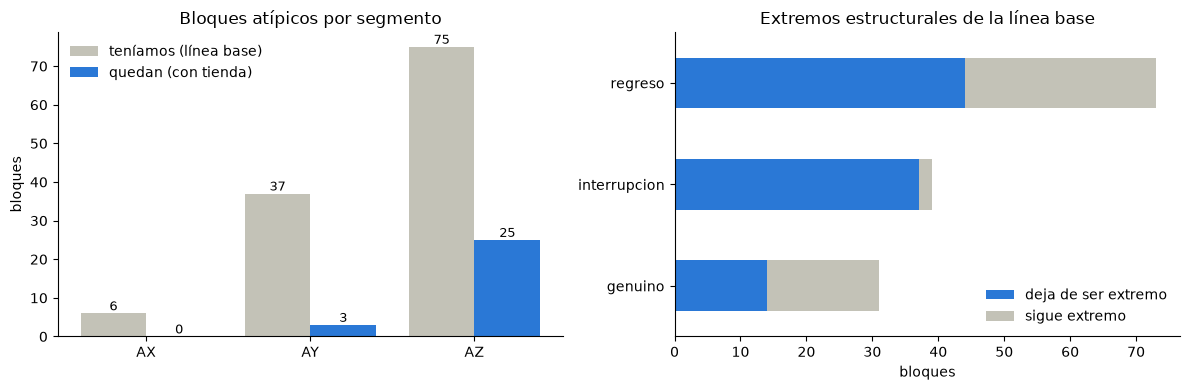

In [61]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(SEG))
ax1.bar(x - 0.2, comp.loc[SEG, "teníamos"], width=0.4, color="#c3c2b7", label="teníamos (línea base)")
ax1.bar(x + 0.2, comp.loc[SEG, "quedan"], width=0.4, color="#2a78d6", label="quedan (con tienda)")
for i, c in enumerate(SEG):
    ax1.text(i - 0.2, comp.loc[c, "teníamos"], comp.loc[c, "teníamos"], ha="center", va="bottom", fontsize=9)
    ax1.text(i + 0.2, comp.loc[c, "quedan"], comp.loc[c, "quedan"], ha="center", va="bottom", fontsize=9)
ax1.set(xticks=x, xticklabels=SEG, title="Bloques atípicos por segmento", ylabel="bloques")
ax1.legend(frameon=False)
ct = pd.crosstab(st["clase"], st["con tienda"]).reindex(columns=["deja de ser extremo", "sigue extremo"]).fillna(0)
ct.plot.barh(stacked=True, ax=ax2, color=["#2a78d6", "#c3c2b7"], legend=False)
ax2.set(title="Extremos estructurales de la línea base", xlabel="bloques", ylabel="")
ax2.legend(frameon=False, loc="lower right")
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**Ejemplos:** 3 artículos al azar de cada segmento (con la semilla de `params.toml`) entre los que tenían algún bloque atípico en la línea base y ya no lo tienen. Mismo gráfico de la 5.1.


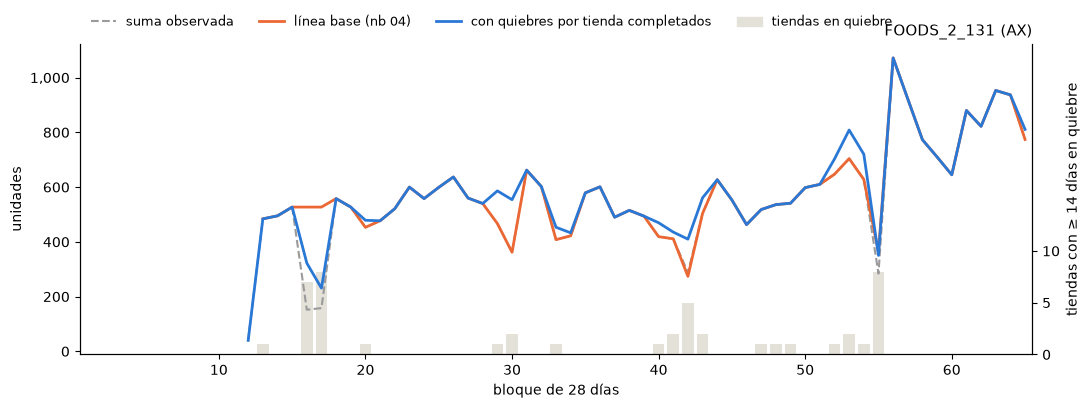

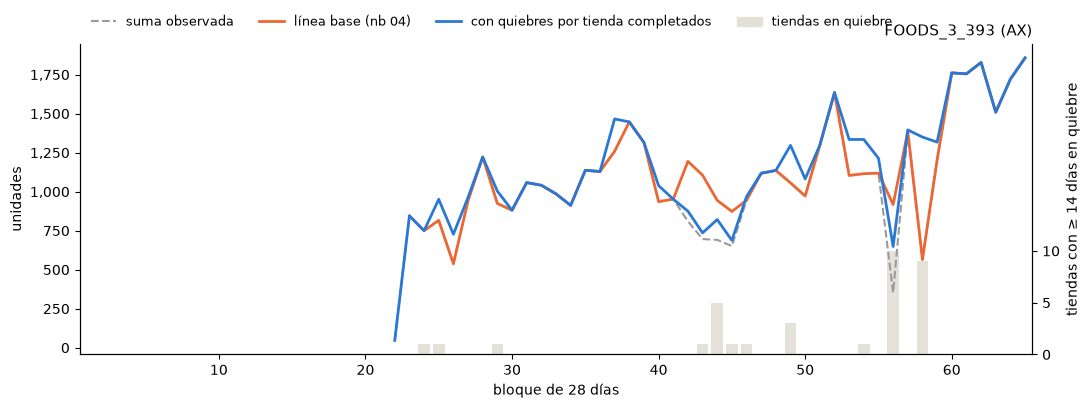

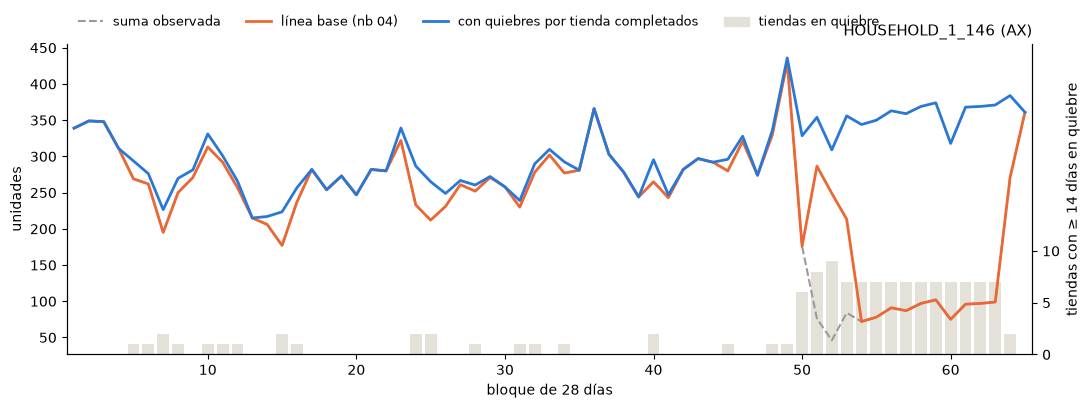

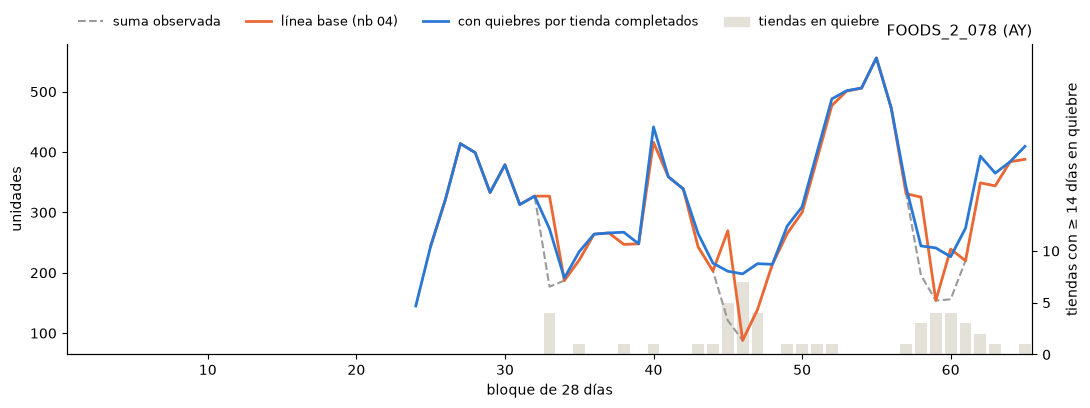

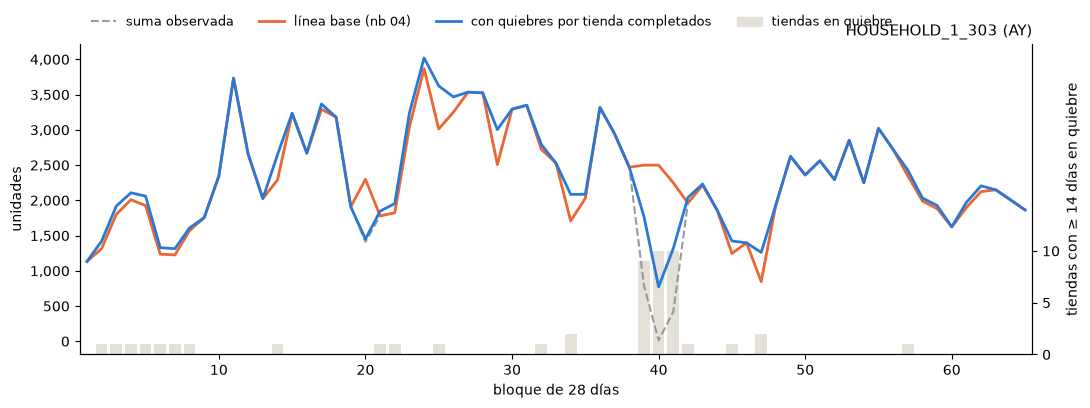

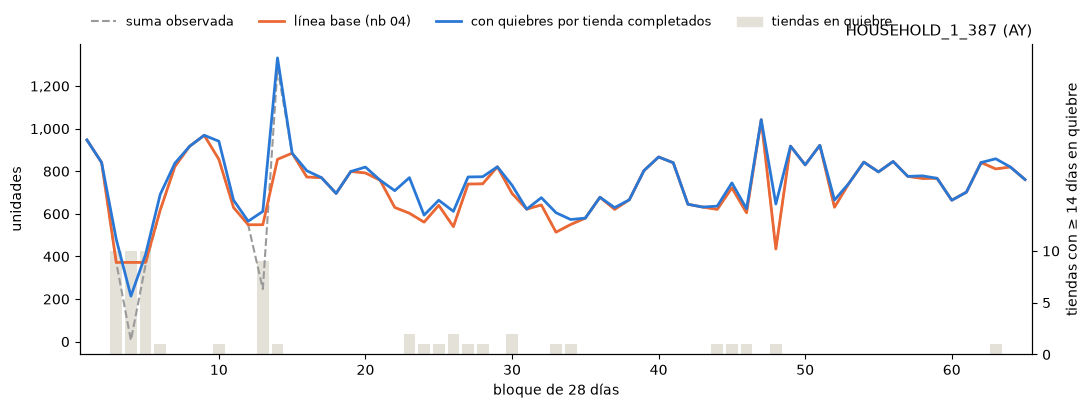

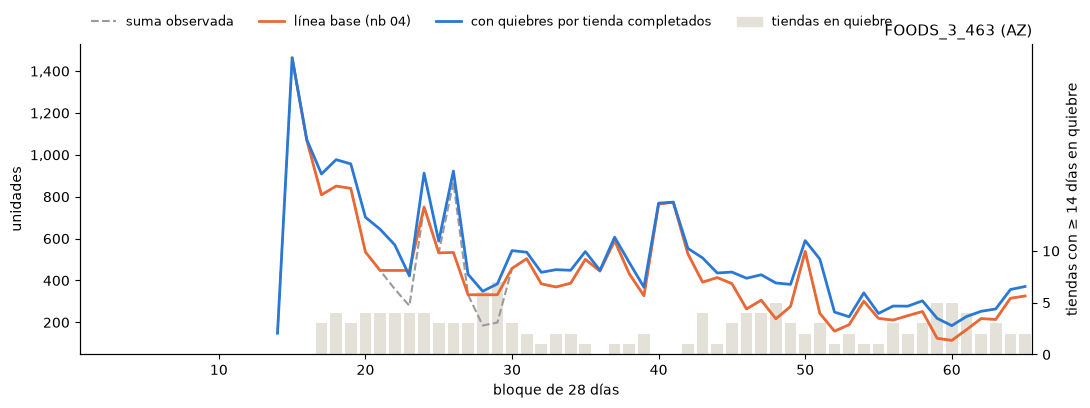

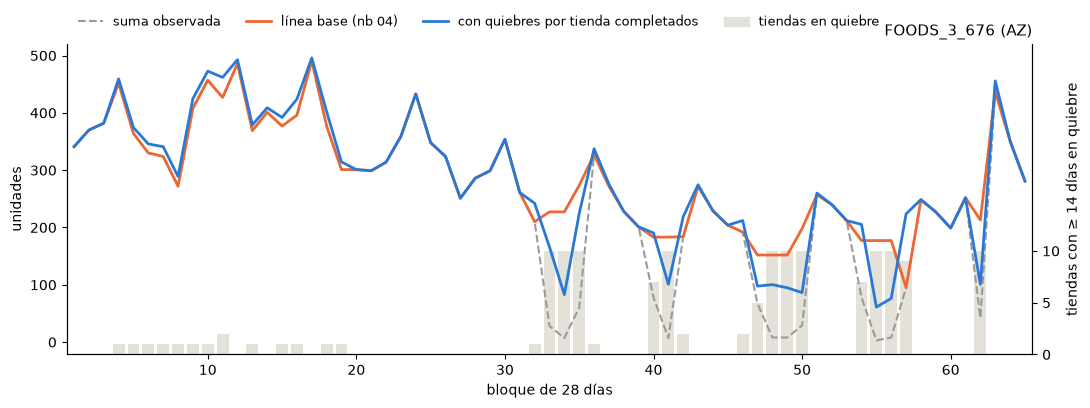

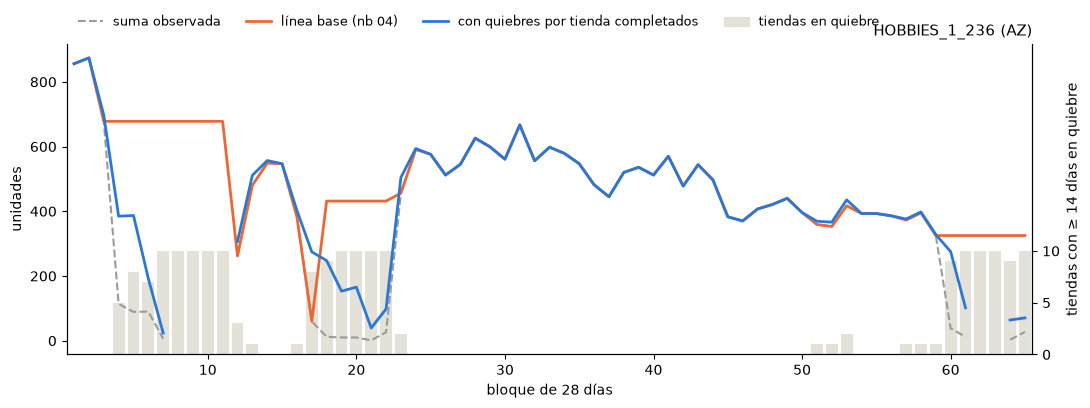

In [62]:
fixed_items = sorted(set(atyp_base_c["item_id"]) - set(atyp_store["item_id"]))
rng = np.random.default_rng(FE["seed"])
for c in SEG:
    pool = [i for i in fixed_items if item_cell[i] == c]
    for item in sorted(rng.choice(pool, size=min(3, len(pool)), replace=False)):
        plot_store_example(item)

## Etapa 8 (nb 04, Etapa 5) · Variables de calendario

**Objetivo:** construir, por bloque de 28 días, las variables de calendario que se conocen de antemano (constitución, Principio II): año, periodo del año y eventos.
**Entradas:** `calendar` (Etapa 1) y `blocks_model` (Etapa 4).
**Salidas:** `block_cal` (una fila por bloque, 1–65) y `blocks_model` con `year`, `period` y los conteos de eventos por tipo (`n_religious`, `n_national`, `n_cultural`, `n_sporting`).
**Decisión (D4, aprobada):**
- `year` = año de análisis como **entero** (1–5, contando desde d_122). En árboles, el año 5 cae en la rama "≥ 4": no extrapola tendencia, pero tampoco rompe nada.
- `period` = periodo del año 1–13 como **categórica ordinal**. 13 bloques = 364 días = 52 semanas, así que el periodo p cae en las mismas semanas cada año (deriva de un día por año). El periodo 1 empieza a fines de mayo y el 8 contiene Navidad.
- Año y periodo son del calendario, no del artículo: valen lo mismo para todos los artículos en un bloque, aunque su test no sea el año 5.


In [63]:
from src.features import EVENT_TYPES, block_calendar

### 5.1 · Año y periodo

**Revisar:** 65 bloques, 13 periodos por año y las fechas que cubre cada periodo.


In [64]:
block_cal = block_calendar(calendar, START_D, 65)

In [65]:
PERIOD_DTYPE = pd.CategoricalDtype(range(1, 14), ordered=True)
blocks_model = blocks_model.merge(block_cal[["block", "year", "period"]], on="block", how="left", validate="many_to_one")
blocks_model["period"] = blocks_model["period"].astype(PERIOD_DTYPE)

In [66]:
assert len(block_cal) == 65 and (block_cal.groupby("year").size() == 13).all()
assert blocks_model[["year", "period"]].notna().all().all() and blocks_model["period"].cat.ordered
dates_by_period = (blocks.drop_duplicates("block").merge(block_cal[["block", "year", "period"]], on="block")
                   .groupby("period").agg(primer_inicio=("start_date", "min"), último_fin=("end_date", "max")))
display(dates_by_period)
display(blocks_model[["item_id", "block", "year", "period", "split", "backtest"]].head())
print(blocks_model[["year", "period"]].dtypes)

,primer_inicio,último_fin
period,,
1,2011-05-30,2015-06-21
2,2011-06-27,2015-07-19
3,2011-07-25,2015-08-16
4,2011-08-22,2015-09-13
5,2011-09-19,2015-10-11
6,2011-10-17,2015-11-08
7,2011-11-14,2015-12-06
8,2011-12-12,2016-01-03
9,2012-01-09,2016-01-31


,item_id,block,year,period,split,backtest
0,FOODS_1_004,12,1,12,train,False
1,FOODS_1_004,13,1,13,train,False
2,FOODS_1_004,14,2,1,train,False
3,FOODS_1_004,15,2,2,train,False
4,FOODS_1_004,16,2,3,train,False


year         int64
period    category
dtype: object


### 5.2 · Eventos: qué hay y cómo llevarlo a bloque

**Qué hace:** cuenta los eventos de cada bloque. En M5 cada día trae dos columnas de evento: `event_name_1/event_type_1` y `event_name_2/event_type_2`. **No son dos clasificaciones:** la columna 2 solo se usa cuando un día tiene dos eventos a la vez. La clasificación de verdad es `event_type`, con 4 tipos: Religious, National, Cultural y Sporting.
**Revisar:** en cuántos bloques vale 1 cada bandera aprobada en la Etapa 0 (hay evento, columna 1, columna 2) y cómo se reparten los conteos por tipo.


In [67]:
ev = pd.concat([calendar[["event_name_1", "event_type_1"]].set_axis(["evento", "tipo"], axis=1),
                calendar[["event_name_2", "event_type_2"]].set_axis(["evento", "tipo"], axis=1)]).dropna().drop_duplicates()
display(ev.groupby("tipo")["evento"].apply(lambda s: ", ".join(sorted(s))).to_frame("eventos"))
display(calendar.loc[calendar["event_name_2"].notna() & calendar["d_num"].between(START_D, END_D),
                     ["date", "event_name_1", "event_type_1", "event_name_2", "event_type_2"]])

,eventos
tipo,
Cultural,"Cinco De Mayo, Easter, Father's day, Halloween..."
National,"Christmas, ColumbusDay, IndependenceDay, Labor..."
Religious,"Chanukah End, Eid al-Fitr, EidAlAdha, LentStar..."
Sporting,"NBAFinalsEnd, NBAFinalsStart, SuperBowl"


,date,event_name_1,event_type_1,event_name_2,event_type_2
827,2013-05-05,OrthodoxEaster,Religious,Cinco De Mayo,Cultural
1177,2014-04-20,Easter,Cultural,OrthodoxEaster,Religious
1233,2014-06-15,NBAFinalsEnd,Sporting,Father's day,Cultural


In [68]:
flags = ["has_event", "has_event_1", "has_event_2"]
counts = [f"n_{t.lower()}" for t in EVENT_TYPES]
summary = pd.DataFrame({
    "bloques con valor ≥ 1 (de 65)": (block_cal[flags + counts] > 0).sum(),
    "máximo por bloque": block_cal[flags + counts].max(),
    # Si en un periodo el valor es igual todos los años, el periodo ya lo explica; si cambia, el evento aporta algo más.
    "periodos donde cambia entre años (de 13)": block_cal.groupby("period")[flags + counts].nunique().gt(1).sum(),
})
display(summary)
assert (block_cal["has_event"] == block_cal["has_event_1"]).all(), "la columna 1 coincide con 'hay evento'"
display(block_cal.pivot_table(index="period", columns="year", values="n_events", aggfunc="sum"))

,bloques con valor ≥ 1 (de 65),máximo por bloque,periodos donde cambia entre años (de 13)
has_event,62,1,3
has_event_1,62,1,3
has_event_2,3,1,3
n_religious,38,3,13
n_national,42,2,2
n_cultural,28,2,2
n_sporting,10,2,2


year,1,2,3,4,5
period,,,,,
1,4,4,4,4,5
2,1,2,2,2,2
3,1,1,1,1,0
4,2,1,1,1,1
5,1,1,0,1,1
6,3,3,3,2,2
7,1,1,3,2,2
8,4,3,2,3,3
9,2,3,3,3,2


### 5.3 · Decisión sobre eventos y otras covariables

**Lo que muestran los datos (5.2):** a nivel diario un festivo es raro (162 de 1,820 días), pero un bloque de 28 días casi siempre contiene alguno. "Hay evento" vale 1 en 62 de 65 bloques. "Columna 1" es idéntica a "hay evento", porque cuando hay un evento siempre está en la columna 1. "Columna 2" vale 1 en 3 bloques: solo se llena cuando un día tiene dos eventos.

**Decisión (usuario):** en lugar de banderas, se usa **la cantidad de eventos de cada tipo en el bloque**: `n_religious`, `n_national`, `n_cultural` y `n_sporting`. Un bloque puede tener eventos de varios tipos a la vez; por ejemplo, el bloque 47 tiene Chanukah End (religioso), Christmas y NewYear (nacionales): `n_religious = 1` y `n_national = 2`. Los conteos se conocen de antemano. Sus rezagos t−1 y t−2 y el adelanto t+1 se arman en la Etapa 6b. Qué tanto aporta cada uno se mide en la Etapa 8 y en los modelos.

**Otras covariables (decisión del usuario: no se agregan):** se evaluaron el precio medio de venta del bloque (o su versión relativa a los 13 bloques anteriores) y los días SNAP por bloque (7 a 10, con poca variación). Las covariables del modelo son solo las de calendario: año, periodo y los conteos de eventos con sus rezagos (Etapa 6b).


In [69]:
EVENT_COUNTS = [f"n_{t.lower()}" for t in EVENT_TYPES]
blocks_model = blocks_model.merge(block_cal[["block", *EVENT_COUNTS]], on="block", how="left", validate="many_to_one")

In [70]:
assert blocks_model[EVENT_COUNTS].notna().all().all()
display(pd.DataFrame({c: block_cal[c].value_counts().sort_index() for c in EVENT_COUNTS}).fillna(0).astype(int)
        .rename_axis("eventos en el bloque").T.assign(total_bloques=65))
display(blocks_model[["item_id", "block", "year", "period", *EVENT_COUNTS, "split", "backtest"]].head())
print("blocks_model:", blocks_model.shape)

eventos en el bloque,0,1,2,3,total_bloques
n_religious,27,28,8,2,65
n_national,23,34,8,0,65
n_cultural,37,21,7,0,65
n_sporting,55,5,5,0,65


,item_id,block,year,period,n_religious,n_national,n_cultural,n_sporting,split,backtest
0,FOODS_1_004,12,1,12,2,0,1,0,train,False
1,FOODS_1_004,13,1,13,0,0,2,0,train,False
2,FOODS_1_004,14,2,1,0,1,1,2,train,False
3,FOODS_1_004,15,2,2,1,1,0,0,train,False
4,FOODS_1_004,16,2,3,1,0,0,0,train,False


blocks_model: (31681, 21)


## Etapa 9 (nb 04, Etapa 6) · Feature engineering (modelos de boosting)

**Reglas comunes:**
- Todo se calcula **por artículo sobre su serie completa** (train y test juntos), antes de separar. Así los primeros bloques de la ventana de backtesting y del test toman sus rezagos del final del tramo anterior (la "memoria"). No hay fuga: con h = 1 solo se usan bloques ya observados en el origen, y los eventos se conocen de antemano.
- Los rezagos, ventanas y estadísticos se leen de `params.toml` (`[features]`), con su historial de cambios (constitución, Principio III).
- SARIMAX no usa estas variables del objetivo: su componente AR cumple ese papel (Etapa 9).


### 6a · Objetivo (ratio), sus rezagos y ventanas móviles

**Objetivo:** construir el objetivo y dar a los modelos de boosting la historia reciente y estacional de cada artículo.
**Entradas:** `blocks_model` (Etapas 4–5, con los bloques no válidos ya completados y sin bloques iniciales no válidos) y `cfg["features"]`.
**Salidas:** `features` = `blocks_model` + `units_prev`, `ratio` (tratado), `ratio_raw` (sin tratar), `ratio_treated`, `ratio_lag<k>` y `ratio_roll<k>_<stat>`.
**Decisión:**
- **Objetivo = ratio** = unidades del bloque ÷ unidades del bloque anterior, sin transformar (decisión del usuario). r > 1: el bloque vendió más que el anterior; r < 1: vendió menos. El pronóstico en unidades es `units_prev` × r̂ y el error se mide en unidades. Queda en NaN solo en el primer bloque de cada artículo; esas filas no entran al entrenamiento.
- **Tratamiento ANTES de rezagos y ventanas (decisión del usuario, Etapa 11):** es la red de seguridad para lo que la 4.2b y la 4.4 no corrigen (arranques, cambios de nivel reales y los casos de la ventana y el test que ninguna regla causal alcanza). Si el ratio supera `max_ratio = 2.0` (`params.toml`, con historial), `ratio` queda vacío (NaN). Así los rezagos, las ventanas y los datasets ya lo reflejan.
  - **No se imputa ni se borra la fila:** `ratio_raw` conserva el ratio real y `ratio_treated` la marca, para identificar y reportar la afectación. La fila se pronostica (`units_prev` × r̂) y se mide en unidades reales.
  - **Arranque (E11, 4.4):** en las posiciones ≤ `case_start_blocks = 7` también queda vacío el ratio < `min_ratio_start = 0.5` (simétrico de 2): esos bloques no tienen historia para imputar y su caída no refleja la demanda.
  - **Ajuste:** no entra al de ningún modelo. En boosting se entrena con las filas de ratio no nulo; en SARIMAX el filtro de Kalman trata el NaN como faltante (pmdarima no acepta NaN: los órdenes se buscan con statsmodels, Etapa 12).
  - **Por qué:** un ratio > 2 casi siempre viene de un denominador deprimido (bloque anterior con días enmascarados, completado o en arranque). Con pérdida cuadrática, esas filas (≈ 2 %) dominan la pérdida y empujan al alza el pronóstico de las filas normales (+6,6 % de sesgo mediano en el proxy).
  - **Por qué 2 (R4):** "la demanda se duplica". En train estricto (antes de la ventana; la validación no se usa), y ya con la 4.2a, la 4.2b y la 4.4 aplicadas, un ratio > 2 aparece en el 0,34 % de las filas con denominador limpio y en el 1,9 % con denominador afectado; el 64 % de los ratios > 2 viene de un denominador afectado. La celda de chequeo lo recalcula.
  - **Evidencia del debate de la Etapa 11** (5 propuestas; boosting proxy de sklearn con los 13 folds y 3 semillas; SARIMAX ARIMA(1,0,1) en 120 artículos; detalle fuera del notebook). Se probó como exclusión del ajuste, sin cambiar los rezagos:

    | Variante | RMSSE medio | RMSSE mediano | Le gana al snaive |
    |---|---|---|---|
    | Base (boosting proxy) | 0,628 ± 0,021 | 0,549 | 82,1 % |
    | Ratio > 2 fuera del ajuste | 0,532 ± 0,001 | 0,482 | 91,6 % |
    | SARIMAX: base → ratio > 2 fuera del ajuste | 1,498 → 0,659 | | |

  - **Riesgos:** el modelo no aprende el tamaño de los rebotes reales (en validación, las filas con ratio > 2 se subestiman ≈ 62 %); se reportan aparte por causa. En SARIMAX el umbral pesa (3 → 0,80; 10 → 1,26): se revisa en el piloto de la Etapa 12 (R7).
- **Rezagos `target_lags = [1, 2, 3, 13]`** (en `params.toml`). Con h = 1 todos son válidos. 1–3 captan la dinámica de los últimos ~3 meses; 13 es el mismo periodo del año anterior, la referencia estacional. No se agregan 4–12: se solapan con las ventanas.
- **Ventanas `rolling_windows = [3, 6, 13]` bloques**, con media, desviación estándar, mediana y rango (máximo − mínimo). 3 ≈ trimestre, 6 ≈ semestre y 13 = un año completo, que cubre el ciclo estacional. Se usa 13 en vez de 12 porque el año tiene 13 bloques.
- **Ninguna ventana incluye el bloque del registro:** shift(1) antes de rolling. La ventana exige sus k bloques anteriores; en los primeros bloques de cada artículo queda NaN (arranque), que las librerías de boosting manejan.
- **Bloques tratados dentro de una ventana (decisión del usuario):** cuentan como historia (el arranque no cambia), pero su valor se omite del estadístico. El estadístico solo queda vacío si todos los bloques de la ventana están tratados (la desviación estándar necesita 2 valores). Exigir la ventana completa habría sumado miles de nulos a la ventana de 13, también en test.


In [71]:
from src.features import add_lags, add_ratio, add_rolling, treat_ratio

FEAT = cfg["features"]
TARGET_COL = "ratio"
MAX_RATIO = FEAT["max_ratio"]
MIN_RATIO_START, START_BLOCKS = FEAT["min_ratio_start"], FEAT["case_start_blocks"]   # E11 (4.4)
assert MAX_RATIO == 2.0
display(pd.Series(FEAT, name="valor").to_frame())

,valor
target_lags,"[1, 2, 3, 13]"
rolling_windows,"[3, 6, 13]"
rolling_stats,"[mean, std, median, range]"
event_lags,"[1, 2]"
low_block_share,0.1
low_block_window,6
atypical_level,0.5
atypical_min_ref,3
atypical_years,3
atypical_level_masked,0.8


In [72]:
features = add_ratio(blocks_model)

In [73]:
features = treat_ratio(features, MAX_RATIO, MIN_RATIO_START, START_BLOCKS)

In [74]:
# Tratamiento: ratio vacío exactamente donde el ratio sin tratar supera 2, o es < 0,5 en el arranque (E11); las unidades no cambian.
has = features["ratio_raw"].notna()
start_low = (features["ratio_raw"] < MIN_RATIO_START) & (features["pos"] <= START_BLOCKS)
assert features["ratio_treated"].eq((features["ratio_raw"] > MAX_RATIO) | start_low).all()
print(f"tratadas: {int(features['ratio_treated'].sum())} (ratio > {MAX_RATIO}: {int((features['ratio_raw'] > MAX_RATIO).sum())}; "
      f"< {MIN_RATIO_START} en el arranque: {int(start_low.sum())})")
assert features["ratio"].isna().eq(~has | features["ratio_treated"]).all()
assert np.allclose(features.loc[has, "units_prev"] * features.loc[has, "ratio_raw"], features.loc[has, "units"])

# Causa del denominador (bloque t − 1), para justificar el umbral y para el reporte.
# 28 = bloque completo; 6 = low_block_window (la ventana de la regla low_units de la 4.2).
f = features.sort_values(["item_id", "block"])
cause = pd.Series(np.select(
    [f.groupby("item_id")["imputed"].shift(1).fillna(False).astype(bool),
     f.groupby("item_id")["days_with_data"].shift(1) < 28,
     f["pos"] <= FEAT["low_block_window"]],
    ["anterior completado", "anterior con días enmascarados", f"primeros {FEAT['low_block_window']} bloques"],
    default="sin causa identificada"), index=f.index)
features["denominator_cause"] = cause.reindex(features.index)
d = features[has]
strict = d[(d["split"] == "train") & ~d["backtest"]]                # train estricto: antes de la ventana
clean = strict["denominator_cause"] == "sin causa identificada"
display(pd.DataFrame({
    "filas": strict.groupby("denominator_cause").size(),
    "ratio > 2": strict.groupby("denominator_cause")["ratio_raw"].apply(lambda s: int((s > MAX_RATIO).sum())),
    "% con ratio > 2": (strict.groupby("denominator_cause")["ratio_raw"].apply(lambda s: (s > MAX_RATIO).mean()) * 100).round(2),
}).rename_axis("causa del denominador (train estricto)"))
hi = strict["ratio_raw"] > MAX_RATIO
print(f"train estricto: ratio > 2 en {hi[clean].mean():.2%} de las filas con denominador limpio "
      f"y en {hi[~clean].mean():.2%} con denominador afectado; "
      f"{(~clean[hi]).mean():.0%} de los ratios > 2 vienen de un denominador afectado")
display(strict.loc[clean, "ratio_raw"].quantile([0.95, 0.99, 0.995, 0.999]).round(2).rename("cuantil del ratio (denominador limpio)").to_frame())

# Filas tratadas por causa y tramo: la afectación sigue identificada.
tramo = np.where(d["split"] == "test", "test", np.where(d["backtest"], "ventana de backtesting", "train antes de la ventana"))
t = d["ratio_treated"].to_numpy()
display(pd.crosstab(d.loc[t, "denominator_cause"], tramo[t], margins=True, margins_name="total", rownames=["causa"], colnames=["tramo"]))
display(d.loc[t, ["item_id", "block", "split", "backtest", "units_prev", "units", "ratio_raw", "ratio", "denominator_cause"]]
        .sample(8, random_state=FEAT["seed"]).sort_values(["item_id", "block"]))

tratadas: 105 (ratio > 2.0: 102; < 0.5 en el arranque: 3)


,filas,ratio > 2,% con ratio > 2
causa del denominador (train estricto),,,
anterior completado,129,2,1.55
anterior con días enmascarados,55,5,9.09
primeros 6 bloques,2558,35,1.37
sin causa identificada,14980,39,0.26


train estricto: ratio > 2 en 0.26% de las filas con denominador limpio y en 1.53% con denominador afectado; 52% de los ratios > 2 vienen de un denominador afectado


,cuantil del ratio (denominador limpio)
0.950,1.30
0.990,1.62
0.995,1.77
0.999,2.70


tramo,test,train antes de la ventana,ventana de backtesting,total
causa,,,,
anterior completado,0,3,0,3
anterior con días enmascarados,0,5,2,7
primeros 6 bloques,0,36,0,36
sin causa identificada,10,40,9,59
total,10,84,11,105


,item_id,block,split,backtest,units_prev,units,ratio_raw,ratio,denominator_cause
6853,FOODS_3_069,6,train,False,308.928571,916.178571,2.965665,NaN,primeros 6 bloques
7998,FOODS_3_134,49,train,True,922.000000,2036.785714,2.209095,NaN,sin causa identificada
8216,FOODS_3_146,13,train,False,145.607143,335.821429,2.306353,NaN,anterior completado
10733,FOODS_3_313,13,train,False,1301.607143,4450.714286,3.419399,NaN,sin causa identificada
14418,FOODS_3_540,8,train,False,414.000000,1182.214286,2.855590,NaN,sin causa identificada
14867,FOODS_3_571,8,train,False,289.892857,863.392857,2.978317,NaN,sin causa identificada
24126,HOUSEHOLD_1_127,5,train,False,67.000000,186.250000,2.779851,NaN,primeros 6 bloques
30924,HOUSEHOLD_2_294,23,train,False,94.785714,231.714286,2.444612,NaN,sin causa identificada


In [75]:
features = add_lags(features, [TARGET_COL], FEAT["target_lags"])

In [76]:
features = add_rolling(features, TARGET_COL, FEAT["rolling_windows"], FEAT["rolling_stats"], treated_col="ratio_treated")

In [77]:
lag_cols = [f"{TARGET_COL}_lag{k}" for k in FEAT["target_lags"]]
roll_cols = [f"{TARGET_COL}_roll{k}_{s}" for k in FEAT["rolling_windows"] for s in FEAT["rolling_stats"]]
assert len(features) == len(blocks_model) and set(lag_cols + roll_cols) <= set(features.columns)
print(f"features: {features.shape} · {len(lag_cols)} rezagos y {len(roll_cols)} estadísticos móviles")

# Objetivo sin tratar: NaN solo en el primer bloque de cada artículo.
has = features["ratio_raw"].notna()
assert ((~has) == (features.groupby("item_id").cumcount() == 0)).all()
print(f"filas sin ratio (1.er bloque): {int((~has).sum())} · tratadas (ratio > {MAX_RATIO} o < {MIN_RATIO_START} en el arranque): {int(features['ratio_treated'].sum())} · "
      f"bloques completados (4.2, 4.2b y 4.4): {int((features['imputed'] & has).sum())}")
display(features[["ratio_raw", "ratio"]].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T)

# Nulos por columna y tramo: de arranque o de tratamiento.
part = np.where(features["split"] == "test", "test", np.where(features["backtest"], "train: ventana de backtesting", "train: antes de la ventana"))
nulls = features[lag_cols + roll_cols].isna().groupby(part).sum().T
display(nulls)

# Rezagos: el rezago k es el ratio TRATADO de k bloques antes (vacío si ese bloque está tratado).
f = features.sort_values(["item_id", "block"])
for k in FEAT["target_lags"]:
    exp = f.groupby("item_id")[TARGET_COL].shift(k)
    assert ((f[f"{TARGET_COL}_lag{k}"].isna() & exp.isna()) | np.isclose(f[f"{TARGET_COL}_lag{k}"], exp)).all()
# En test, todo nulo de un rezago viene del tratamiento (no hay arranque).
test = f["split"] == "test"
for k in FEAT["target_lags"]:
    treated_k = f.groupby("item_id")["ratio_treated"].shift(k).fillna(False).astype(bool)
    assert f.loc[test, f"{TARGET_COL}_lag{k}"].isna().eq(treated_k[test]).all()

# Media móvil de 3: los 3 bloques anteriores, sin el actual, omitiendo los tratados.
def manual_mean(g, k):
    vals = g[TARGET_COL].shift(1)
    hist = (g[TARGET_COL].notna() | g["ratio_treated"]).shift(1, fill_value=False).astype(float)
    full = hist.rolling(k, min_periods=k).sum() == k
    return vals.rolling(k, min_periods=1).mean().where(full)
manual = f.groupby("item_id", group_keys=False)[[TARGET_COL, "ratio_treated"]].apply(lambda g: manual_mean(g, 3))
got = f[f"{TARGET_COL}_roll3_mean"]
assert ((got.isna() & manual.isna()) | np.isclose(got, manual)).all()
display(f[f["item_id"] == "FOODS_3_586"][["block", "split", "units", "units_prev", "ratio_raw", TARGET_COL, *lag_cols, f"{TARGET_COL}_roll3_mean", f"{TARGET_COL}_roll13_mean"]].head(16))

features: (31681, 42) · 4 rezagos y 12 estadísticos móviles
filas sin ratio (1.er bloque): 517 · tratadas (ratio > 2.0 o < 0.5 en el arranque): 105 · bloques completados (4.2, 4.2b y 4.4): 199


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
ratio_raw,31164.0,1.021605,0.556553,0.176541,0.655504,0.782365,0.921208,0.998393,1.084290,1.293303,1.607153,70.901099
ratio,31059.0,1.010947,0.158934,0.176541,0.655779,0.782214,0.920904,0.997950,1.083172,1.283436,1.538293,1.992790


,test,train: antes de la ventana,train: ventana de backtesting
ratio_lag1,10,1118,11
ratio_lag2,9,1631,15
ratio_lag3,9,2148,15
ratio_lag13,11,7302,20
ratio_roll3_mean,0,2068,0
ratio_roll3_std,2,2075,2
ratio_roll3_median,0,2068,0
ratio_roll3_range,0,2068,0
ratio_roll6_mean,0,3619,0
ratio_roll6_std,0,3619,0


,block,split,units,units_prev,ratio_raw,ratio,ratio_lag1,ratio_lag2,ratio_lag3,ratio_lag13,ratio_roll3_mean,ratio_roll13_mean
15185,1,train,14983.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15186,2,train,15156.000000,14983.000000,1.011546,1.011546,NaN,NaN,NaN,NaN,NaN,NaN
15187,3,train,17599.000000,15156.000000,1.161190,1.161190,1.011546,NaN,NaN,NaN,NaN,NaN
15188,4,train,16698.000000,17599.000000,0.948804,0.948804,1.161190,1.011546,NaN,NaN,NaN,NaN
15189,5,train,16198.000000,16698.000000,0.970056,0.970056,0.948804,1.161190,1.011546,NaN,1.040514,NaN
15190,6,train,15721.000000,16198.000000,0.970552,0.970552,0.970056,0.948804,1.161190,NaN,1.026683,NaN
15191,7,train,16158.000000,15721.000000,1.027797,1.027797,0.970552,0.970056,0.948804,NaN,0.963137,NaN
15192,8,train,15621.000000,16158.000000,0.966766,0.966766,1.027797,0.970552,0.970056,NaN,0.989468,NaN
15193,9,train,12935.000000,15621.000000,0.828052,0.828052,0.966766,1.027797,0.970552,NaN,0.988372,NaN
15194,10,train,14143.214286,12935.000000,1.093407,1.093407,0.828052,0.966766,1.027797,NaN,0.940872,NaN


### 6a.1 · Ratio interpolado solo para los gráficos

**Objetivo:** que las líneas del ratio en los gráficos (Etapa 13) no se corten ni muestren saltos en los bloques tratados.
**Entradas:** `features` (6a), con `ratio` y `ratio_treated`.
**Salidas:** columna `ratio_plot` en `features`.
**Decisión (usuario):** en cada artículo, un ratio tratado (vacío en `ratio`) toma la interpolación lineal entre el ratio válido anterior y el siguiente. Los demás valores no cambian; los tratados sin un ratio válido a cada lado (al inicio de la serie, donde el anterior es el primer bloque, o al final) siguen vacíos: la línea empieza o termina ahí, sin cortes en medio. **No entra al modelo:** `ratio` sigue vacío donde está tratado (la bandera `ratio_treated` lo marca), los rezagos y ventanas se calcularon con `ratio`, y los datasets de la Etapa 11 eligen sus columnas (`ratio_plot` no está en `BOOST_FEATURES` ni en las exógenas de SARIMAX).


In [78]:
from src.features import interpolate_treated

In [79]:
features = interpolate_treated(features)

In [80]:
t = features["ratio_treated"]
assert features.loc[~t, "ratio_plot"].equals(features.loc[~t, "ratio"]), "fuera de los tratados es el mismo ratio"
assert features.loc[t, "ratio"].isna().all(), "el ratio del modelo sigue vacío en los tratados"
print(f"tratados: {int(t.sum())} · interpolados para el gráfico: {int(features.loc[t, 'ratio_plot'].notna().sum())}"
      f" · sin ratio válido a un lado, al inicio o al final (siguen vacíos): {int(features.loc[t, 'ratio_plot'].isna().sum())}")
display(features.loc[t, ["item_id", "block", "ratio_raw", "ratio", "ratio_plot"]].head(8))

tratados: 105 · interpolados para el gráfico: 89 · sin ratio válido a un lado, al inicio o al final (siguen vacíos): 16


,item_id,block,ratio_raw,ratio,ratio_plot
66,FOODS_1_012,14,2.352513,NaN,1.078772
195,FOODS_1_023,14,2.248120,NaN,1.358540
435,FOODS_1_046,2,2.286195,NaN,NaN
505,FOODS_1_055,8,0.467737,NaN,1.616936
544,FOODS_1_055,47,2.004003,NaN,0.802664
559,FOODS_1_055,62,2.042781,NaN,0.817020
564,FOODS_1_058,10,2.037403,NaN,NaN
762,FOODS_1_081,14,2.153061,NaN,1.069034


### 6b · Rezagos de los conteos de eventos

**Objetivo:** que el modelo sepa si los bloques anteriores tuvieron eventos.
**Entradas:** `calendar`, `EVENT_COUNTS` (Etapa 5: `n_religious`, `n_national`, `n_cultural`, `n_sporting`), `FEAT["event_lags"]` y `features` (6a).
**Salidas:** `features` + `n_<tipo>_lag<k>` para k en `event_lags`.
**Decisión:**
- **Rezagos `event_lags = [1, 2]`** (en `params.toml`, decisión del usuario).
  - **Rezago 1:** el objetivo es unidades_t ÷ unidades_{t−1}. Si el bloque anterior tuvo un evento (por ejemplo, Navidad o Acción de Gracias), su venta pudo subir, y el ratio del bloque actual tiende a bajar aunque la demanda vuelva a lo normal.
  - **Rezago 2:** también entra en el ratio del bloque anterior (`ratio_lag1`) y ayuda a separar un efecto del evento de un cambio de tendencia.
- **Se calculan sobre el calendario, no sobre la serie del artículo.** Los eventos son iguales para todos los artículos y se conocen de antemano, así que el primer bloque de cada serie tiene sus rezagos completos. Para los bloques 1 y 2 se usan los días anteriores a d_122, que trae el calendario de M5. No hay nulos.
- Los conteos del propio bloque (`n_<tipo>`, Etapa 5) ya están en `features`: se conocen en el origen.


In [81]:
from src.features import calendar_lags

In [82]:
event_lags = calendar_lags(calendar, START_D, 65, EVENT_COUNTS, FEAT["event_lags"])
features = features.merge(event_lags, on="block", how="left", validate="many_to_one")

In [83]:
event_lag_cols = [f"{c}_lag{k}" for c in EVENT_COUNTS for k in FEAT["event_lags"]]
assert len(features) == len(blocks_model) and set(event_lag_cols) <= set(features.columns)
assert features[event_lag_cols].notna().all().all(), "sin nulos: el calendario cubre los bloques previos"
print(f"features: {features.shape} · {len(event_lag_cols)} rezagos de eventos")

# Desde el bloque 3 el rezago coincide con desplazar el calendario de la Etapa 5.
cal_shift = block_cal.set_index("block")[EVENT_COUNTS]
for k in FEAT["event_lags"]:
    expected = cal_shift.shift(k).loc[k + 1:]
    got = event_lags.set_index("block").loc[k + 1:, [f"{c}_lag{k}" for c in EVENT_COUNTS]]
    assert (got.to_numpy() == expected.to_numpy()).all()
display(pd.Series({c: int((event_lags[c] > 0).sum()) for c in event_lag_cols}, name="bloques con valor ≥ 1 (de 65)").to_frame().T)

# Muestra: periodos 7–9 del año 1 (Acción de Gracias y Navidad) de un artículo.
display(features[(features["item_id"] == "FOODS_3_586") & features["block"].between(6, 10)]
        [["block", "period", "n_national", "n_national_lag1", "n_national_lag2", "n_religious", "n_religious_lag1", "units", "ratio"]])

features: (31681, 51) · 8 rezagos de eventos


,n_religious_lag1,n_religious_lag2,n_national_lag1,n_national_lag2,n_cultural_lag1,n_cultural_lag2,n_sporting_lag1,n_sporting_lag2
bloques con valor ≥ 1 (de 65),37,38,42,42,28,29,10,10


,block,period,n_national,n_national_lag1,n_national_lag2,n_religious,n_religious_lag1,units,ratio
15190,6,6,1,1,1,1,0,15721.000000,0.970552
15191,7,7,1,1,1,0,1,16158.000000,1.027797
15192,8,8,2,1,1,2,0,15621.000000,0.966766
15193,9,9,1,2,1,0,2,12935.000000,0.828052
15194,10,10,1,1,2,2,0,14143.214286,1.093407


### 6c · Reglas comunes: cálculo antes del split, chequeo por muestra y nulos de arranque

**Objetivo:** comprobar que las variables de la 6a y la 6b están bien construidas antes de usarlas.
**Entradas:** `features` (6a–6b), `blocks_model` (unidades por bloque), `calendar` y `FEAT["seed"]`.
**Salidas:** ninguna variable nueva: solo chequeos y la tabla de nulos de arranque.
**Decisión:**
- **Cálculo antes del split.** `features` tiene train (con la ventana de backtesting) y test juntos, y cada rezago o ventana se calculó por artículo sobre su serie completa. Así los primeros bloques de la ventana y del test toman su memoria del final del tramo anterior. Con h = 1 no hay fuga: todo rezago ≥ 1 usa bloques ya observados en el origen, y los eventos se conocen de antemano. La Etapa 7 verifica esa memoria en la frontera de cada tramo.
- **Chequeo por muestra.** Para filas al azar se recalculan a mano, sin usar las funciones de `src/` ni la columna `ratio`, cinco variables: dos rezagos del objetivo (`ratio_lag1`, `ratio_lag13`), dos ventanas (`ratio_roll3_mean`, `ratio_roll13_std`) y un rezago de evento (`n_national_lag1`). El ratio se rehace desde las unidades por bloque, con el mismo tratamiento (ratio > 2 vacío; en las ventanas, el bloque tratado cuenta como historia y su valor se omite), y el evento desde los días crudos del calendario.
  - **200 filas.** Si al menos el 1,5 % de las filas tuviera un error, la probabilidad de que una muestra de 200 no encuentre ninguno es 0,985^200 ≈ 5 %. Recalcular 200 filas tarda menos de un segundo.
  - **Semilla:** `features.seed = 42` en `params.toml`, con su historial (R6). El valor no importa, solo que sea fijo.
- **Nulos de arranque:** se reportan por columna y por tramo.


In [84]:
SEED = FEAT["seed"]
sample = features.sample(n=200, random_state=SEED)

In [85]:
# Recalculo independiente: unidades por (artículo, bloque) y eventos nacionales por día del calendario.
units_of = blocks_model.set_index(["item_id", "block"])["units"].to_dict()
pos_of = blocks_model.set_index(["item_id", "block"])["pos"].to_dict()
day_num = calendar["d"].str.removeprefix("d_").astype(int)
national_by_day = ((calendar["event_type_1"] == "National").astype(int) + (calendar["event_type_2"] == "National").astype(int))
national_by_day = dict(zip(day_num, national_by_day))

def ratio_at(item, b):
    # None: el bloque no tiene ratio por construcción (no existe o es el primero); NaN: tratado.
    num, den = units_of.get((item, b)), units_of.get((item, b - 1))
    if num is None or den is None:
        return None
    r = num / den
    return np.nan if r > MAX_RATIO or (r < MIN_RATIO_START and pos_of[(item, b)] <= START_BLOCKS) else r

def lag(item, b):
    v = ratio_at(item, b)
    return np.nan if v is None else v

def window(item, b, k):
    vals = [ratio_at(item, b - j) for j in range(1, k + 1)]
    return None if any(v is None for v in vals) else np.array(vals, dtype=float)

def stat(w, fn, min_n):
    if w is None:
        return np.nan
    v = w[~np.isnan(w)]
    return fn(v) if len(v) >= min_n else np.nan

rows = []
for item, b in zip(sample["item_id"], sample["block"]):
    w3, w13 = window(item, b, 3), window(item, b, 13)
    first_day = START_D + 28 * (b - 2)   # primer día del bloque b − 1 (puede ser anterior a d_122)
    rows.append({
        "ratio_lag1": lag(item, b - 1), "ratio_lag13": lag(item, b - 13),
        "ratio_roll3_mean": stat(w3, np.mean, 1),
        "ratio_roll13_std": stat(w13, lambda v: v.std(ddof=1), 2),
        "n_national_lag1": sum(national_by_day[d] for d in range(first_day, first_day + 28)),
        "ventana de 13 con bloque tratado": w13 is not None and bool(np.isnan(w13).any()),
    })
manual = pd.DataFrame(rows, index=sample.index)
with_treated = int(manual.pop("ventana de 13 con bloque tratado").sum())
check = {}
for col in manual.columns:
    got, exp = sample[col].astype(float), manual[col].astype(float)
    same = (got.isna() & exp.isna()) | np.isclose(got, exp, rtol=1e-9, atol=1e-12)
    check[col] = {"filas": len(same), "coinciden": int(same.sum()), "NaN (arranque o tratamiento)": int(exp.isna().sum())}
display(pd.DataFrame(check).T)
print(f"filas de la muestra con algún bloque tratado en su ventana de 13: {with_treated}")
assert all(v["coinciden"] == v["filas"] for v in check.values()), "hay valores que no coinciden con el recálculo manual"
display(sample[["item_id", "block", "split"]].join(manual.add_suffix(" (manual)")).join(sample[manual.columns]).head(5))

,filas,coinciden,NaN (arranque o tratamiento)
ratio_lag1,200,200,4
ratio_lag13,200,200,36
ratio_roll3_mean,200,200,5
ratio_roll13_std,200,200,35
n_national_lag1,200,200,0


filas de la muestra con algún bloque tratado en su ventana de 13: 7


,item_id,block,split,ratio_lag1 (manual),ratio_lag13 (manual),ratio_roll3_mean (manual),ratio_roll13_std (manual),n_national_lag1 (manual),ratio_lag1,ratio_lag13,ratio_roll3_mean,ratio_roll13_std,n_national_lag1
13847,FOODS_3_501,12,train,1.190828,NaN,1.110028,NaN,0,1.190828,NaN,1.110028,NaN,0
9188,FOODS_3_227,17,train,0.942295,0.897618,0.972337,0.082931,0,0.942295,0.897618,0.972337,0.082931,0
3707,FOODS_2_141,50,train,1.164921,0.952087,1.098729,0.126006,1,1.164921,0.952087,1.098729,0.126006,1
5511,FOODS_2_316,19,train,0.846745,0.545139,0.931221,0.397202,1,0.846745,0.545139,0.931221,0.397202,1
13952,FOODS_3_503,52,train,0.872948,1.080388,0.902107,0.096325,0,0.872948,1.080388,0.902107,0.096325,0


In [86]:
feature_cols = lag_cols + roll_cols + event_lag_cols + ["year", "period"] + EVENT_COUNTS
part = np.where(features["split"] == "test", "test", np.where(features["backtest"], "train: ventana de backtesting", "train: antes de la ventana"))
warmup = features[["ratio", *feature_cols]].isna().groupby(part).sum().T
warmup["artículos afectados"] = [features.loc[features[c].isna(), "item_id"].nunique() for c in warmup.index]
display(warmup[warmup.drop(columns="artículos afectados").sum(axis=1) > 0])
print("columnas sin ningún nulo:", ", ".join(warmup.index[warmup.drop(columns="artículos afectados").sum(axis=1) == 0]))
# En test no hay arranque: sus nulos vienen solo del tratamiento (6a): el ratio de las filas tratadas y
# los rezagos que caen en ellas (verificado en la 6a). Las ventanas quedan vacías solo si toda la ventana está tratada.
test = features["split"] == "test"
assert features.loc[test, "ratio"].isna().eq(features.loc[test, "ratio_treated"]).all()
print("nulos en test por tratamiento:", warmup.loc[warmup["test"] > 0, "test"].to_dict())

,test,train: antes de la ventana,train: ventana de backtesting,artículos afectados
ratio,10,601,11,517
ratio_lag1,10,1118,11,517
ratio_lag2,9,1631,15,517
ratio_lag3,9,2148,15,517
ratio_lag13,11,7302,20,517
ratio_roll3_mean,0,2068,0,517
ratio_roll3_std,2,2075,2,517
ratio_roll3_median,0,2068,0,517
ratio_roll3_range,0,2068,0,517
ratio_roll6_mean,0,3619,0,517


columnas sin ningún nulo: n_religious_lag1, n_religious_lag2, n_national_lag1, n_national_lag2, n_cultural_lag1, n_cultural_lag2, n_sporting_lag1, n_sporting_lag2, year, period, n_religious, n_national, n_cultural, n_sporting
nulos en test por tratamiento: {'ratio': 10, 'ratio_lag1': 10, 'ratio_lag2': 9, 'ratio_lag3': 9, 'ratio_lag13': 11, 'ratio_roll3_std': 2}


### 6e · Edad del artículo

**Objetivo:** que el boosting sepa en qué momento de la vida del artículo está cada bloque. Los primeros bloques son más volátiles: 112 de los 589 ratios entre 2 y 10 del train caen en los primeros 6 bloques del artículo (diagnóstico de la Etapa 11).
**Entradas:** `features` con `pos` (Etapa 4.3: posición del bloque en la serie del artículo, desde su primer bloque válido).
**Salidas:** columna `age` en `features`; entra al dataset de boosting en la Etapa 9.
**Decisión (usuario, Etapa 11, propuesta B):**
- **`age` = `pos`:** bloques desde el inicio de la serie del artículo (1 = primer bloque). Solo depende de la posición, que se conoce de antemano: no hay fuga.
- **Sin tope:** el boosting elige dónde cortar; un tope sería un número más sin justificar.
- **Solo boosting.** SARIMAX no la usa: sus exógenas son los 4 conteos de eventos (Etapa 9).
- Se reutiliza `pos` de `assign_windows` (4.3); no hace falta código nuevo en `src/`.


In [87]:
features["age"] = features["pos"].astype(int)

In [88]:
# Edad contigua 1, 2, …, n en cada artículo, sin nulos, y siempre mayor en test que en train.
g = features.sort_values(["item_id", "block"]).groupby("item_id")
assert features["age"].notna().all() and features["age"].min() == 1
assert (g["age"].diff().dropna() == 1).all() and (g["block"].diff().dropna() == 1).all()
last_train = features[features["split"] == "train"].groupby("item_id")["age"].max()
first_test = features[features["split"] == "test"].groupby("item_id")["age"].min()
assert (first_test == last_train + 1).all()
part = np.where(features["split"] == "test", "test", np.where(features["backtest"], "train: ventana de backtesting", "train: antes de la ventana"))
display(features.groupby(part)["age"].describe().round(1))

,count,mean,std,min,25%,50%,75%,max
test,6721.0,55.3,7.6,27.0,53.0,57.0,61.0,65.0
train: antes de la ventana,18239.0,18.8,11.0,1.0,9.0,18.0,28.0,39.0
train: ventana de backtesting,6721.0,42.3,7.6,14.0,40.0,44.0,48.0,52.0


## Etapa 10 (nb 04, Etapa 7) · Split temporal

**Objetivo:** separar train y test con la partición por artículo de la 4.3, y verificar que los primeros bloques de cada tramo toman su memoria (rezagos y ventanas) del final del tramo anterior.
**Entradas:** `features` (Etapa 6), con `split` y `backtest` de la 4.3.
**Salidas:** `train_set` (train, con la ventana de backtesting marcada en `backtest`) y `test_set` (lo usa el nb 05; aquí no se toca).
**Decisión (constitución 4.0.0 y 6.0.0):**
- Por artículo: test = sus últimos 13 bloques; ventana de backtesting = los 13 anteriores (siguen siendo train); el resto es train. Los mismos 517 artículos están en train y en test; lo que se separa son bloques, no artículos.
- La separación se hace **después** de calcular las variables (6c). Así el primer bloque de la ventana toma sus rezagos del final del train anterior, y el primer bloque de test los toma de la ventana. No es fuga: con h = 1 son bloques ya observados en el origen.
- Dentro del test, el bloque k usa como rezagos los bloques de test 1 a k − 1. También es válido: en el origen k esos bloques ya se observaron, y el régimen es de reentrenamiento en cada origen (FR-025).
- 3 artículos tienen un test que no es el año 5 (FOODS_3_441, HOUSEHOLD_1_366 y HOUSEHOLD_1_427, documentado en la 4.3): su test cae en fechas que para otros artículos son train. No es fuga dentro de un artículo; se documenta.

**Revisar:** filas, artículos y fechas de cada tramo; la memoria en las dos fronteras, para todos los artículos.


In [89]:
train_set = features[features["split"] == "train"].reset_index(drop=True)
test_set = features[features["split"] == "test"].reset_index(drop=True)

In [90]:
assert len(train_set) + len(test_set) == len(features)
assert set(train_set["item_id"]) == set(test_set["item_id"]) and train_set["item_id"].nunique() == N_MODEL
assert (test_set.groupby("item_id").size() == TEST_BLOCKS).all()
assert (train_set[train_set["backtest"]].groupby("item_id").size() == VAL_BLOCKS).all()
# En cada artículo el test empieza justo después del último bloque de train.
assert (test_set.groupby("item_id")["block"].min() == train_set.groupby("item_id")["block"].max() + 1).all()

part = np.where(features["split"] == "test", "test", np.where(features["backtest"], "train: ventana de backtesting", "train: antes de la ventana"))
display(features.assign(part=part).groupby("part").agg(
    filas=("block", "size"), artículos=("item_id", "nunique"),
    primer_bloque=("block", "min"), último_bloque=("block", "max"),
    primera_fecha=("start_date", "min"), última_fecha=("end_date", "max"),
).loc[["train: antes de la ventana", "train: ventana de backtesting", "test"]])
display(test_set.groupby("block").size().rename("artículos").to_frame().T)

,filas,artículos,primer_bloque,último_bloque,primera_fecha,última_fecha
part,,,,,,
train: antes de la ventana,18239,517,1,39,2011-05-30,2014-05-25
train: ventana de backtesting,6721,517,38,52,2014-03-31,2015-05-24
test,6721,517,51,65,2015-03-30,2016-05-22


block,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65
artículos,1,2,517,517,517,517,517,517,517,517,517,517,517,516,515


In [91]:
# Memoria en las fronteras, para todos los artículos: valores esperados tomados del tramo anterior.
r = features.set_index(["item_id", "block"])["ratio"]
u = features.set_index(["item_id", "block"])["units"]
first_bt = train_set[train_set["backtest"]].groupby("item_id")["block"].min()
first_test = test_set.groupby("item_id")["block"].min()

def at(series, items, block_nums):
    return series.reindex(pd.MultiIndex.from_arrays([items, block_nums])).to_numpy()

def mean_back(items, block_nums, k):
    return np.nanmean(np.column_stack([at(r, items, block_nums - j) for j in range(1, k + 1)]), axis=1)

memory = {}
for name, first in [("1.er bloque de la ventana", first_bt), ("1.er bloque de test", first_test)]:
    items, blks = first.index.to_numpy(), first.to_numpy()
    row = features.set_index(["item_id", "block"]).reindex(pd.MultiIndex.from_arrays([items, blks]))
    checks = {
        "units_prev = unidades del bloque anterior": (row["units_prev"].to_numpy(), at(u, items, blks - 1)),
        "ratio_lag1 = ratio del bloque anterior": (row["ratio_lag1"].to_numpy(), at(r, items, blks - 1)),
        "ratio_lag13 = ratio de 13 bloques antes": (row["ratio_lag13"].to_numpy(), at(r, items, blks - 13)),
        "ratio_roll3_mean = media de los 3 anteriores": (row["ratio_roll3_mean"].to_numpy(), mean_back(items, blks, 3)),
    }
    for label, (got, exp) in checks.items():
        ok = (np.isnan(got) & np.isnan(exp)) | np.isclose(got, exp)
        memory[(name, label)] = {"artículos": len(ok), "coinciden": int(ok.sum())}
memory = pd.DataFrame(memory).T
display(memory)
assert (memory["coinciden"] == memory["artículos"]).all()

# Ejemplo: frontera ventana → test de un artículo.
ex = "FOODS_3_586"
b0 = first_test[ex]
display(features[(features["item_id"] == ex) & features["block"].between(b0 - 3, b0 + 1)]
        [["block", "split", "backtest", "units", "ratio", "units_prev", "ratio_lag1", "ratio_roll3_mean"]])

artículos  \
1.er bloque de la ventana units_prev = unidades del bloque anterior           517   
                          ratio_lag1 = ratio del bloque anterior              517   
                          ratio_lag13 = ratio de 13 bloques antes             517   
                          ratio_roll3_mean = media de los 3 anteriores        517   
1.er bloque de test       units_prev = unidades del bloque anterior           517   
                          ratio_lag1 = ratio del bloque anterior              517   
                          ratio_lag13 = ratio de 13 bloques antes             517   
                          ratio_roll3_mean = media de los 3 anteriores        517   

                                                                        coinciden  
1.er bloque de la ventana units_prev = unidades del bloque anterior           517  
                          ratio_lag1 = ratio del bloque anterior              517  
                          ratio_lag13 = ratio de 13 bloques antes             517  
                          ratio_roll3_mean = media de los 3 anteriores        517  
1.er bloque de test       units_prev = unidades del bloque anterior           517  
                          ratio_lag1 = ratio del bloque anterior              517  
                          ratio_lag13 = ratio de 13 bloques antes             517  
                          ratio_roll3_mean = media de los 3 anteriores        517

,block,split,backtest,units,ratio,units_prev,ratio_lag1,ratio_roll3_mean
15234,50,train,True,10545.0,0.938000,11242.0,1.130758,0.974439
15235,51,train,True,11153.0,1.057658,10545.0,0.938000,0.946904
15236,52,train,True,11980.0,1.074150,11153.0,1.057658,1.042139
15237,53,test,False,13088.0,1.092487,11980.0,1.074150,1.023269
15238,54,test,False,14180.0,1.083435,13088.0,1.092487,1.074765


## Etapa 11 (nb 04, Etapa 9) · Datasets por modelo

**Objetivo:** dejar listo el dataset de cada tipo de modelo (aquí no se exporta: D1).
**Entradas:** `features` (Etapas 6–7) y el segmento de cada artículo (`targets`).
**Salidas:** `sarimax_data` y `boosting_data` (en memoria; no se exportan).
**Decisión (usuario):**
- **SARIMAX:** la serie del ratio de cada artículo y, como exógenas, los 4 conteos de eventos del bloque t (`n_religious`, `n_national`, `n_cultural`, `n_sporting`). Sin rezagos ni ventanas del objetivo (los cubre su parte AR y estacional), sin año ni periodo (la estacionalidad la cubre su componente estacional, m = 13) y sin rezagos de eventos. SARIMAX no admite nulos en las exógenas: se verifica. Cada exógena agrega un coeficiente que el modelo estima por artículo con los bloques de cada fold.
- **Boosting:** la tabla completa: rezagos y ventanas del ratio (6a), conteos de eventos del bloque y sus rezagos (5 y 6b), año, periodo, edad del artículo (6e), `item_id` y `cell` (boosting global, D3). `item_id`, `cell` y `period` quedan como `category` de pandas: LightGBM la usa directo, XGBoost con `enable_categorical=True` y CatBoost listándolas en `cat_features`. Los nulos de arranque se conservan (las tres librerías los manejan) y se reporta cuántas filas los tienen.
- En los dos se deja fuera la primera fila de cada artículo, que no tiene bloque anterior. **Las filas tratadas (6a: `ratio` vacío) se conservan:** no entran al ajuste, pero se pronostican y se miden. Llevan `ratio_raw` y `ratio_treated` para identificar la afectación.
- Se muestra el dataframe normal y se verifica que tenga ≤ 600.000 filas.


In [92]:
from src.features import boosting_dataset, sarimax_dataset

SARIMAX_EXOG = EVENT_COUNTS
CAT_FEATURES = ["item_id", "cell", "period"]
BOOST_FEATURES = lag_cols + roll_cols + EVENT_COUNTS + event_lag_cols + ["year", "period", "age", "item_id", "cell"]
print(f"SARIMAX: {len(SARIMAX_EXOG)} exógenas · boosting: {len(BOOST_FEATURES)} variables ({len(CAT_FEATURES)} categóricas)")

SARIMAX: 4 exógenas · boosting: 33 variables (3 categóricas)


In [93]:
sarimax_data = sarimax_dataset(features, SARIMAX_EXOG)

In [94]:
assert sarimax_data[SARIMAX_EXOG].notna().all().all() and sarimax_data["ratio_raw"].notna().all()
assert sarimax_data["ratio"].isna().eq(sarimax_data["ratio_treated"]).all()   # vacío solo en las tratadas
assert len(sarimax_data) == len(features) - features["item_id"].nunique()
assert not any(c.startswith(("ratio_lag", "ratio_roll")) for c in sarimax_data.columns)   # sin rezagos ni ventanas
part = np.where(sarimax_data["split"] == "test", "test", np.where(sarimax_data["backtest"], "train: ventana de backtesting", "train: antes de la ventana"))
display(sarimax_data.groupby(part).agg(filas=("block", "size"), artículos=("item_id", "nunique")))
display(sarimax_data.groupby(part)["item_id"].value_counts().groupby(level=0).describe()[["min", "50%", "max"]].rename(columns={"50%": "mediana"}).rename_axis("bloques con ratio por artículo"))
print(sarimax_data.dtypes.to_string())

,filas,artículos
test,6721,517
train: antes de la ventana,17722,517
train: ventana de backtesting,6721,517


,min,mediana,max
bloques con ratio por artículo,,,
test,13.0,13.0,13.0
train: antes de la ventana,12.0,38.0,38.0
train: ventana de backtesting,13.0,13.0,13.0


item_id                     str
block                     int64
start_date       datetime64[us]
split                       str
backtest                   bool
imputed                    bool
units                   float64
units_prev              float64
ratio                   float64
ratio_raw               float64
ratio_treated              bool
n_religious               int64
n_national                int64
n_cultural                int64
n_sporting                int64


In [95]:
boosting_data = boosting_dataset(features, targets.set_index("item_id")["cell"], BOOST_FEATURES, CAT_FEATURES)

In [96]:
assert len(boosting_data) == len(sarimax_data) and boosting_data["ratio_raw"].notna().all()
assert boosting_data["ratio"].isna().eq(boosting_data["ratio_treated"]).all()   # vacío solo en las tratadas
assert all(isinstance(boosting_data[c].dtype, pd.CategoricalDtype) for c in CAT_FEATURES)
assert boosting_data["item_id"].cat.categories.size == N_MODEL and list(boosting_data["cell"].cat.categories) == ["AX", "AY", "AZ"]
assert boosting_data["period"].cat.ordered and list(boosting_data["period"].cat.categories) == list(range(1, 14))
with_nulls = boosting_data[BOOST_FEATURES].isna().any(axis=1)
part = np.where(boosting_data["split"] == "test", "test", np.where(boosting_data["backtest"], "train: ventana de backtesting", "train: antes de la ventana"))
display(pd.DataFrame({"filas": boosting_data.groupby(part).size(), "filas con algún nulo (arranque o tratamiento)": with_nulls.groupby(part).sum()}))
print(f"filas con algún nulo (arranque o tratamiento): {int(with_nulls.sum()):,} de {len(boosting_data):,} ({with_nulls.mean():.1%})")
display(boosting_data[BOOST_FEATURES].dtypes.value_counts().rename("columnas").to_frame())
assert "ratio_plot" not in boosting_data.columns and "ratio_plot" not in sarimax_data.columns   # 6a.1: solo para gráficos

,filas,filas con algún nulo (arranque o tratamiento)
test,6721,36
train: antes de la ventana,17722,6860
train: ventana de backtesting,6721,58


filas con algún nulo (arranque o tratamiento): 6,954 de 31,164 (22.3%)


,columnas
float64,16
int64,14
category,1
category,1
category,1


In [97]:
assert len(boosting_data) <= 600_000 and len(sarimax_data) <= 600_000
print(f"boosting_data: {boosting_data.shape} · sarimax_data: {sarimax_data.shape}")
display(boosting_data)

boosting_data: (31164, 43) · sarimax_data: (31164, 15)


,item_id,block,start_date,split,backtest,imputed,units,units_prev,ratio,ratio_raw,ratio_treated,ratio_lag1,ratio_lag2,ratio_lag3,ratio_lag13,...,n_national,n_cultural,n_sporting,n_religious_lag1,n_religious_lag2,n_national_lag1,n_national_lag2,n_cultural_lag1,n_cultural_lag2,n_sporting_lag1,n_sporting_lag2,year,period,age,cell
0,FOODS_1_004,13,2012-04-30,train,False,False,3218.000000,4062.000000,0.792221,0.792221,False,NaN,NaN,NaN,NaN,...,0,2,0,2,1,0,0,1,1,0,0,1,13,2,AY
1,FOODS_1_004,14,2012-05-28,train,False,False,3339.821429,3218.000000,1.037856,1.037856,False,0.792221,NaN,NaN,NaN,...,1,1,2,0,2,0,0,2,1,0,0,2,1,3,AY
2,FOODS_1_004,15,2012-06-25,train,False,False,3339.000000,3339.821429,0.999754,0.999754,False,1.037856,0.792221,NaN,NaN,...,1,0,0,0,0,1,0,1,2,2,0,2,2,4,AY
3,FOODS_1_004,16,2012-07-23,train,False,False,4175.000000,3339.000000,1.250374,1.250374,False,0.999754,1.037856,0.792221,NaN,...,0,0,0,1,0,1,1,0,1,0,2,2,3,5,AY
4,FOODS_1_004,17,2012-08-20,train,False,False,3937.000000,4175.000000,0.942994,0.942994,False,1.250374,0.999754,1.037856,NaN,...,1,0,0,1,1,0,1,0,0,0,0,2,4,6,AY
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
31159,HOUSEHOLD_2_509,61,2016-01-04,test,False,False,137.071429,148.107143,0.925488,0.925488,False,1.035714,0.975634,1.211334,1.151583,...,1,0,0,1,0,2,2,0,0,0,0,5,9,61,AX
31160,HOUSEHOLD_2_509,62,2016-02-01,test,False,False,139.000000,137.071429,1.014070,1.014070,False,0.925488,1.035714,0.975634,0.904874,...,1,1,1,1,1,1,2,0,0,0,0,5,10,62,AX
31161,HOUSEHOLD_2_509,63,2016-02-29,test,False,False,116.857143,139.000000,0.840699,0.840699,False,1.014070,0.925488,1.035714,0.990033,...,0,2,0,2,1,1,1,1,0,1,0,5,11,63,AX
31162,HOUSEHOLD_2_509,64,2016-03-28,test,False,False,117.857143,116.857143,1.008557,1.008557,False,0.840699,1.014070,0.925488,1.040268,...,0,0,0,1,2,0,1,2,1,0,1,5,12,64,AX


## Etapa 12 (nb 04, Etapa 10) · Folds de backtesting

**Objetivo:** definir los folds con los que se eligen órdenes, hiperparámetros y modelo (Etapas 11–14).
**Entradas:** `sarimax_data` y `boosting_data` (Etapa 9), `cfg["forecast"]["backtest_folds"]`.
**Salidas:** columna `fold` en los dos datasets (0 = antes de la ventana, 1–13 = bloque de la ventana, nulo = test) y la función `fold_masks(data, k)`, que da las filas de entrenamiento y validación del fold k.
**Decisión (constitución 4.0.0, FR-024):**
- **13 folds de origen móvil, ventana expansiva, h = 1.** El fold k predice el k-ésimo bloque de la ventana de backtesting de cada artículo y entrena con todo lo anterior: los bloques previos a la ventana más los bloques 1 a k − 1 de la ventana. Después de validarse, el bloque pasa a ser dato de entrenamiento del fold siguiente.
- **Por qué 13 (`backtest_folds = 13` en `params.toml`):** la ventana tiene 13 bloques (un año completo, el ciclo estacional entero) y con h = 1 cada bloque se valida exactamente una vez. Es el mismo régimen que tendrá el test en el nb 05 (13 orígenes, reentrenando en cada uno).
- **Tamaño de cada validación:** 1 bloque por artículo, es decir 517 filas por fold. El error de un candidato es el de los 13 folds juntos (13 bloques por artículo).
- **Folds por posición, no por fecha.** La partición es por artículo, así que el fold k es el k-ésimo bloque de la ventana de cada artículo. Para 576 artículos coincide con la misma fecha; los 3 artículos con test fuera del año 5 (4.3) tienen su ventana antes.
- **Boosting global:** en el fold k se entrena un modelo con las filas de entrenamiento de todos los artículos y se valida en sus 517 bloques k. **SARIMAX:** un modelo por artículo con sus filas de entrenamiento del fold.
- El test no entra en ningún fold.


In [98]:
from src.modeling import assign_folds, fold_masks

N_FOLDS = cfg["forecast"]["backtest_folds"]
assert N_FOLDS == VAL_BLOCKS == 13

In [99]:
boosting_data = assign_folds(boosting_data)
sarimax_data = assign_folds(sarimax_data)

In [100]:
# Los dos datasets tienen las mismas filas y los mismos folds.
assert (boosting_data["item_id"].astype(str).to_numpy() == sarimax_data["item_id"].astype(str).to_numpy()).all()
assert (boosting_data["block"].to_numpy() == sarimax_data["block"].to_numpy()).all()
pd.testing.assert_series_equal(boosting_data["fold"], sarimax_data["fold"])
assert boosting_data.loc[boosting_data["split"] == "test", "fold"].isna().all()
assert (boosting_data.loc[boosting_data["split"] == "train", "fold"] == np.where(boosting_data.loc[boosting_data["split"] == "train", "backtest"], boosting_data.loc[boosting_data["split"] == "train", "fold"], 0)).all()
assert (boosting_data[boosting_data["backtest"]].groupby("item_id")["fold"].apply(list).map(lambda v: v == list(range(1, N_FOLDS + 1)))).all(), "folds 1–13 en orden en cada artículo"

rows = []
for k in range(1, N_FOLDS + 1):
    train, valid = fold_masks(boosting_data, k)
    # Ventana expansiva: cada artículo entrena con todo lo anterior a su bloque validado.
    last_train = boosting_data[train].groupby("item_id")["block"].max()
    val_block = boosting_data[valid].set_index("item_id")["block"]
    assert (last_train.reindex(val_block.index) == val_block - 1).all() and valid.sum() == N_MODEL
    assert not (boosting_data.loc[train | valid, "split"] == "test").any()
    rows.append({
        "fold": k, "filas de entrenamiento": int(train.sum()), "filas de validación": int(valid.sum()),
        "bloques de entrenamiento por artículo (mediana)": int(boosting_data[train].groupby("item_id").size().median()),
        "bloque validado (mín.–máx.)": f"{val_block.min()}–{val_block.max()}",
        "inicio del bloque validado (mayoría)": boosting_data.loc[valid, "start_date"].mode()[0].date(),
        "artículos en esa fecha": int((boosting_data.loc[valid, "start_date"] == boosting_data.loc[valid, "start_date"].mode()[0]).sum()),
    })
folds_table = pd.DataFrame(rows).set_index("fold")
display(folds_table)

,filas de entrenamiento,filas de validación,bloques de entrenamiento por artículo (mediana),bloque validado (mín.–máx.),inicio del bloque validado (mayoría),artículos en esa fecha
fold,,,,,,
1,17722,517,38,38–40,2014-05-26,515
2,18239,517,39,39–41,2014-06-23,515
3,18756,517,40,40–42,2014-07-21,515
4,19273,517,41,41–43,2014-08-18,515
5,19790,517,42,42–44,2014-09-15,515
6,20307,517,43,43–45,2014-10-13,515
7,20824,517,44,44–46,2014-11-10,515
8,21341,517,45,45–47,2014-12-08,515
9,21858,517,46,46–48,2015-01-05,515


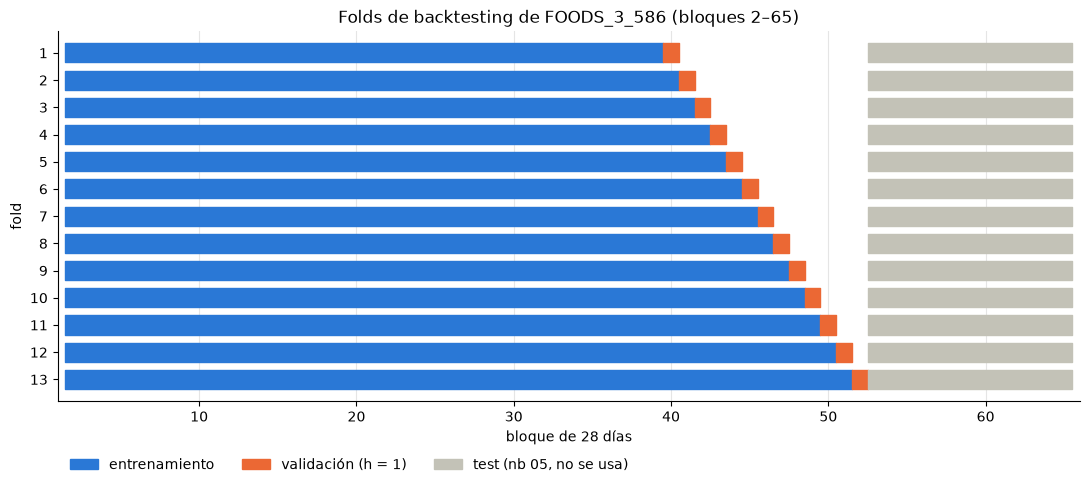

In [101]:
import matplotlib.pyplot as plt

TRAIN_COLOR, VALID_COLOR, TEST_COLOR = "#2a78d6", "#eb6834", "#c3c2b7"
ex = "FOODS_3_586"
d = boosting_data[boosting_data["item_id"] == ex]
first, last = d["block"].min(), d["block"].max()

fig, ax = plt.subplots(figsize=(11, 5))
for k in range(1, N_FOLDS + 1):
    train, valid = fold_masks(d, k)
    tr, va = d.loc[train, "block"], d.loc[valid, "block"]
    ax.broken_barh([(tr.min() - 0.5, tr.max() - tr.min() + 1)], (k - 0.35, 0.7), color=TRAIN_COLOR)
    ax.broken_barh([(va.min() - 0.5, 1)], (k - 0.35, 0.7), color=VALID_COLOR)
    test_blocks = d.loc[d["split"] == "test", "block"]
    ax.broken_barh([(test_blocks.min() - 0.5, len(test_blocks))], (k - 0.35, 0.7), color=TEST_COLOR)
ax.set(title=f"Folds de backtesting de {ex} (bloques {first}–{last})", xlabel="bloque de 28 días", ylabel="fold",
       yticks=range(1, N_FOLDS + 1), xlim=(first - 1, last + 1), ylim=(N_FOLDS + 0.8, 0.2))
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (TRAIN_COLOR, VALID_COLOR, TEST_COLOR)]
ax.legend(handles, ["entrenamiento", "validación (h = 1)", "test (nb 05, no se usa)"], loc="upper left", frameon=False, ncol=3, bbox_to_anchor=(0, -0.12))
plt.tight_layout()
plt.show()

## Etapa 13 (nb 04, Etapa 11) · Línea base: seasonal naive

**Objetivo:** pronosticar la ventana de backtesting con la línea base, medir su error en cada fold y calcular la escala del RMSSE de cada artículo.
**Entradas:** `features` (serie completa de unidades por artículo, incluido su primer bloque), `boosting_data` con `fold` (Etapa 10) y `snaive_m = 13` (`params.toml`, con historial).
**Salidas:** `snaive_valid` (pronóstico y error por artículo y fold), `rmsse_scale` (escala por artículo) y `snaive_item` (RMSSE de la línea base por artículo en los 13 folds).
**Decisión (usuario):**
- **En unidades:** ŷ_t = unidades del mismo artículo 13 bloques antes (el mismo periodo del año anterior). Calculamos el ratio, pero el pronóstico y el error se llevan a unidades, así que la línea base también se expresa en unidades. No se reentrena: en cada fold solo mira el bloque de hace 13.
- **Escala del RMSSE:** media de (y_t − y_{t−13})² con todo el train de cada artículo (todo lo anterior al test), como en M5. No cambia qué modelo gana dentro de un artículo (todos se dividen por la misma escala); solo pesa en el agregado. Con la ventana incluida, todos los artículos tienen al menos 26 bloques de train, así que al menos 13 pares para la escala.
- **Error por fold:** MAE, RMSE y WAPE sobre los 517 artículos (diagnóstico). **Por artículo:** RMSSE con sus 13 bloques de la ventana; es la referencia que cada candidato tendrá que mejorar en la Etapa 14.


In [102]:
from src.metrics import rmse, rmsse, seasonal_naive_scale, wape
from src.modeling import seasonal_naive

SNAIVE_M = cfg["forecast"]["snaive_m"]
assert SNAIVE_M == 13

In [103]:
features["snaive"] = seasonal_naive(features, SNAIVE_M)

In [104]:
# Pronóstico y error de la línea base en los bloques de la ventana (folds 1–13).
cell_of = targets.set_index("item_id")["cell"]
window = boosting_data.loc[boosting_data["fold"].between(1, N_FOLDS), ["item_id", "block", "fold", "units"]].astype({"item_id": str})
snaive_valid = window.merge(features[["item_id", "block", "snaive"]], on=["item_id", "block"], how="left", validate="one_to_one")
snaive_valid["error"] = snaive_valid["snaive"] - snaive_valid["units"]
snaive_valid["cell"] = snaive_valid["item_id"].map(cell_of)
assert len(snaive_valid) == N_MODEL * N_FOLDS and snaive_valid["snaive"].notna().all()

# Comprobación manual: el pronóstico es la unidad del bloque t − 13 del mismo artículo.
u = features.set_index(["item_id", "block"])["units"]
expected = u.reindex(pd.MultiIndex.from_arrays([snaive_valid["item_id"], snaive_valid["block"] - SNAIVE_M])).to_numpy()
assert np.allclose(snaive_valid["snaive"], expected)

# Escala por artículo con todo su train.
train_units = features[features["split"] == "train"].sort_values(["item_id", "block"]).groupby("item_id")["units"]
rmsse_scale = train_units.apply(lambda s: seasonal_naive_scale(s.to_numpy(), SNAIVE_M))
n_pairs = train_units.size() - SNAIVE_M
assert rmsse_scale.notna().all() and (rmsse_scale > 0).all() and n_pairs.min() >= 13
print(f"escala: {len(rmsse_scale)} artículos, pares por artículo {n_pairs.min()}–{n_pairs.max()}")

per_fold = snaive_valid.groupby("fold").apply(lambda d: pd.Series({
    "MAE (unidades)": d["error"].abs().mean(), "RMSE (unidades)": rmse(d["units"], d["snaive"]), "WAPE": wape(d["units"], d["snaive"]),
}), include_groups=False)
display(per_fold.style.format({"MAE (unidades)": "{:,.1f}", "RMSE (unidades)": "{:,.1f}", "WAPE": "{:.1%}"}))

escala: 517 artículos, pares por artículo 13–39


,MAE (unidades),RMSE (unidades),WAPE
fold,,,
1,246.2,554.1,21.8%
2,268.5,589.5,23.8%
3,264.9,571.1,24.2%
4,318.3,"1,484.8",29.4%
5,269.1,725.3,26.0%
6,237.0,516.7,24.0%
7,252.4,747.2,26.2%
8,287.2,863.4,30.0%
9,242.3,677.1,25.2%


In [105]:
snaive_item = snaive_valid.groupby("item_id").apply(lambda d: pd.Series({
    "rmsse": rmsse(d["units"], d["snaive"], rmsse_scale[d.name]), "wape": wape(d["units"], d["snaive"]),
}), include_groups=False)
snaive_item["cell"] = snaive_item.index.map(cell_of)
assert snaive_item["rmsse"].notna().all() and len(snaive_item) == N_MODEL
display(snaive_item.groupby("cell")["rmsse"].describe(percentiles=[0.25, 0.5, 0.75]).round(3))
# Ejemplo con error absoluto y porcentual por bloque (diagnóstico: la constitución no usa MAPE como métrica).
ex = snaive_valid[snaive_valid["item_id"] == "FOODS_3_586"][["fold", "block", "units", "snaive", "error"]].copy()
ex["abs_error"] = ex["error"].abs()
ex["pct_error"] = ex["abs_error"] / ex["units"] * 100
display(ex.set_index("fold").style.format({"units": "{:,.0f}", "snaive": "{:,.0f}", "error": "{:+,.0f}", "abs_error": "{:,.0f}", "pct_error": "{:.1f} %"}))
print(f"FOODS_3_586 · error absoluto medio: {ex['abs_error'].mean():,.0f} unidades · error porcentual medio: {ex['pct_error'].mean():.1f} %"
      f" · WAPE (Σ|e| / Σy): {wape(ex['units'], ex['snaive']):.1%} · RMSSE: {snaive_item.loc['FOODS_3_586', 'rmsse']:.2f}")

,count,mean,std,min,25%,50%,75%,max
cell,,,,,,,,
AX,191.0,0.887,0.255,0.330,0.695,0.906,1.075,1.455
AY,229.0,0.848,0.293,0.258,0.598,0.837,1.066,1.570
AZ,97.0,0.929,0.364,0.114,0.616,0.979,1.216,1.567


,block,units,snaive,error,abs_error,pct_error
fold,,,,,,
1,40,"12,393","13,696","+1,303","1,303",10.5 %
2,41,"14,681","14,188",-493,493,3.4 %
3,42,"16,755","15,093","-1,662","1,662",9.9 %
4,43,"14,880","14,532",-348,348,2.3 %
5,44,"13,066","12,240",-826,826,6.3 %
6,45,"12,371","12,065",-306,306,2.5 %
7,46,"12,619","12,945",+326,326,2.6 %
8,47,"12,879","12,380",-499,499,3.9 %
9,48,"9,942","9,873",-69,69,0.7 %


FOODS_3_586 · error absoluto medio: 541 unidades · error porcentual medio: 4.1 % · WAPE (Σ|e| / Σy): 4.3% · RMSSE: 0.52


### 13.1 · Series por segmento: real vs seasonal naive

**Qué muestra:** para cada artículo, arriba el ratio y abajo las unidades, real contra seasonal naive, cada uno en su escala:
- **Ratio (tratado, 6a):** el seasonal naive toma el ratio de hace 13 bloques: el mismo cambio que hubo hace un año. Los ratios > 2 están vacíos (hueco en la línea) y una línea punteada vertical marca el bloque.
- **Unidades:** el seasonal naive toma las unidades de hace 13 bloques (la línea base de esta etapa, con la que se mide el error). Las unidades son las reales: el tratamiento del ratio no las cambia.

**Leyenda:** una sola, arriba (real, seasonal naive y bloque tratado). **Error:** el del seasonal naive en la ventana de backtesting, siempre en porcentaje (WAPE = Σ|error| ÷ Σ real), en el título de cada panel. El seasonal naive empieza un año después del inicio de cada artículo.
**Decisión:** 5 artículos al azar de cada segmento (AX, AY y AZ), elegidos con la semilla de `params.toml` (`features.seed`) para que sean siempre los mismos. Solo se grafica el train (hasta el último bloque de la ventana de backtesting, sombreada): el test no se mira hasta el nb 05.


In [106]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

REAL_COLOR, SNAIVE_COLOR, WINDOW_COLOR, TREATED_COLOR = "#2a78d6", "#eb6834", "#f1f0ec", "#6b6b6b"

def plot_item(item):
    # Ratio (arriba) y unidades (abajo) del train de un artículo: real vs seasonal naive.
    d = features[(features["item_id"] == item) & (features["split"] == "train")].sort_values("block")
    snaive_ratio = d["ratio"].shift(SNAIVE_M)   # seasonal naive sobre el ratio: el ratio de hace 13 bloques
    snaive_ratio_plot = d["ratio_plot"].shift(SNAIVE_M)   # solo para dibujar, sin cortes (6a.1)
    treated = d[d["ratio_treated"]]
    in_win = d["backtest"]
    win = d.loc[in_win, "block"]
    ok = in_win & d["ratio"].notna() & snaive_ratio.notna()
    wape_ratio = wape(d.loc[ok, "ratio"], snaive_ratio[ok])
    wape_units = wape(d.loc[in_win, "units"], d.loc[in_win, "snaive"])
    fig, (ax_r, ax_u) = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True)
    for ax in (ax_r, ax_u):
        ax.axvspan(win.min() - 0.5, win.max() + 0.5, color=WINDOW_COLOR, zorder=0)
        for b in d.loc[d["ratio_treated"], "block"]:
            ax.axvline(b, color=TREATED_COLOR, linewidth=0.8, linestyle=":", zorder=1)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
        ax.set_axisbelow(True)
    ax_r.plot(d["block"], d["ratio_plot"], color=REAL_COLOR, linewidth=2)
    ax_r.plot(d["block"], snaive_ratio_plot, color=SNAIVE_COLOR, linewidth=2)
    ax_r.scatter(treated["block"], treated["ratio_plot"], s=28, facecolors="white", edgecolors=REAL_COLOR, linewidths=1.5, zorder=3)
    ax_r.axhline(1, color="#9a9a9a", linewidth=0.8, linestyle="--")
    ax_r.set(ylabel="ratio")
    ax_r.set_title(f"Ratio · WAPE del seasonal naive en la ventana: {wape_ratio:.1%}", loc="left", fontsize=10)
    ax_u.plot(d["block"], d["units"], color=REAL_COLOR, linewidth=2)
    ax_u.plot(d["block"], d["snaive"], color=SNAIVE_COLOR, linewidth=2)
    ax_u.set(ylabel="unidades", xlabel="bloque de 28 días")
    ax_u.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax_u.set_title(f"Unidades · WAPE del seasonal naive en la ventana: {wape_units:.1%}", loc="left", fontsize=10)
    ax_r.text(win.mean(), 0.98, "ventana de backtesting", transform=ax_r.get_xaxis_transform(), ha="center", va="top", fontsize=9, color="#6b6b6b")
    handles = [Line2D([], [], color=REAL_COLOR, linewidth=2, label="real"),
               Line2D([], [], color=SNAIVE_COLOR, linewidth=2, label="seasonal naive"),
               Line2D([], [], color=REAL_COLOR, marker="o", markerfacecolor="white", linestyle="none", label="ratio tratado: interpolado solo en el gráfico")]
    fig.suptitle(f"{item} ({cell_of[item]})", x=0.01, ha="left", fontsize=12)
    fig.legend(handles=handles, loc="upper right", ncol=3, frameon=False, fontsize=9, bbox_to_anchor=(0.99, 1.0))
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

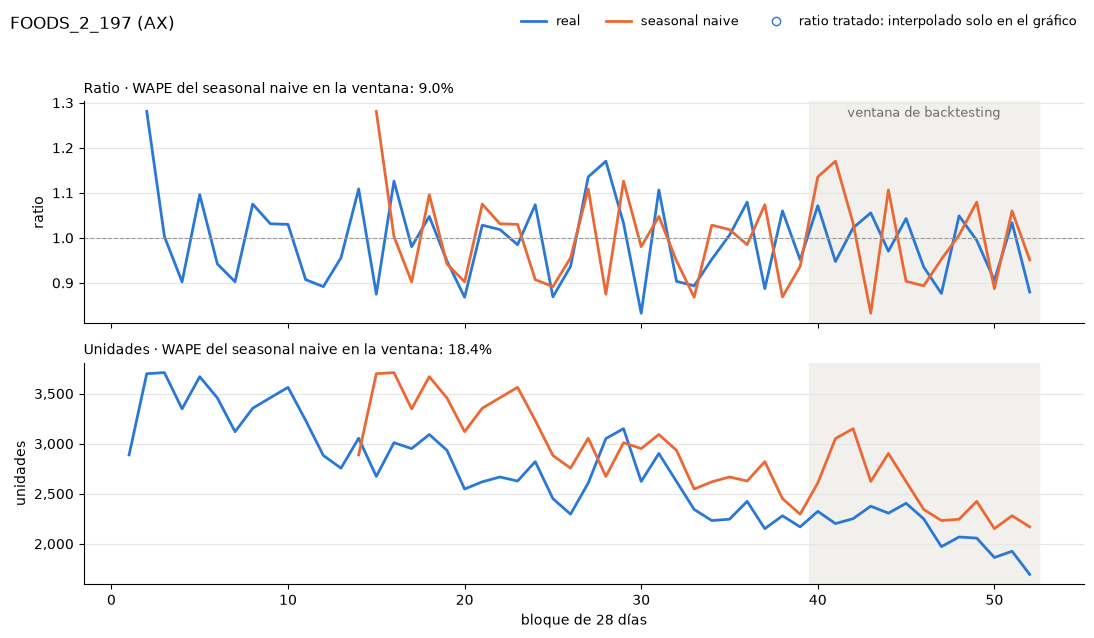

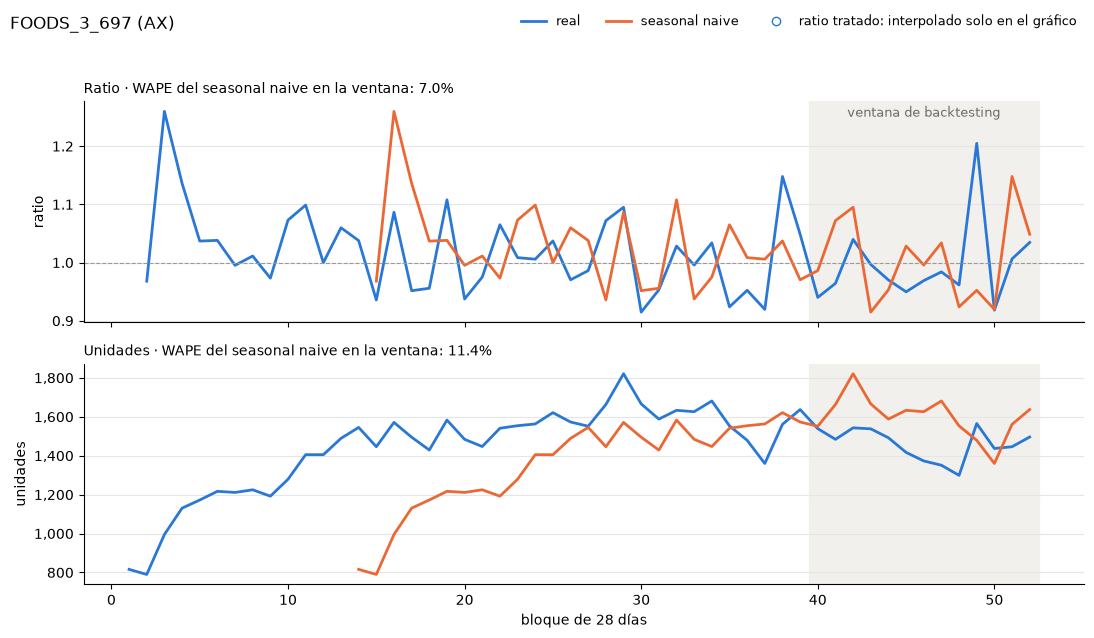

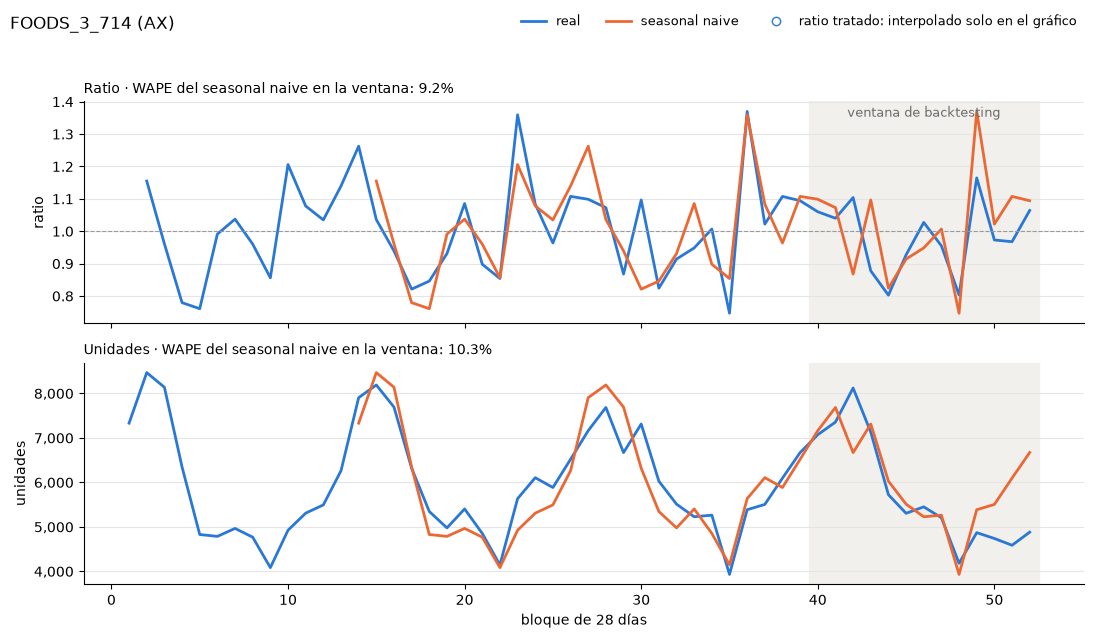

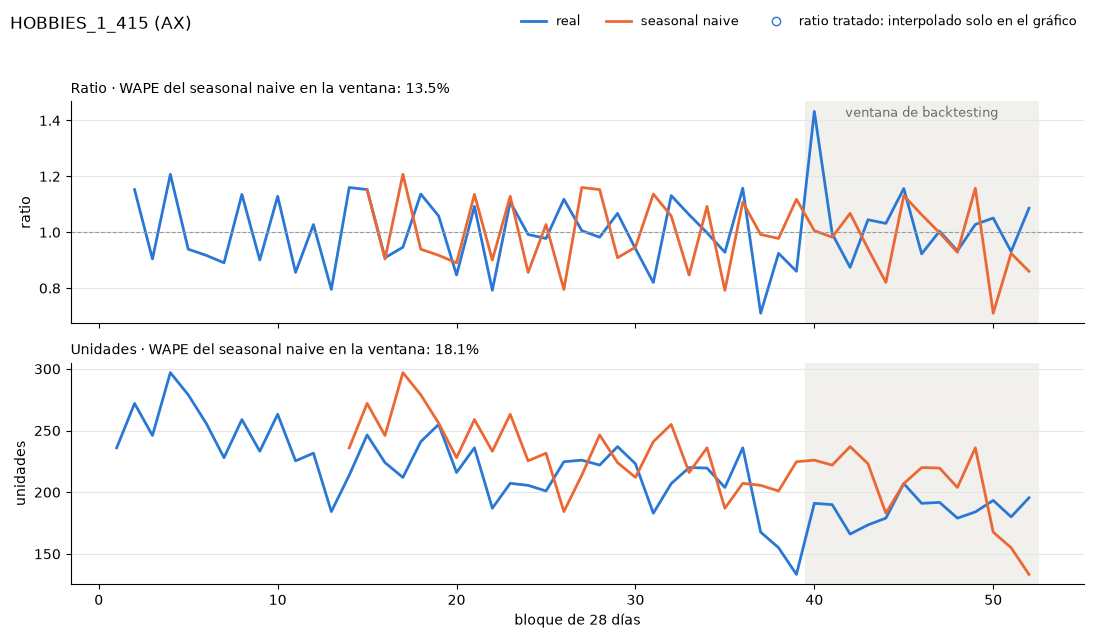

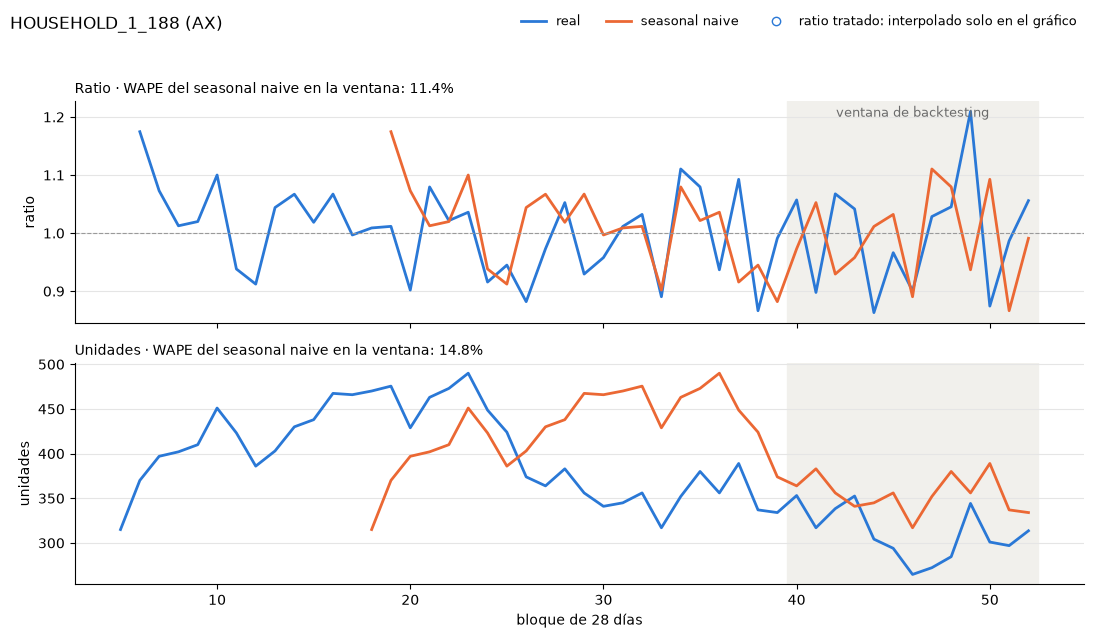

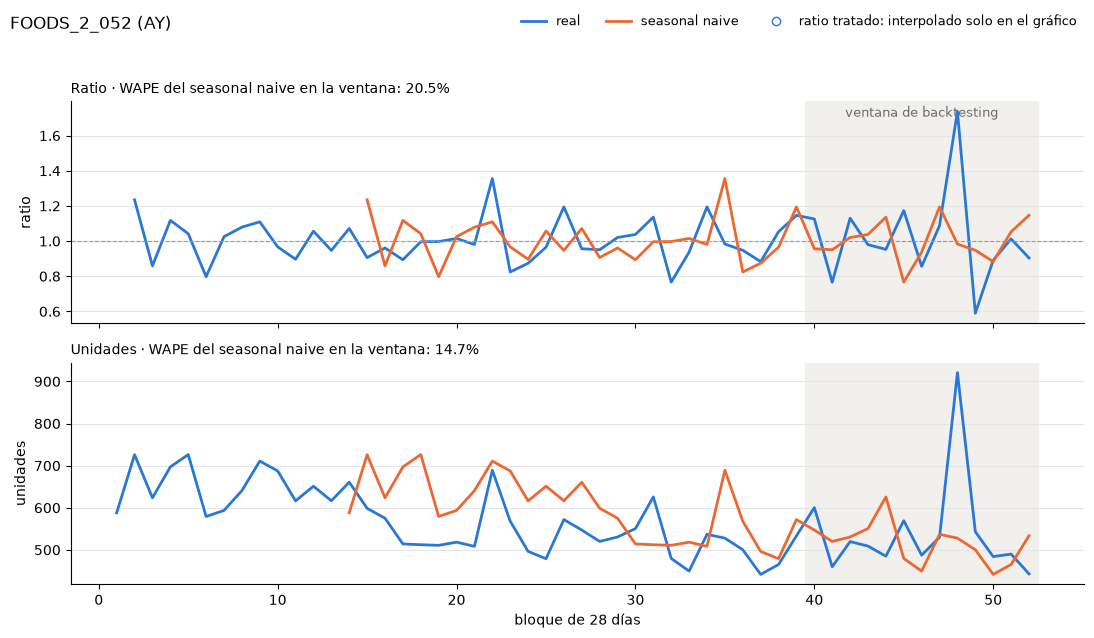

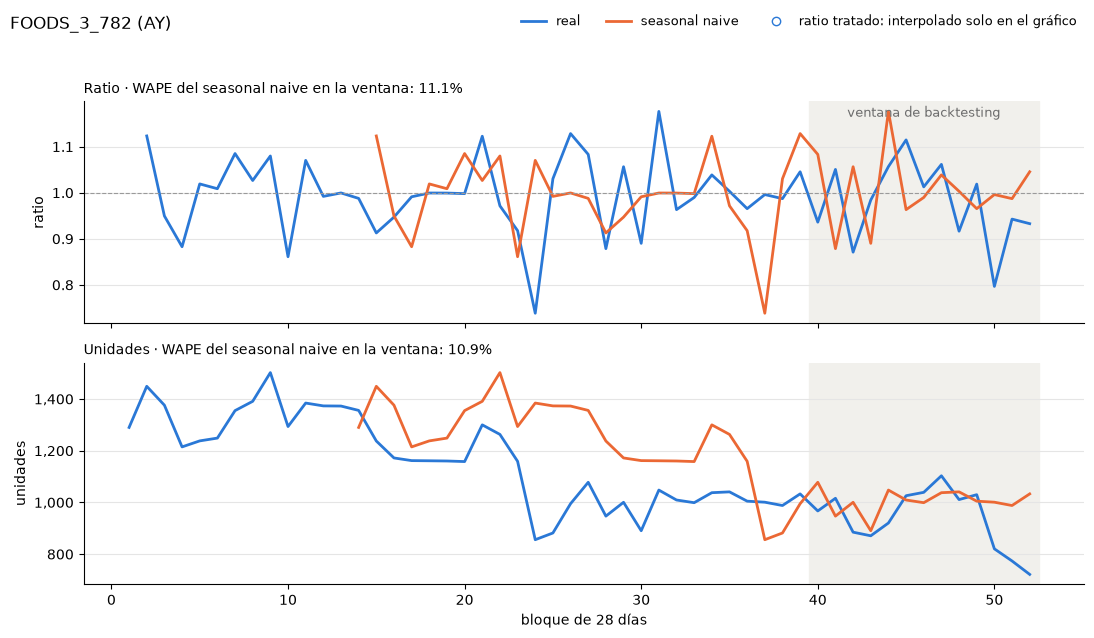

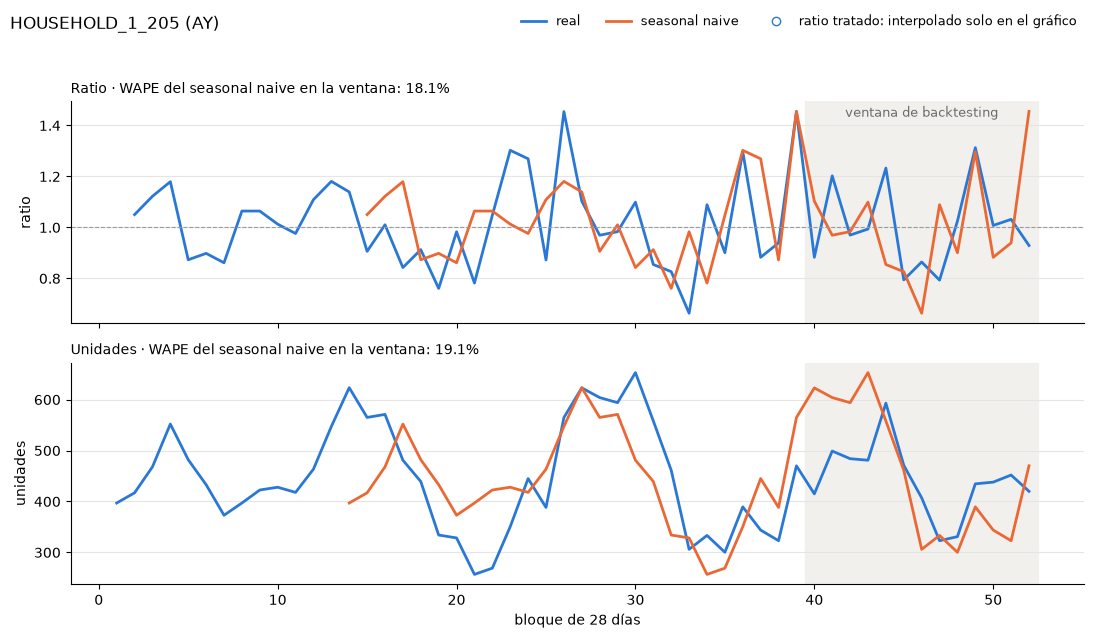

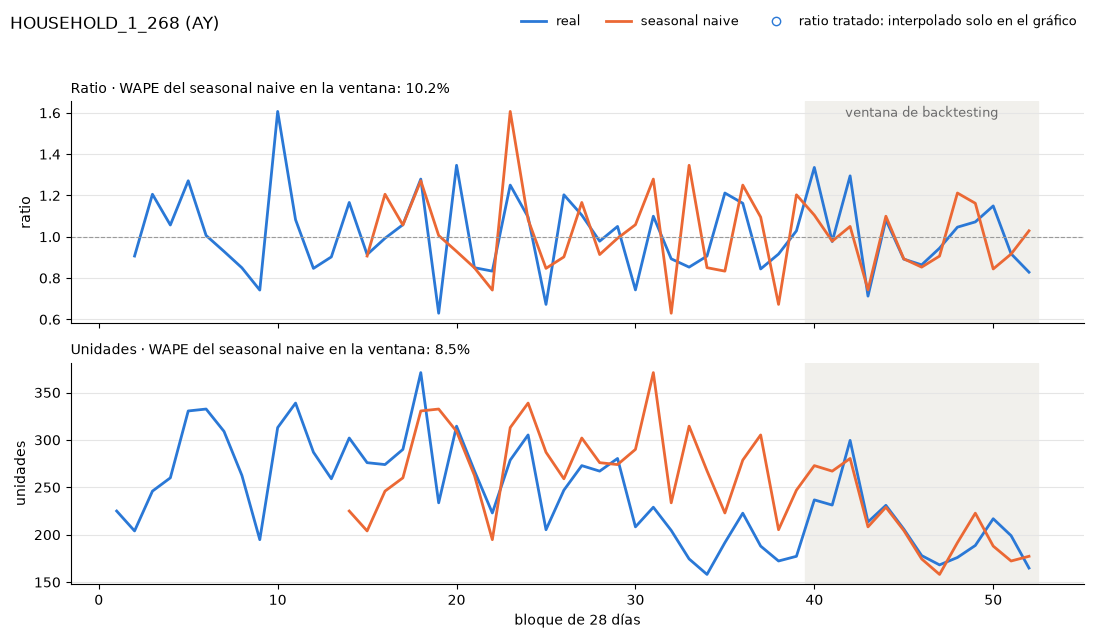

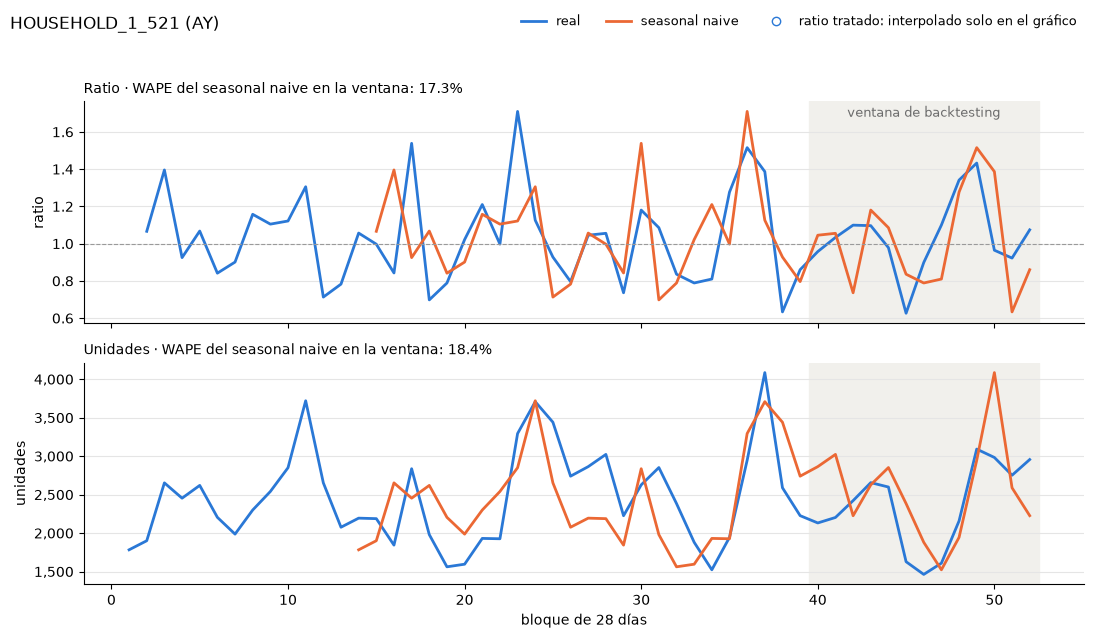

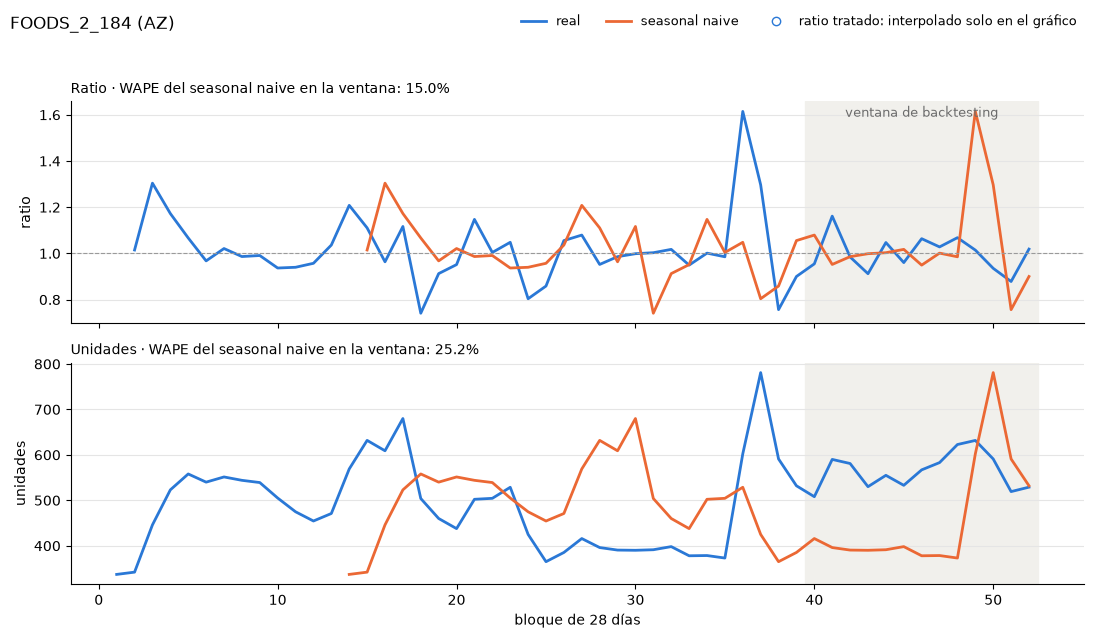

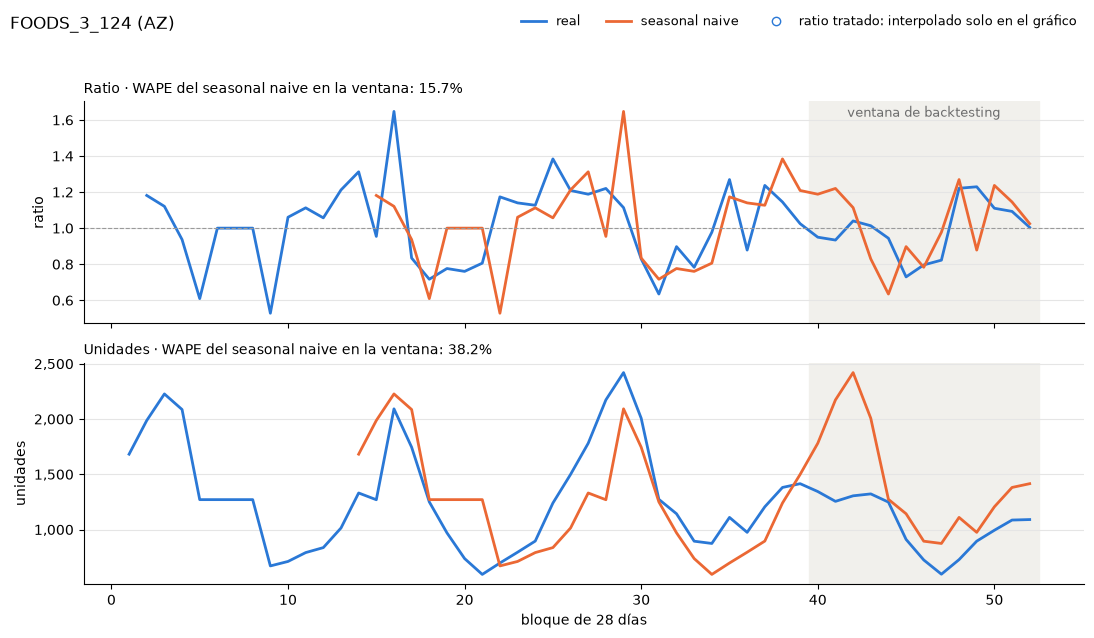

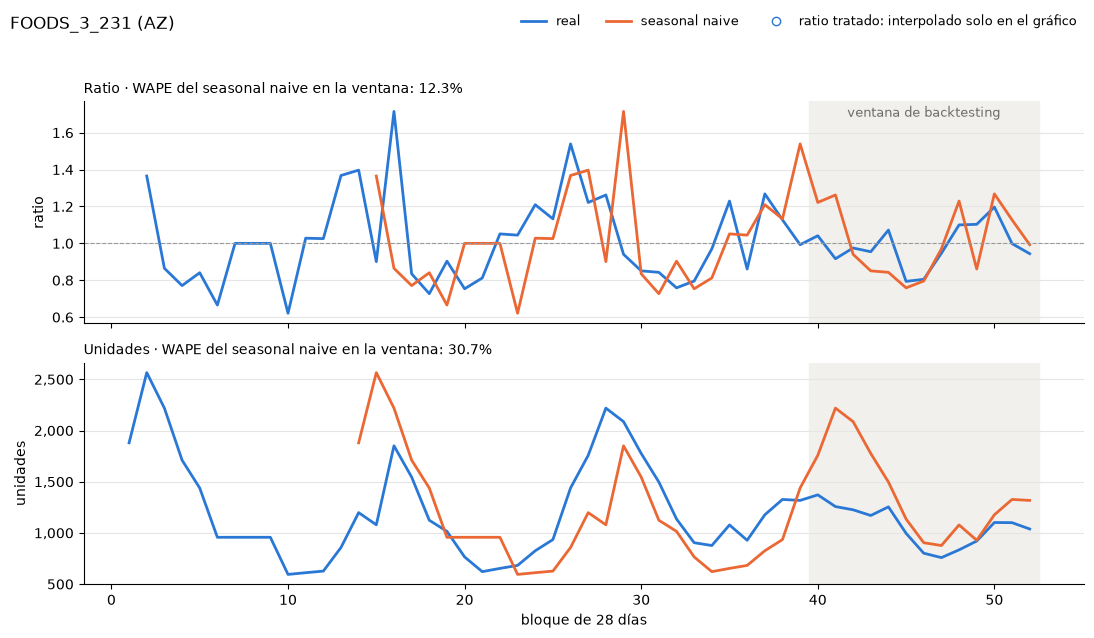

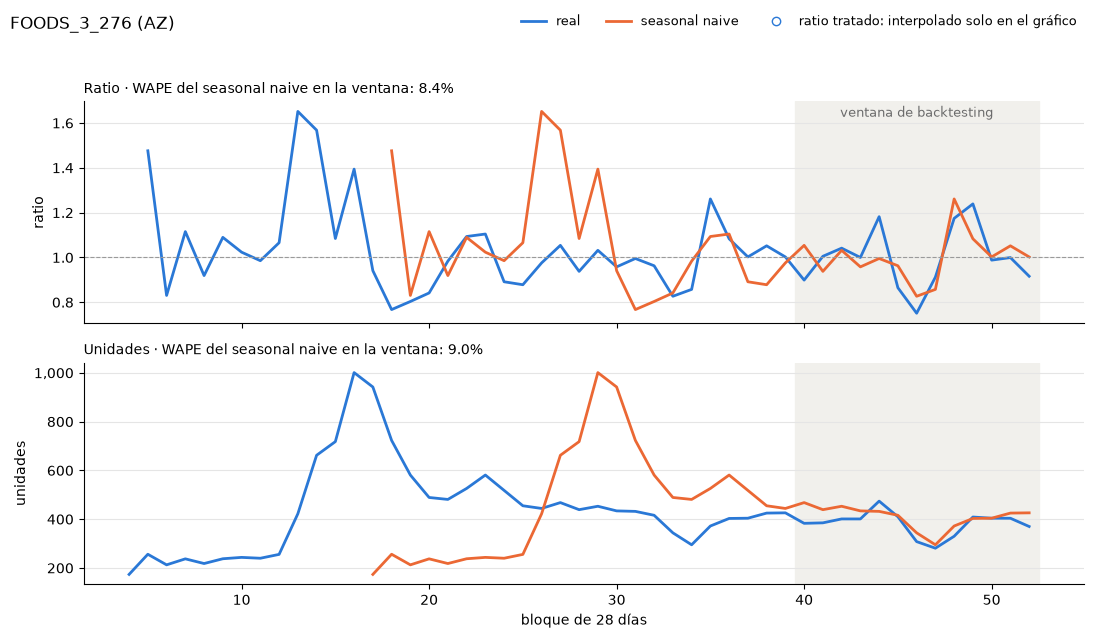

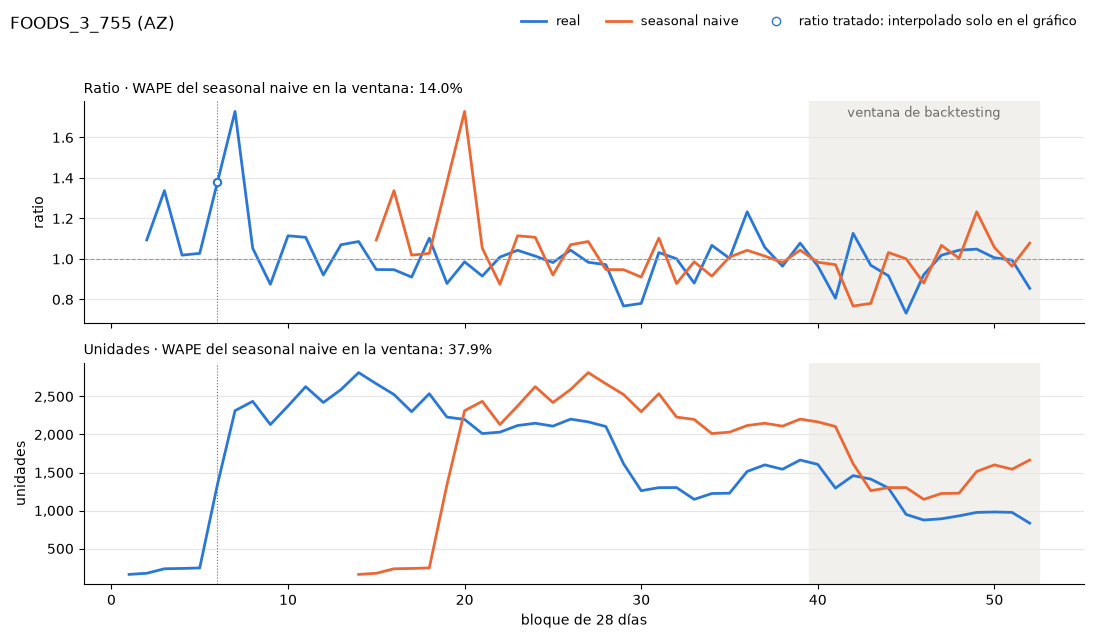

In [107]:
rng = np.random.default_rng(SEED)
modeled = np.sort(features["item_id"].unique())
for cell in ["AX", "AY", "AZ"]:
    pool = [i for i in modeled if cell_of[i] == cell]
    for item in sorted(rng.choice(pool, size=5, replace=False)):
        plot_item(item)

### 13.2 · Series con ratios tratados

**Qué muestra:** el mismo gráfico para 10 artículos elegidos al azar (con la semilla) entre los que tienen algún ratio tratado en el train (6a: ratio > 2, vacío).
**Para qué:** comprobar que los picos del ratio ya no aparecen y ver qué había en esos bloques: casi siempre un bloque anterior con días enmascarados o completado (la tabla de causas de la 6a).


ratios tratados en el train: 95 en 76 artículos


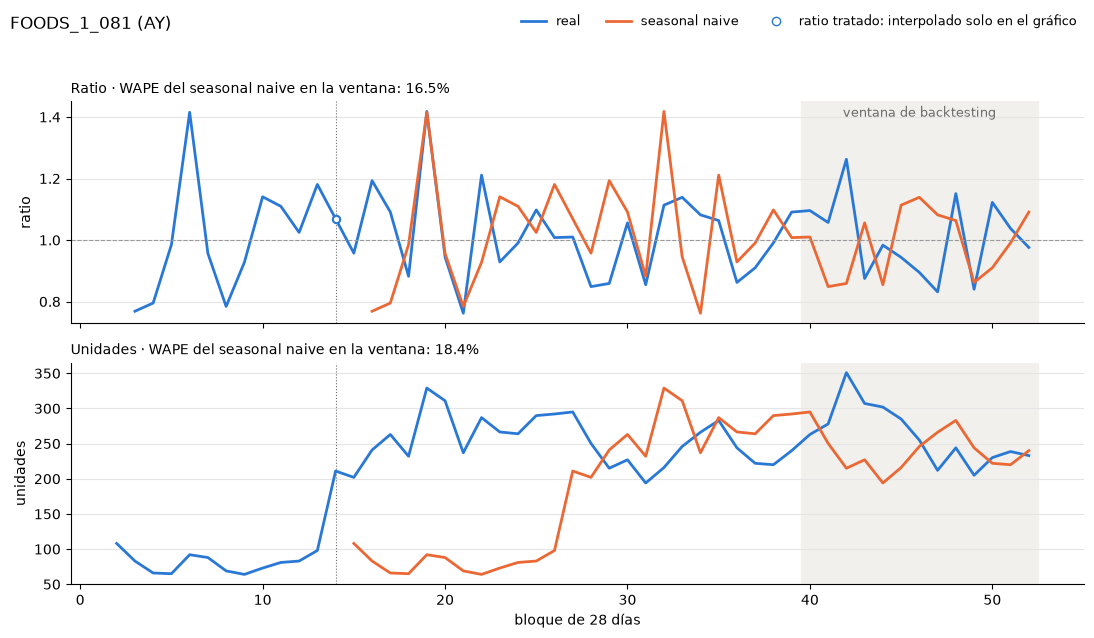

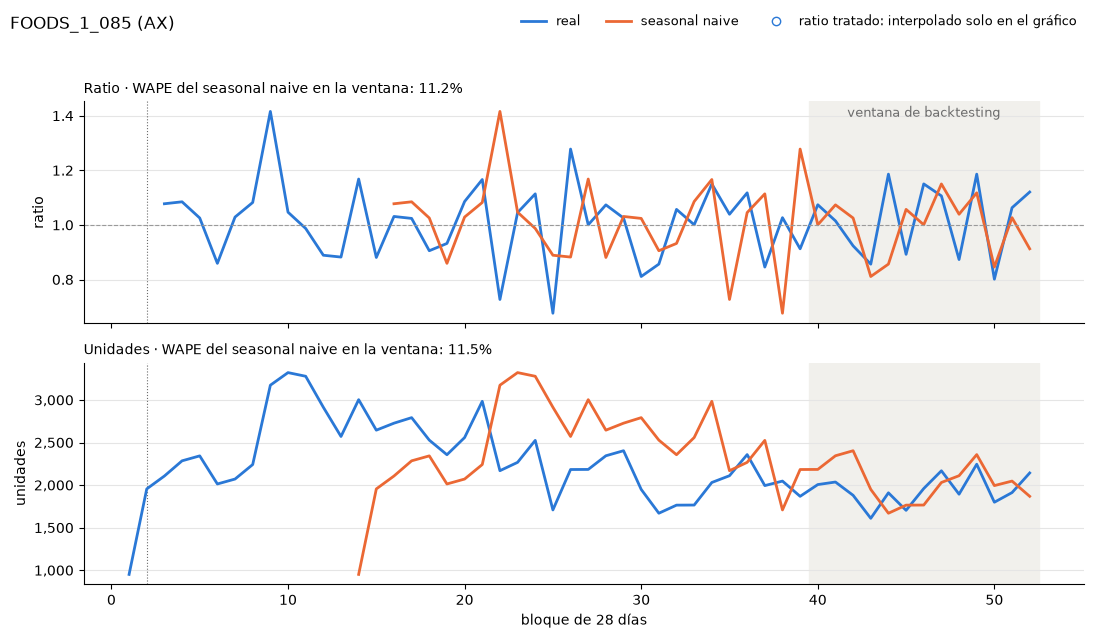

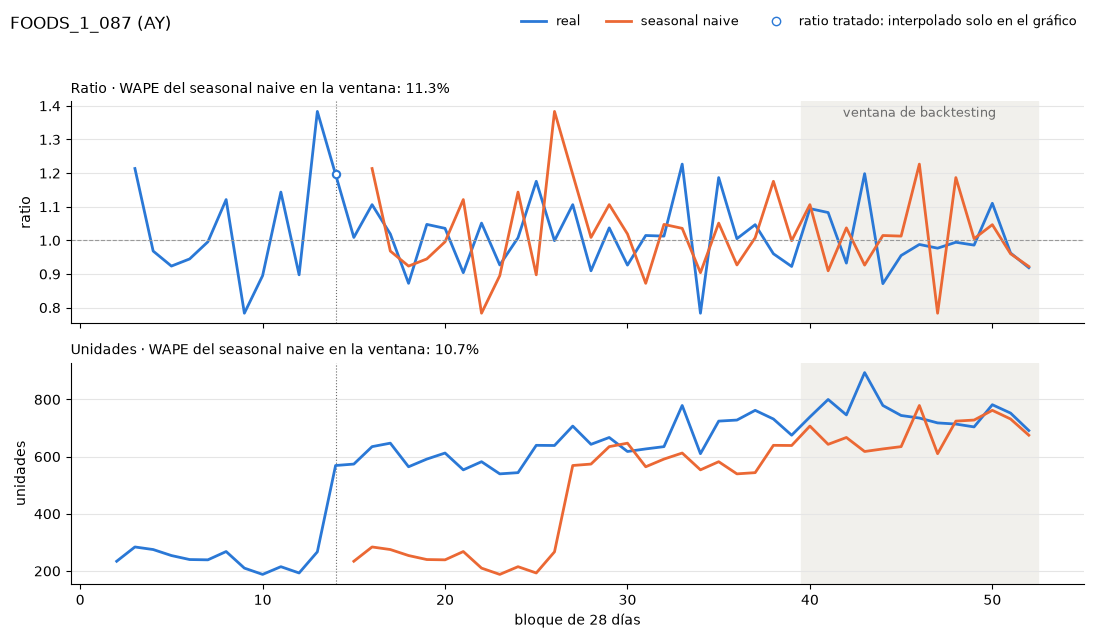

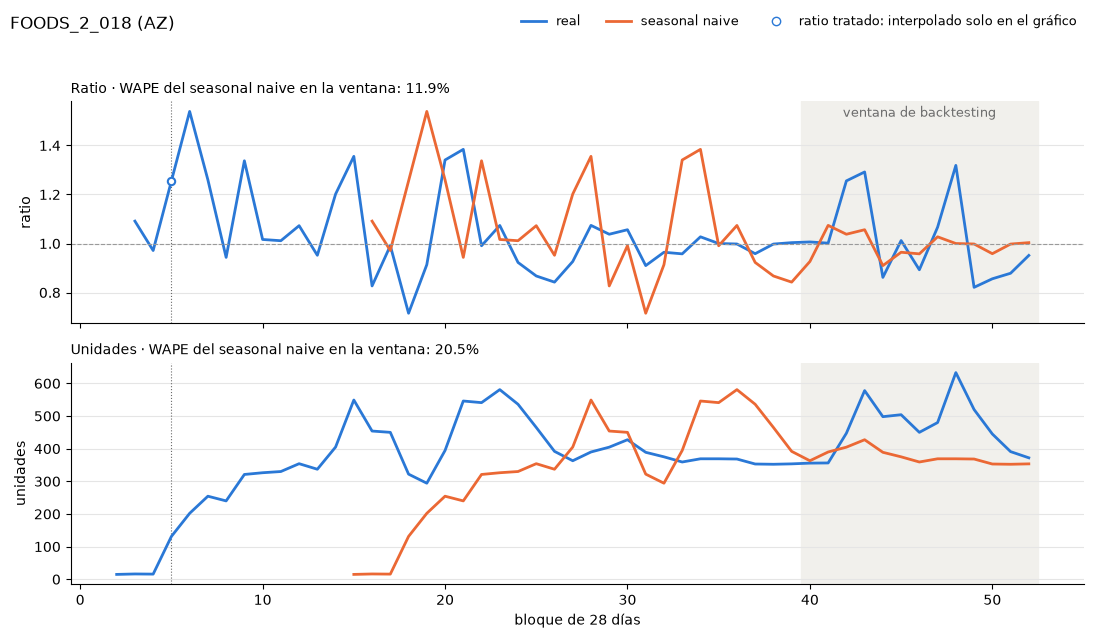

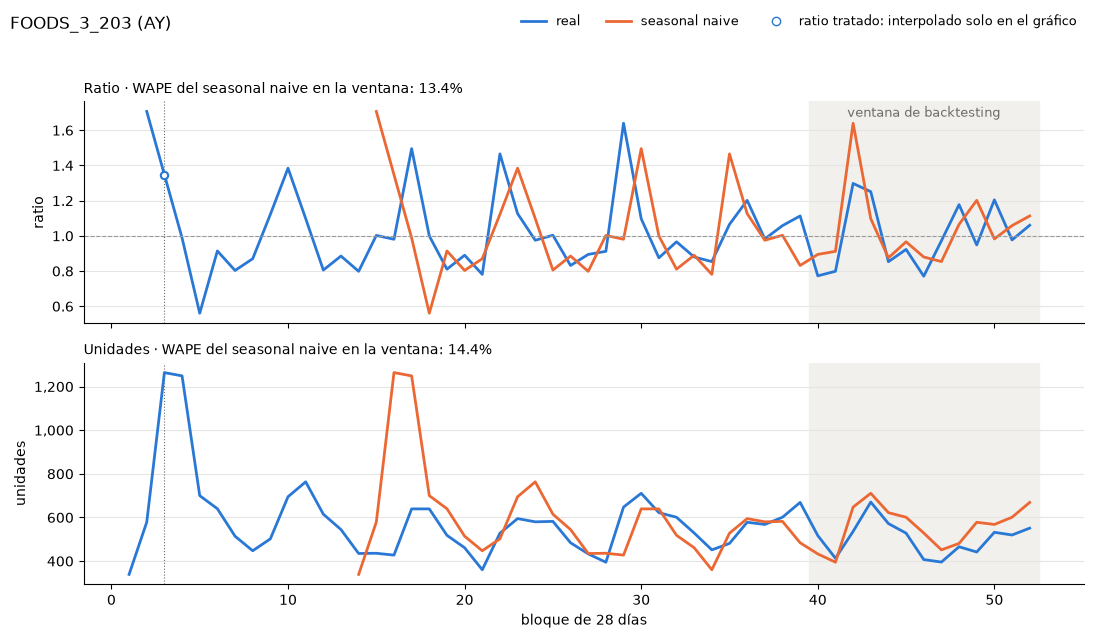

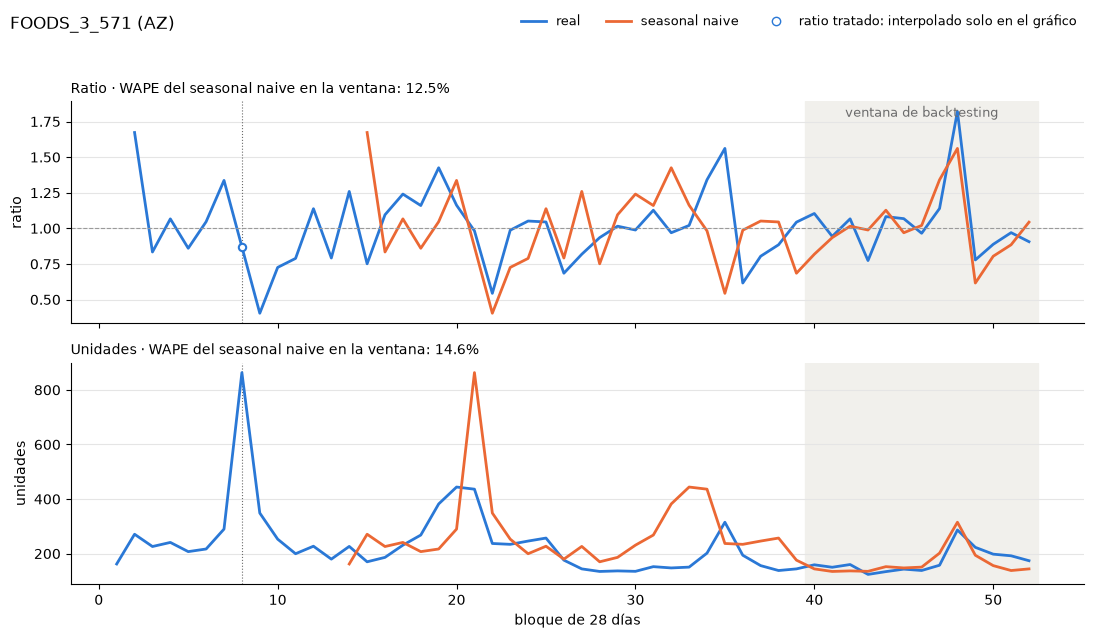

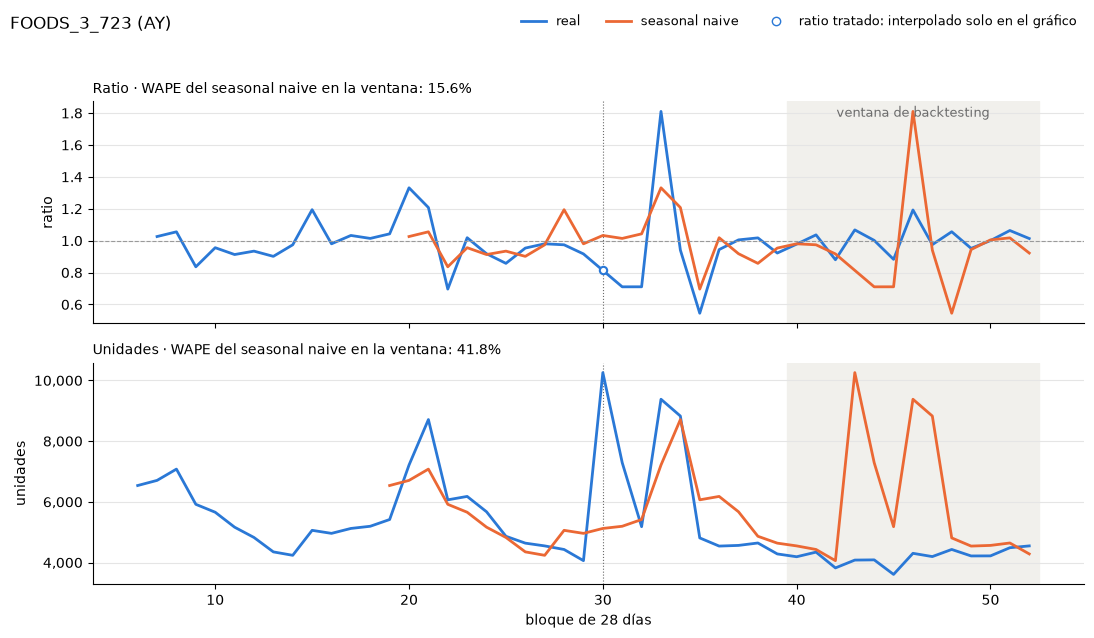

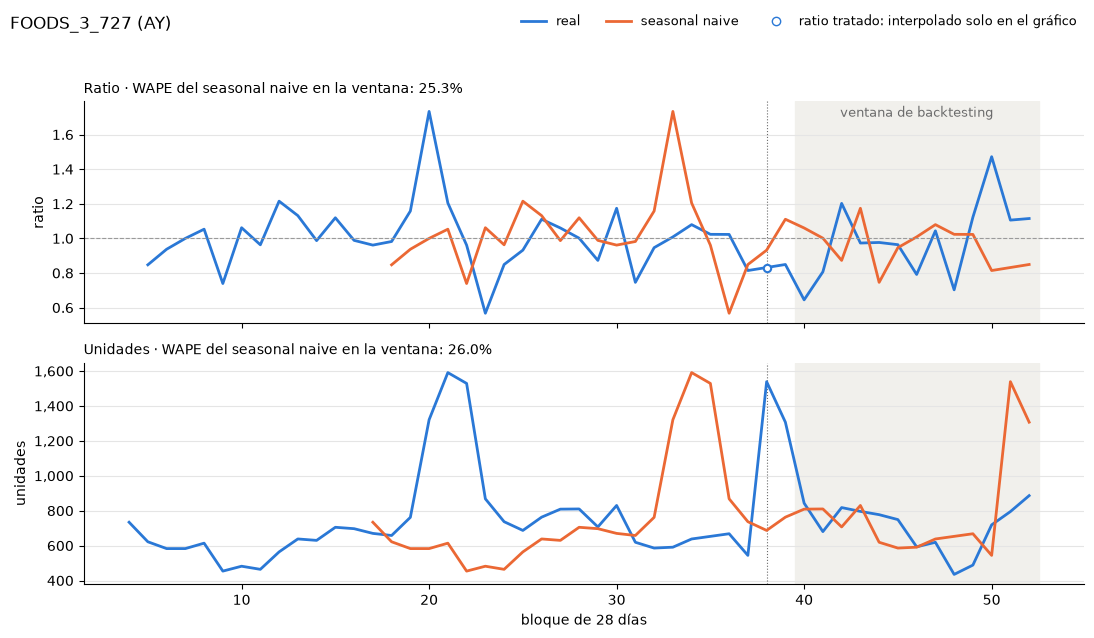

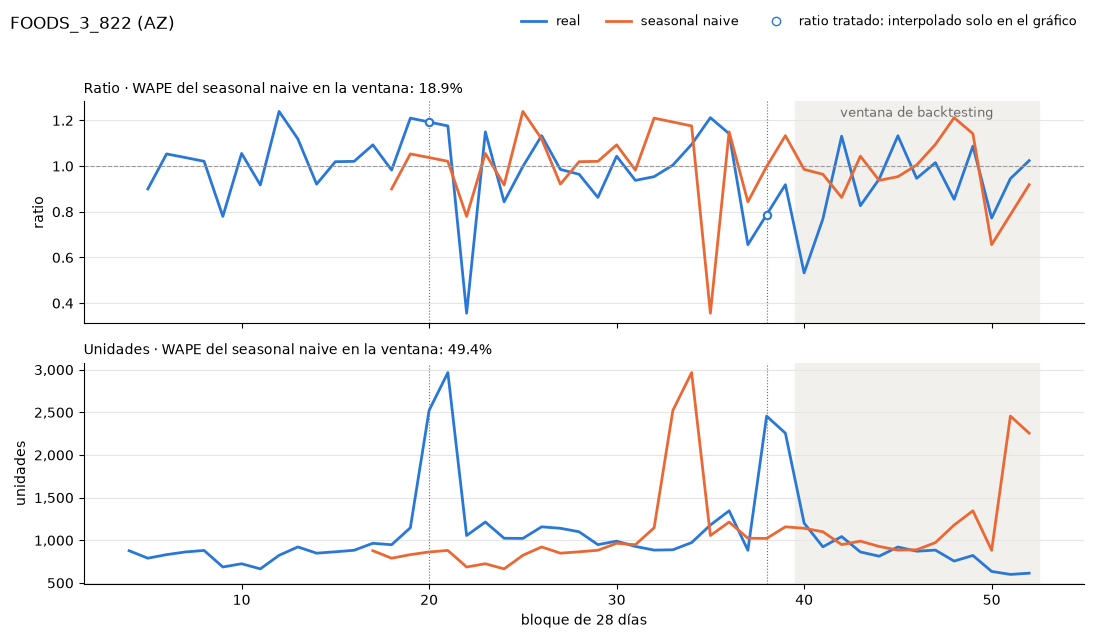

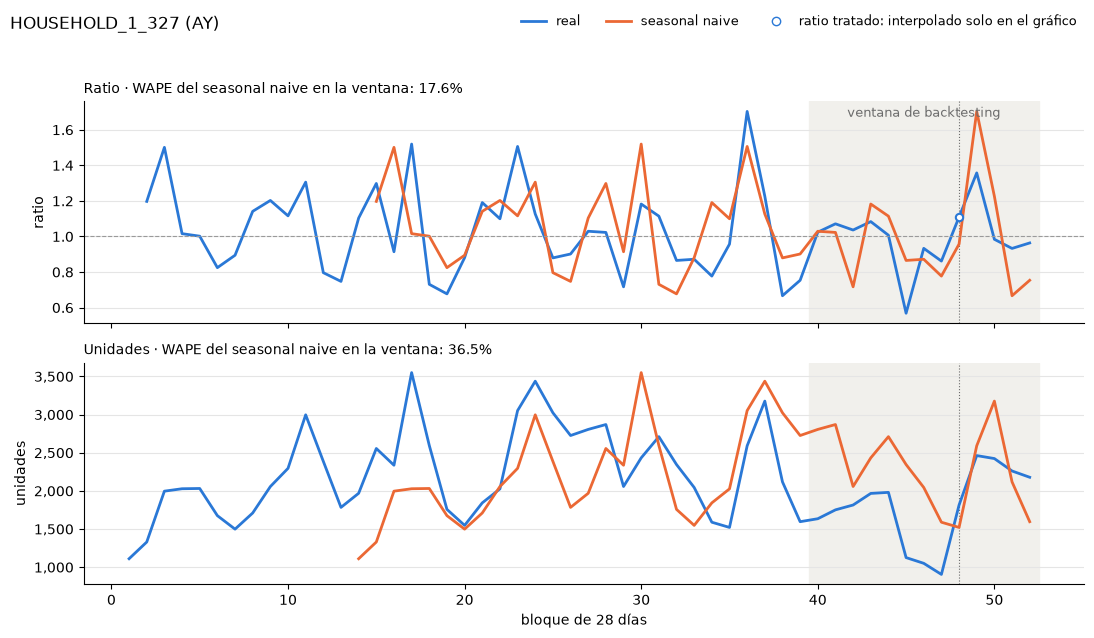

In [108]:
train_rows = features[features["split"] == "train"]
treated_items = np.sort(train_rows.loc[train_rows["ratio_treated"], "item_id"].unique())
print(f"ratios tratados en el train: {int(train_rows['ratio_treated'].sum())} en {len(treated_items)} artículos")
rng = np.random.default_rng(SEED)
for item in sorted(rng.choice(treated_items, size=min(10, len(treated_items)), replace=False)):
    plot_item(item)

In [109]:
raise Exception("Detener")

Exception: Detener

### 13.3 · Exportación para los nb 03c y 03d (D1)

**Qué hace:** guarda en `data/interim/nb03b_datasets/` los dos datasets con sus folds, el pronóstico del seasonal naive en la ventana y la escala del RMSSE por artículo, más un `manifest.json` con las listas de variables y los parámetros.
**Para qué:** el 03c (búsqueda del boosting) y el 03d (selección por artículo) arrancan desde aquí sin repetir el tratamiento por tienda. El 03c puede correr mientras este notebook hace la búsqueda SARIMAX (Etapa 14).
**Decisión (usuario, 2026-11-06):**
- Segunda excepción a D1: son las entradas de los notebooks experimentales; el nb 04 no las carga.
- **Parquet**, el formato de los intermedios del proyecto: conserva el Int64 de `fold` (nulo en test) y los str. Las category (`item_id`, `cell` y `period`, ordenada) se anotan en el manifiesto y se restauran al cargar, porque Parquet devuelve como int64 una category de enteros.
- `snaive_valid` y `rmsse_scale` van porque el seasonal naive necesita el primer bloque de cada artículo, que los datasets no tienen (sin ratio), y el 03c mide su error con la misma escala.

In [110]:
from src.data import load_tables, save_tables

DATASETS_DIR = Path("data/interim/nb03b_datasets")   # entradas de los nb 03c y 03d (D1); data/ está fuera de git

In [111]:
dataset_paths = save_tables(DATASETS_DIR, {
    "sarimax_data": sarimax_data, "boosting_data": boosting_data, "snaive_valid": snaive_valid,
    "rmsse_scale": rmsse_scale.rename("scale").rename_axis("item_id").reset_index(),
}, manifest={"boost_features": BOOST_FEATURES, "cat_features": CAT_FEATURES, "sarimax_exog": SARIMAX_EXOG,
             "n_items": N_MODEL, "n_folds": N_FOLDS, "snaive_m": SNAIVE_M, "seed": SEED}, overwrite=OVERWRITE)

In [112]:
# Lo que se lee de disco es idéntico a lo que hay en memoria (tipos incluidos).
back, manifest = load_tables(DATASETS_DIR)
for name, df in [("sarimax_data", sarimax_data), ("boosting_data", boosting_data), ("snaive_valid", snaive_valid)]:
    pd.testing.assert_frame_equal(back[name], df.reset_index(drop=True))
assert np.allclose(back["rmsse_scale"].set_index("item_id")["scale"].reindex(rmsse_scale.index), rmsse_scale)
assert manifest["boost_features"] == BOOST_FEATURES and manifest["n_folds"] == N_FOLDS and manifest["n_items"] == N_MODEL
display(pd.DataFrame({"filas": {k: v[0] for k, v in manifest["tables"].items()},
                      "columnas": {k: v[1] for k, v in manifest["tables"].items()},
                      "MB": {p.stem: round(p.stat().st_size / 1e6, 2) for p in dataset_paths if p.suffix == ".parquet"}}))

,filas,columnas,MB
sarimax_data,31164,16,0.91
boosting_data,31164,44,4.65
snaive_valid,6721,7,0.12
rmsse_scale,517,2,0.01


## Etapa 14 (nb 04, Etapa 12) · SARIMAX: órdenes por artículo y backtesting

**Objetivo:** elegir por artículo el periodo estacional s, las diferencias (d, D) y los órdenes (p, q)(P, Q) de un SARIMAX del ratio, solo con los bloques anteriores a la ventana de backtesting, y hacer su backtesting de 13 folds (14.3).
**Entradas:** `sarimax_data` con `fold` (Etapas 11–12): ratio (vacío en las filas tratadas), `units`, `units_prev` y los 4 conteos de eventos del bloque.
**Salidas:** `acf_table` (14.1) y `sarimax_search`, `sarimax_valid` y `sarimax_item` (14.3).
**Decisión (usuario, 2026-11-05):**
- **Sin pmdarima:** búsqueda propia con statsmodels, que la constitución permite. pmdarima no admite NaN en la serie y suele atrasarse con versiones nuevas de numpy y pandas; el filtro de Kalman de statsmodels trata los ratios vacíos como faltantes.
- **Muestras dentro del fold 0** (antes de la ventana): *selección* = todos los bloques menos los últimos 6; *contraste* = esos 6 (medio año; en la mayoría de los artículos quedan 32 bloques para ajustar). La ventana y el test no se tocan.
- **Periodo estacional s dentro de la búsqueda:** sin parte estacional, 3 (≈ trimestre, 3,25 bloques), 6 y 7 (≈ semestre, 6,5 bloques: los dos redondeos) y 13 (año). Nada más largo: antes de la ventana hay como máximo 38 bloques y con 26 no habría dos ciclos. La estacionalidad semanal desaparece al sumar 28 días. Un s compite solo si la muestra de selección tiene al menos 2·s + 1 bloques (dos ciclos y uno más para la diferencia).
- **Diferencias, en el orden de pmdarima:** para cada s, D por la prueba OCSB (valor crítico al 5 % de `forecast` y pmdarima; rezagos 0–3 por AIC); luego d por KPSS (α = 0,05; H0: estacionaria) sobre la serie ya diferenciada. Como máximo 1 de cada una: el ratio ya es un cambio relativo (log r ≈ Δ log unidades), así que más diferencias serían sobrediferenciar.
- **Órdenes:** p, q ∈ {0, 1, 2}; (P, Q) ∈ {(1, 0), (0, 1), (1, 1)}, más (0, 0) cuando D = 1 (solo la diferencia estacional). Son 9 modelos sin parte estacional y 27 o 36 por cada s: **búsqueda completa**, no paso a paso, para no quedar en un óptimo local. Constante solo si d + D = 0. Exógenas: los 4 conteos de eventos del bloque; se deja fuera la que no varía en la muestra.
- **Dentro de cada s gana el menor AICc** (decisión del usuario; la constitución dice AIC y el AICc es su corrección para muestras chicas): con unos 32 bloques y hasta 11 parámetros, el AIC simple favorece modelos grandes. Solo se comparan modelos con la misma diferenciación, que es la de cada s.
- **Entre periodos s gana el menor RMSE en unidades** del pronóstico a un paso en los 6 bloques de contraste, reestimando en cada bloque (unidades = unidades del bloque anterior × ratio pronosticado). Este error sí es comparable entre diferenciaciones distintas.
- **Fallos:** cada combinación queda registrada con su estado (`ok`, `no_converge`, `muestra_insuficiente` o `error`) y solo `ok` compite. En el contraste, si un reajuste no converge se usan los últimos coeficientes que sí convergieron (sin mirar el bloque que se predice) y se cuenta como *respaldo*. Un artículo sin ningún modelo válido queda `sin_modelo` y SARIMAX no compite en él.
- **Optimizador:** L-BFGS de statsmodels con hasta 200 iteraciones; con 50 (el valor por defecto) la mayoría de los modelos con p o q = 2 no converge.
- El espacio de búsqueda va como constantes de este notebook y no en `params.toml`: la sección `[forecast]` quedó declarada antes de la réplica del año 5 y el 03b no persiste resultados (D1).

In [113]:
import time

from src.modeling import load_sarimax_checkpoints, search_sarimax_checkpointed, seasonal_acf

SARIMAX_S = [3, 6, 7, 13]                       # periodos estacionales candidatos (además de "sin parte estacional")
SARIMAX_P = SARIMAX_Q = [0, 1, 2]
SARIMAX_SEASONAL_PQ = [(1, 0), (0, 1), (1, 1)]  # (0, 0) se agrega solo cuando D = 1
ORDER_VALID_BLOCKS = 6                          # contraste entre periodos: medio año antes de la ventana
TEST_ALPHA = 0.05                               # KPSS; la OCSB solo tiene valor crítico al 5 %
OCSB_MAX_LAG = 3                                # valor por defecto de pmdarima
SARIMAX_MAXITER = 200
FULL_JOBS = 8                                   # procesos en paralelo: ~300 MB cada uno (~2,4 GB de 7,6 GB); 16 núcleos lógicos
CHECKPOINT_DIR = Path("data/interim/nb03b_sarimax")  # puntos de control (D1); data/ está fuera de git
CHECKPOINT_BATCH = 10                           # artículos por lote: si algo falla se pierden a lo sumo ~3–4 min de trabajo
CHECKPOINT_EXT = ".pkl"                         # la compresión se deduce de la extensión (".pkl.gz", ".pkl.xz")
SEARCH_KW = dict(exog_cols=SARIMAX_EXOG, s_list=SARIMAX_S, p_list=SARIMAX_P, q_list=SARIMAX_Q,
                 seasonal_pq=SARIMAX_SEASONAL_PQ, n_valid=ORDER_VALID_BLOCKS, alpha=TEST_ALPHA,
                 max_lag=OCSB_MAX_LAG, maxiter=SARIMAX_MAXITER)

### 14.1 · Autocorrelación del ratio en los periodos candidatos

**Qué hace:** para los 517 artículos (es barato) calcula la ACF del ratio en los rezagos 3, 6, 7 y 13 con su muestra de selección, y cuenta en cuántos es significativa (|ACF| > 1,96 / √n, la banda aproximada del 95 % bajo ruido blanco). Además cuenta en cuántos artículos cabe cada s (≥ 2·s + 1 bloques).
**Para qué:** comprobar que los candidatos tienen respaldo en los datos. Es una guía, no una regla: la búsqueda decide por artículo. Por azar se espera un 5 % de significativos en cada rezago.

In [114]:
acf_table = seasonal_acf(sarimax_data, SARIMAX_S, ORDER_VALID_BLOCKS)

In [115]:
assert len(acf_table) == N_MODEL and acf_table["item_id"].is_unique
acf_table["cell"] = acf_table["item_id"].map(cell_of)
n_sel = sarimax_data[sarimax_data["fold"] == 0].groupby("item_id").size() - ORDER_VALID_BLOCKS
assert (acf_table.set_index("item_id")["n"] <= n_sel.reindex(acf_table["item_id"]).to_numpy()).all()

sig = acf_table.groupby("cell")[[f"sig_{s}" for s in SARIMAX_S]].mean()
sig.loc["todos"] = acf_table[[f"sig_{s}" for s in SARIMAX_S]].mean()
sig.columns = [f"rezago {s}" for s in SARIMAX_S]
display(sig.style.format("{:.0%}").set_caption("Artículos con ACF significativa (por azar se espera ~5 %)"))
med = acf_table.groupby("cell")[[f"acf_{s}" for s in SARIMAX_S]].median()
med.columns = [f"rezago {s}" for s in SARIMAX_S]
display(med.round(2).style.set_caption("Mediana de la ACF por segmento"))
fits = pd.DataFrame({f"s = {s}": (n_sel >= 2 * s + 1) for s in SARIMAX_S})
display(fits.groupby(n_sel.index.map(cell_of)).sum().assign(artículos=n_sel.groupby(n_sel.index.map(cell_of)).size())
        .rename_axis("cell").style.set_caption("Artículos en los que cabe cada s (muestra de selección ≥ 2·s + 1)"))
display(n_sel.describe().round(1).rename("bloques de la muestra de selección").to_frame().T)

,rezago 3,rezago 6,rezago 7,rezago 13
cell,,,,
AX,4%,4%,4%,4%
AY,4%,4%,3%,6%
AZ,3%,6%,6%,2%
todos,4%,4%,4%,4%


,rezago 3,rezago 6,rezago 7,rezago 13
cell,,,,
AX,-0.040000,0.020000,0.000000,0.070000
AY,-0.060000,-0.010000,0.000000,0.070000
AZ,-0.040000,-0.050000,-0.090000,0.080000


,s = 3,s = 6,s = 7,s = 13,artículos
cell,,,,,
AX,188,180,179,147,191
AY,228,218,218,177,229
AZ,97,92,89,79,97


,count,mean,std,min,25%,50%,75%,max
bloques de la muestra de selección,517.0,28.3,6.6,6.0,28.0,32.0,32.0,32.0


### 14.3 · Búsqueda de órdenes en los 517 artículos y backtesting de 13 folds

**Qué hace:** en una sola corrida, cada artículo elige sus órdenes con el método descrito arriba y, con esos órdenes fijos, hace su backtesting: el fold k reestima los coeficientes con todo lo anterior a su bloque (fold 0 y bloques 1 a k − 1 de la ventana) y pronostica el bloque k (h = 1). Pronóstico en unidades = unidades del bloque anterior × ratio pronosticado. El test no entra.
**Tiempo:** unos 157 s de CPU por artículo en promedio (mediana ~90 s; los más lentos, ~11 min), medidos en una prueba de 30 artículos; con 8 procesos (`FULL_JOBS`), **unas 3,5–4 h** con el backtesting para 579 artículos; con los 517 que deja la 5.3, **unas 3–3,5 h**. Una barra de avance (tqdm) cuenta los artículos. 8 procesos ocupan ~2,4 GB de RAM (la máquina tiene 7,6 GB); no correr otra búsqueda en paralelo.
**Puntos de control (D1):** cada `CHECKPOINT_BATCH` = 10 artículos terminados se guarda un lote en `data/interim/nb03b_sarimax/batch_NNNN.pkl` (un dict con `meta` y las tablas de esos artículos). Los procesos no esperan al cierre de un lote: siguen con el próximo artículo. Si la corrida se corta, se relanza la misma celda: salta los artículos guardados y sigue. Si `SEARCH_KW` o el número de artículos cambió, se detiene para no mezclar dos búsquedas; para empezar de cero, borrar la carpeta. Para revisar sin correr: `load_sarimax_checkpoints(CHECKPOINT_DIR, CHECKPOINT_EXT)`.
**Salidas:** `sarimax_search` (diferencias, búsqueda, ganadores por s, elección y backtesting de cada artículo), `sarimax_valid` (pronóstico por artículo y fold, junto al seasonal naive) y `sarimax_item` (RMSSE por artículo).
**Alcance:** aquí solo se mide. El filtro frente al seasonal naive y la selección por artículo (Etapa 14 del nb 04) vienen después, con el boosting.

In [116]:
modeled = np.sort(sarimax_data["item_id"].astype(str).unique())
t0 = time.perf_counter()
sarimax_search = search_sarimax_checkpointed(sarimax_data, list(modeled), CHECKPOINT_DIR, batch_size=CHECKPOINT_BATCH,
                                             ext=CHECKPOINT_EXT, n_jobs=FULL_JOBS, backtest=True, **SEARCH_KW)
print(f"esta corrida: {(time.perf_counter() - t0) / 3600:.2f} h · lotes guardados: {len(sarimax_search['meta'])}")

SARIMAX:   0%|          | 0/517 [00:00<?, ?art./s]

esta corrida: 2.74 h · lotes guardados: 52


In [117]:
choice_all = sarimax_search["choice"].assign(cell=lambda d: d["item_id"].map(cell_of))
assert len(choice_all) == N_MODEL and choice_all["item_id"].is_unique
assert (choice_all["n_sel"] + ORDER_VALID_BLOCKS == choice_all["n_pre"]).all()   # solo bloques del fold 0
print(f"tiempo por artículo: media {choice_all['seconds'].mean():.0f} s · máximo {choice_all['seconds'].max():.0f} s")
display(choice_all["status"].value_counts().rename("artículos").to_frame())

grid_all = sarimax_search["grid"]
st_all = grid_all["status"].str.split(":").str[0]
display(pd.crosstab(grid_all["s"], st_all, margins=True, margins_name="total").rename_axis(index="s", columns="estado"))
diffs_all = sarimax_search["diffs"]
feas_all = diffs_all[diffs_all["feasible"]]
display(pd.DataFrame({"artículos donde cabe": diffs_all.groupby("s")["feasible"].sum(),
                      "D = 1 (OCSB)": feas_all.groupby("s")["D"].sum(),
                      "d = 1 (KPSS)": feas_all.groupby("s")["d"].sum()}).astype(int).rename_axis("s"))
ok_all = choice_all[choice_all["status"] == "ok"]
display(ok_all.groupby("cell")["s"].value_counts().unstack(fill_value=0).rename_axis(index="cell", columns="s elegido"))
display(ok_all.assign(orden=lambda d: "(" + d["p"].astype(str) + "," + d["d"].astype(str) + "," + d["q"].astype(str) + ")("
                      + d["P"].astype(str) + "," + d["D"].astype(str) + "," + d["Q"].astype(str) + ")")
        ["orden"].value_counts().head(10).rename("artículos").to_frame().rename_axis("órdenes más elegidos (sin s)"))

tiempo por artículo: media 151 s · máximo 280 s


,artículos
status,
ok,511
sin_modelo,6


estado,error,muestra_insuficiente,no_converge,ok,total
s,,,,,
0,0,140,124,4389,4653
3,1,0,536,13278,13815
6,1,0,571,11686,12258
7,0,0,598,11948,12546
13,0,0,595,10880,11475
total,2,140,2424,52181,54747


,artículos donde cabe,D = 1 (OCSB),d = 1 (KPSS)
s,,,
0,517,0,36
3,469,128,20
6,436,54,25
7,433,95,26
13,379,138,22


s elegido,0.0,3.0,6.0,7.0,13.0
cell,,,,,
AX,52,51,21,28,36
AY,78,42,35,32,41
AZ,34,15,12,16,18


,artículos
órdenes más elegidos (sin s),
"(0.0,0.0,0.0)(0.0,0.0,0.0)",87
"(0.0,0.0,1.0)(0.0,0.0,1.0)",63
"(0.0,0.0,0.0)(0.0,0.0,1.0)",56
"(0.0,0.0,0.0)(1.0,0.0,0.0)",53
"(0.0,0.0,1.0)(0.0,0.0,0.0)",35
"(0.0,0.0,0.0)(0.0,1.0,0.0)",30
"(0.0,0.0,1.0)(1.0,0.0,0.0)",24
"(0.0,0.0,2.0)(0.0,0.0,1.0)",23
"(0.0,0.0,1.0)(0.0,1.0,0.0)",12


In [118]:
bt = sarimax_search["backtest"]
sarimax_valid = bt.merge(snaive_valid[["item_id", "block", "fold", "units", "snaive", "cell"]],
                         on=["item_id", "block"], how="left", validate="one_to_one", suffixes=("", "_sn"))
assert len(sarimax_valid) == N_MODEL * N_FOLDS and (sarimax_valid["fold"] == sarimax_valid["fold_sn"]).all()
assert np.allclose(sarimax_valid["units"], sarimax_valid["units_sn"])
sarimax_valid = sarimax_valid.drop(columns=["fold_sn", "units_sn"])
with_model = sarimax_valid["item_id"].isin(ok_all["item_id"])
assert sarimax_valid.loc[with_model, "sarimax"].notna().all(), "artículo con modelo y pronóstico vacío"
print(f"respaldos en el backtesting: {int(choice_all['backtest_backups'].sum())} de {int(with_model.sum())} pronósticos")
neg = sarimax_valid["sarimax"] < 0
print(f"pronósticos negativos (ratio < 0): {int(neg.sum())}")

sarimax_item = sarimax_valid[with_model].groupby("item_id").apply(lambda d: pd.Series({
    "rmsse_sarimax": rmsse(d["units"], d["sarimax"], rmsse_scale[d.name]),
    "wape_sarimax": wape(d["units"], d["sarimax"]),
}), include_groups=False).join(snaive_item)
sarimax_item["gana_a_snaive"] = sarimax_item["rmsse_sarimax"] < sarimax_item["rmsse"]
summary = sarimax_item.groupby("cell").agg(artículos=("rmsse", "size"), rmsse_snaive_mediano=("rmsse", "median"),
                                           rmsse_sarimax_mediano=("rmsse_sarimax", "median"), gana_a_snaive=("gana_a_snaive", "mean"))
summary.loc["todos"] = [len(sarimax_item), sarimax_item["rmsse"].median(), sarimax_item["rmsse_sarimax"].median(),
                        sarimax_item["gana_a_snaive"].mean()]
display(summary.style.format({"rmsse_snaive_mediano": "{:.3f}", "rmsse_sarimax_mediano": "{:.3f}", "gana_a_snaive": "{:.0%}"})
        .set_caption("RMSSE en los 13 folds: SARIMAX frente al seasonal naive"))

ok_rows = sarimax_valid[with_model]
per_fold = ok_rows.groupby("fold").apply(lambda d: pd.Series({
    "WAPE seasonal naive": wape(d["units"], d["snaive"]), "WAPE SARIMAX": wape(d["units"], d["sarimax"]),
}), include_groups=False)
display(per_fold.style.format("{:.1%}"))

respaldos en el backtesting: 231 de 6643 pronósticos
pronósticos negativos (ratio < 0): 1


,artículos,rmsse_snaive_mediano,rmsse_sarimax_mediano,gana_a_snaive
cell,,,,
AX,188,0.895,0.626,71%
AY,228,0.832,0.554,75%
AZ,95,0.979,0.480,75%
todos,511,0.891,0.581,74%


,WAPE seasonal naive,WAPE SARIMAX
fold,,
1,21.7%,14.9%
2,23.8%,13.0%
3,24.1%,15.1%
4,29.4%,13.4%
5,26.0%,15.7%
6,24.1%,14.6%
7,26.3%,12.9%
8,30.1%,13.7%
9,25.3%,15.0%


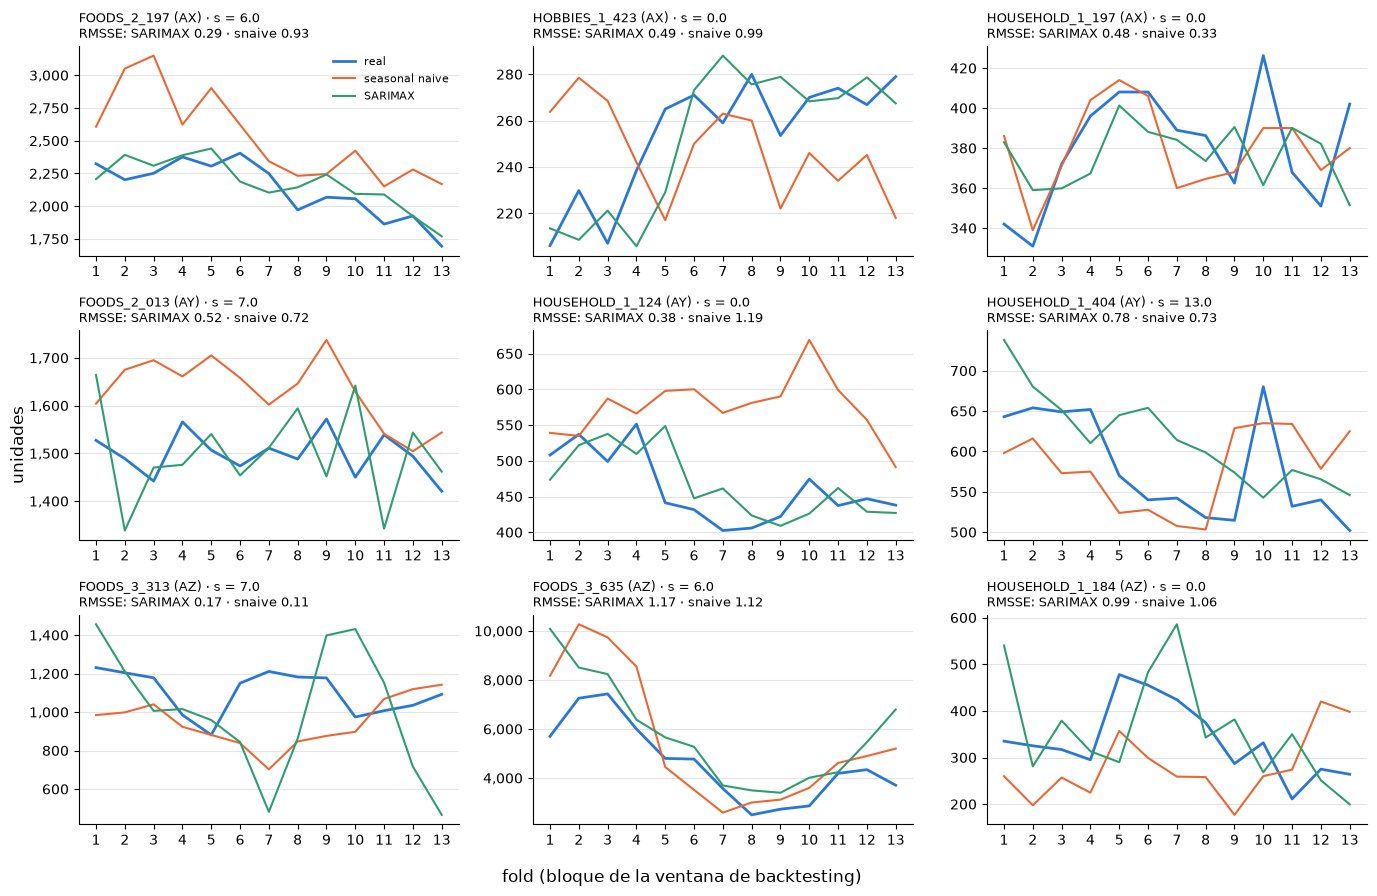

In [119]:
# Ventana de backtesting: real vs seasonal naive vs SARIMAX, 3 artículos al azar por segmento (con la semilla).
SARIMAX_COLOR = "#2f9e6e"
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(3, 3, figsize=(14, 9))
for row, cell in zip(axes, ["AX", "AY", "AZ"]):
    pool = sorted(ok_all.loc[ok_all["cell"] == cell, "item_id"])
    for ax, item in zip(row, sorted(rng.choice(pool, size=3, replace=False))):
        d = sarimax_valid[sarimax_valid["item_id"] == item].sort_values("fold")
        ax.plot(d["fold"], d["units"], color=REAL_COLOR, linewidth=2, label="real")
        ax.plot(d["fold"], d["snaive"], color=SNAIVE_COLOR, linewidth=1.5, label="seasonal naive")
        ax.plot(d["fold"], d["sarimax"], color=SARIMAX_COLOR, linewidth=1.5, label="SARIMAX")
        c = ok_all.set_index("item_id").loc[item]
        r = sarimax_item.loc[item]
        ax.set_title(f"{item} ({cell}) · s = {c['s']}\nRMSSE: SARIMAX {r['rmsse_sarimax']:.2f} · snaive {r['rmsse']:.2f}", fontsize=9, loc="left")
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
        ax.set_xticks(range(1, N_FOLDS + 1))
axes[0, 0].legend(frameon=False, fontsize=8)
fig.supxlabel("fold (bloque de la ventana de backtesting)")
fig.supylabel("unidades")
plt.tight_layout()
plt.show()

## Cierre

**Qué queda medido:** cuántos atípicos quitan los quiebres por tienda frente a la línea base (7.5), qué cambios estructurales se pierden (diagnóstico que usa el futuro), cuántos ratios extremos llegan al modelo, el flujo del nb 04 hasta el seasonal naive (Etapas 7–13) sobre la serie sumada y el SARIMAX por artículo con su backtesting de 13 folds (Etapa 14).
**Siguiente paso:** el boosting global (XGBoost, LightGBM y CatBoost), el filtro frente al seasonal naive y la selección por artículo. Este notebook no persiste resultados; solo deja las entradas de los nb 03c y 03d (13.3) y los puntos de control de la búsqueda SARIMAX (D1).
